# ClimRisk-LATAM: portafolios robustos condicionados al clima en mercados accionarios latinoamericanos
Cuaderno de replicación con datos reales

Este cuaderno implementa, de principio a fin, un modelo de selección de portafolios con optimización robusta en distribución (DRO) sobre bolas de Wasserstein de orden 2, en el que el clima entra por tres vías: (i) la medida nominal de escenarios, que pondera los meses históricos por la semejanza de su estado climático con el actual; (ii) la métrica del coste de transporte, que abarata los desplazamientos adversos en las direcciones de riesgo inducidas por las innovaciones climáticas filtradas con un modelo de estado; y (iii) el conjunto factible, que impone una senda de descarbonización alineada con los índices de referencia de la Unión Europea y un límite a la exposición física medida con datos. El modelo se evalúa con un protocolo de origen móvil en Brasil, México, Colombia y Chile (2018–2025, 96 meses), frente a cinco estrategias de referencia y al ETF de cada país.

Todas las series se descargan de su fuente oficial o se leen del archivo oficial que provee el usuario (Aqueduct). Ninguna celda genera datos aleatorios, sintéticos o de ejemplo: si una fuente falla, el cuaderno se detiene con un mensaje explícito. La única aleatoriedad es el remuestreo del bootstrap, que pertenece a la inferencia y no a los datos.

| Variable | Fuente | Acceso |
|---|---|---|
| Precios de 55 emisores | Yahoo Finance (barras mensuales ajustadas por dividendos, fin de mes) | Descarga automática |
| Tipos de cambio, materias primas, letra del Tesoro y ETF de país (EWZ, EWW, ECH, ICOLCAP) | Yahoo Finance (cierres diarios ajustados, último del mes) | Descarga automática |
| ENSO | NOAA PSL, Multivariate ENSO Index v2 (MEI v2) | Descarga automática |
| Anomalía térmica regional | NASA GISTEMP v4 vía NOAA PSL | Descarga automática |
| Precio del carbono | Banco Mundial, Carbon Pricing Dashboard, y normas oficiales (DIAN; Ley 20.780 de Chile) | Descarga automática |
| Riesgo hídrico | WRI Aqueduct 4.0, línea base anual | Zip oficial subido a Colab |
| Intensidad de transición (CI) | Prior experto de los autores, declarado | Embebida |
| Exposición física (PHYS) | Calculada: respuesta a la noticia ENSO y riesgo hídrico en las regiones de operación | Calculada |

Antes de ejecutar, suba a `/content` el zip de Aqueduct 4.0 (`aqueduct-4-0-water-risk-data.zip` o el zip que lo contiene). Tiempos aproximados en Colab: §E y §F0, unos minutos; §F1, del orden de 20 a 40 minutos; §F4, varias horas (del orden de tres a cinco); §F6, del orden de 20 minutos. Las secciones F4 y F6 pueden desactivarse con `RUN_F4` y `RUN_F6` y ejecutarse después sin repetir lo anterior.

## Estructura del cuaderno
| Sección | Contenido |
|---|---|
| §0 | Planteamiento del problema y notación |
| §1–§10 | Motor del modelo: protocolo, estado climático, modelo de estado, medida nominal, métrica, conjunto factible, optimización robusta, métricas, inferencia y backtest |
| §A | Funciones de análisis: ablaciones, frontera del radio, panel y figuras |
| §D | Datos documentales y funciones de descarga; medición del canal físico |
| §E | Carga de datos reales, exposiciones y ensamble por mercado |
| §F0 | Diagnósticos previos a la evaluación |
| §F1–§F7 | Resultados: backtest, conjunto factible y radio, inferencia, ablaciones, modelo de estado, robustez y exportación |
| §G | Anexo para la respuesta a los árbitros: estrategia y radio de la especificación original del manuscrito |
| Referencias | Fuentes metodológicas y de datos |

## §0. Planteamiento del problema y notación
En cada mercado $m$ un inversionista elige al cierre del mes $t$ un vector de pesos $w_t\in\mathcal W_t\subset\Delta^{N}$ (sin ventas en corto) para el mes $t+1$. Los retornos simples mensuales en USD son $r_{t+1}\in\mathbb R^N$ y la pérdida del portafolio es $\ell_w(r)=-w^\top r$. El criterio de riesgo es el valor en riesgo condicional al nivel $\alpha$,
$$\operatorname{CVaR}^Q_\alpha(\ell_w)=\min_{\tau\in\mathbb R}\Big\{\tau+\tfrac{1}{\alpha}\,\mathbb E_Q\big[(\ell_w(r)-\tau)^+\big]\Big\},$$
que es la media de las pérdidas en la cola del $\alpha\cdot100\,\%$ (Rockafellar y Uryasev, 2000). Como la distribución $Q$ del mes siguiente es desconocida, la decisión robusta minimiza el peor caso sobre una bola de ambigüedad centrada en una medida nominal $\hat P_t$:
$$w_t^\star=\arg\min_{w\in\mathcal W_t}\ \sup_{Q:\,W_2(Q,\hat P_t)\le\varepsilon_t}\operatorname{CVaR}^Q_\alpha(\ell_w),\qquad W_2(Q,P)=\Big(\inf_{\gamma\in\Gamma(Q,P)}\mathbb E_\gamma\big[(r-r')^\top M_t(r-r')\big]\Big)^{1/2}.$$
El clima interviene en tres objetos: la medida nominal $\hat P_t=\sum_s\pi_s(t)\,\delta_{r_s}$ (§4), la métrica de transporte $M_t$ (§5) y el conjunto factible $\mathcal W_t$ (§6). El radio $\varepsilon_t$ se elige por validación cruzada con información disponible en $t$ (§10). Interpretación económica: la bola de Wasserstein representa las distribuciones que el inversionista no puede descartar con la evidencia disponible; el clima determina qué escenarios históricos son relevantes hoy, en qué direcciones es más plausible el error de especificación y qué carteras son admisibles por su exposición climática.

In [ ]:
!pip install -q cvxpy clarabel ecos xarray netCDF4 #scikit-learn yfinance

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cvxpy as cp
from scipy import stats
from scipy.optimize import linprog
from sklearn.covariance import OAS
import warnings, collections
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

## §1. Protocolo de información y parámetros
La decisión de $t$ usa sólo información publicada al cierre de $t$. Los retornos accionarios, cambiarios y de materias primas del mes $t$ se conocen al cierre de $t$; las variables climáticas del mes $t$ (MEI, GISTEMP) se publican con rezago $\ell=$ `PUB_LAG` $=1$, de modo que en $t$ el último dato climático disponible es el de $t-\ell$. Las exposiciones físicas se reestiman al cierre de cada año con ventana expansiva; el modelo de estado se reestima al cierre de cada año con la información climática disponible. La primera decisión se toma al cierre de diciembre de 2017, de modo que el primer retorno evaluado es el de enero de 2018 y la evaluación cubre 96 meses. El rebalanceo es trimestral y los costes de transacción son proporcionales a la rotación.

La biblioteca de escenarios es expansiva: en $t$ contiene todos los meses completos de los activos invertibles desde enero de 2014. Una biblioteca larga es una condición necesaria para condicionar por el clima, porque el ciclo ENSO tiene una periodicidad de dos a siete años y una ventana de tres años rara vez contiene meses con un estado climático semejante al actual. Un activo es invertible en $t$ si tiene `WINDOW` meses completos y no está afectado por un evento corporativo. Todas las estrategias usan la misma biblioteca, de modo que las diferencias entre ellas se deben sólo a la medida nominal, a la métrica o al criterio de decisión.

In [ ]:
PARAMS = {
    # --- Muestra y protocolo de información ---
    'PRICE_START': '2014-01-01',  # primer retorno mensual de las acciones
    'CLIMATE_START': '2010-01-01',# primer mes del estado climático (carbono, temperatura, MEI, materias primas)
    'IS_END': '2017-12-31',       # cierre de la primera estimación (primera decisión)
    'OOS_START': '2018-01-01', 'OOS_END': '2025-12-31',    # evaluación de origen móvil (96 meses)
    'PUB_LAG': 1,                 # rezago de publicación de las variables climáticas (meses)
    'CURRENCY': 'USD',            # retornos en USD; tasa libre de riesgo: letra del Tesoro de EE. UU. a 13 semanas
    'REBAL_EVERY': 3,             # rebalanceo trimestral
    'LIBRARY': 'expanding',       # biblioteca de escenarios: 'expanding' (desde PRICE_START) o 'rolling' (WINDOW meses)
    'WINDOW': 36,                 # meses completos exigidos a un activo para ser invertible; longitud de la biblioteca móvil
    # --- Exposiciones físicas ---
    'PHYS_UPDATE': 'expanding',   # 'expanding': PHYS reestimado al cierre de cada año; 'fixed': una estimación en IS_END
    'ENSO_MIN_OBS': 36,           # meses mínimos para estimar la sensibilidad ENSO de un emisor
    'ENSO_LAGS': 3,               # rezagos de la noticia ENSO (dMEI_t, ..., dMEI_{t-L})
    'ENSO_MARKET_CONTROL': True,  # controla por el retorno del resto del mercado (exposición diferencial)
    'PHYS_KAPPA': 0.5,            # PHYS = kappa * phi_ENSO + (1 - kappa) * phi_agua
    # --- Modelo de estado ---
    'REESTIMATE_EVERY': 12,       # meses entre reestimaciones del modelo de estado (cierres de año)
    'STATE_TOL': 1e-10,           # desviación estándar mínima para conservar una componente del estado
    # --- Riesgo y radio ---
    'ALPHA': 0.05,                # nivel de cola del CVaR
    'EPS_GRID': [0.0, 0.01, 0.025, 0.05, 0.10, 0.20, 0.40, 0.80, 1.60, 3.20, 6.40, 12.80],
    'CV_VALID': 24,               # meses de validación para elegir eps
    'CV_MIN': 12,                 # mínimo de meses de validación (primeras fechas)
    'CV_ALPHA': 0.20,             # nivel de cola del criterio de validación (~5 observaciones de 24)
    # --- Condicionamiento climático ---
    'KERNEL_FEATURES': ('MEI', 'dMEI3', 'T_detr', 'Comm_r3'),
    'KERNEL_OMEGA': 0.5,          # mezcla uniforme/kernel: pi = (1-omega) u + omega k
    'KERNEL_H': 1.0,              # ancho de banda en unidades de Mahalanobis de los rasgos
    'EWMA_HALFLIFE': 6,           # semivida (meses) de la covarianza de las innovaciones climáticas
    'KAPPA_CLIM': 1.0,            # peso del bloque climático B Lambda B' en la métrica de transporte
    'RIDGE_BETA': 1.0,            # penalización ridge de las betas climáticas
    # --- Conjunto factible (Reglamento Delegado (UE) 2020/1818) ---
    'BENCH_REDUCTION': 0.50,      # 0.50 = PAB; 0.30 = CTB
    'DECARB_RATE': 0.07,          # autodescarbonización anual
    'PHYS_REDUCTION': 0.0,        # reducción de la exposición física frente al benchmark
    'W_MAX': 0.35,                # tope por activo (None para desactivar)
    'PHYS_SLACK': 0.10,           # límite físico acotado: PHYS_min + 10 % del margen hasta el benchmark
    'ENSO_THRESHOLD_MEI': 1.0,    # umbral |MEI| (unidades de MEI v2) para el endurecimiento físico
    'ENSO_ETA': 0.10,             # endurecimiento del límite físico en episodios ENSO
    # --- Costes ---
    'TC_BPS': 25,                 # coste de transacción por unidad de rotación (puntos básicos)
    # --- Inferencia ---
    'BOOT_B': 2000, 'BOOT_BLOCK': 'auto', 'BOOT_BLOCK_SENS': (3, 6, 12),
}


# Semilla usada exclusivamente por el bootstrap estacionario (remuestreo para inferencia).
SEED = 20261030


In [ ]:
PARAM_DESC = {
    'PRICE_START': 'Primer retorno accionario', 'CLIMATE_START': 'Primer mes del estado climático',
    'IS_END': 'Cierre de la primera estimación', 'OOS_START': 'Inicio de la evaluación fuera de muestra',
    'OOS_END': 'Fin de la evaluación', 'PUB_LAG': 'Rezago de publicación (meses)', 'CURRENCY': 'Moneda de los retornos',
    'REBAL_EVERY': 'Meses entre rebalanceos', 'LIBRARY': 'Biblioteca de escenarios (expansiva o móvil)',
    'WINDOW': 'Meses completos para invertir en un activo / biblioteca móvil',
    'PHYS_UPDATE': 'Actualización de PHYS', 'ENSO_MIN_OBS': 'Meses mínimos para la sensibilidad ENSO',
    'ENSO_LAGS': 'Rezagos de la noticia ENSO', 'ENSO_MARKET_CONTROL': 'Control por el retorno del resto del mercado',
    'PHYS_KAPPA': 'Peso de la componente ENSO en PHYS', 'REESTIMATE_EVERY': 'Meses entre reestimaciones del modelo de estado',
    'STATE_TOL': 'Desviación mínima de una componente del estado', 'ALPHA': 'Nivel de cola del CVaR',
    'EPS_GRID': 'Malla del radio (unidades de Mahalanobis)', 'CV_VALID': 'Meses de validación para eps',
    'CV_MIN': 'Mínimo de meses de validación', 'CV_ALPHA': 'Nivel de cola del criterio de validación',
    'KERNEL_FEATURES': 'Rasgos climáticos del kernel', 'KERNEL_OMEGA': 'Peso del kernel climático',
    'KERNEL_H': 'Ancho de banda del kernel', 'EWMA_HALFLIFE': 'Semivida EWMA de las innovaciones (meses)',
    'KAPPA_CLIM': 'Peso del bloque climático en la métrica', 'RIDGE_BETA': 'Penalización ridge de las betas climáticas',
    'BENCH_REDUCTION': 'Reducción de intensidad frente al benchmark', 'DECARB_RATE': 'Autodescarbonización anual',
    'PHYS_REDUCTION': 'Reducción de exposición física', 'W_MAX': 'Tope por activo',
    'PHYS_SLACK': 'Holgura del límite físico acotado', 'ENSO_THRESHOLD_MEI': 'Umbral |MEI| del endurecimiento físico',
    'ENSO_ETA': 'Endurecimiento físico en episodios ENSO', 'TC_BPS': 'Coste de transacción (pb)',
    'BOOT_B': 'Réplicas bootstrap', 'BOOT_BLOCK': 'Bloque medio del bootstrap (auto = Politis-White)',
    'BOOT_BLOCK_SENS': 'Bloques de sensibilidad del bootstrap',
}

def params_table(P=PARAMS):
    return pd.DataFrame([{'Parámetro': k, 'Valor': str(v), 'Definición': PARAM_DESC.get(k, '')} for k, v in P.items()])

def month_shift(t, k):
    """Fin del mes que está k meses antes de t (k >= 0)."""
    return pd.Timestamp(t) - pd.DateOffset(months=k) + pd.offsets.MonthEnd(0)

## §2. Estado climático: escalas naturales y rasgos estacionarios
El vector de estado de cada mercado agrupa el precio del carbono $P_C$ (USD/tCO$_2$e), la anomalía térmica regional $T$ (°C), el índice ENSO multivariado (MEI v2) y el precio de la materia prima dominante. Para el modelo de estado se usan escalas naturales no acotadas: $\operatorname{asinh}(P_C)$, que admite precios nulos y se comporta como $\log(2P_C)$ para precios altos; $\log(\text{Comm})$; y MEI y $T$ en niveles. Una componente sin variación en la muestra de estimación (por ejemplo, un precio explícito del carbono nulo en todo el periodo) se excluye del estado: no aporta información, y su inclusión vuelve singular la covarianza de transición $Q$ (§3).

La medida nominal (§4) no se condiciona sobre los niveles del estado, sino sobre rasgos estacionarios $f_t$: el nivel del MEI (fase ENSO), su cambio a tres meses (dirección de la fase), la anomalía térmica menos su tendencia lineal estimada con datos hasta $t-\ell$, y el retorno logarítmico de tres meses de la materia prima. La razón es estadística: si una variable tiene tendencia, $x_s=a+bs+u_s$, la distancia $|x_s-x_t|\approx|b|\,|t-s|$ mide cercanía en el tiempo y no semejanza del estado, de modo que un kernel sobre niveles tendenciales equivale a ponderar por recencia. El precio del carbono se excluye de los rasgos porque varía por decisiones de política discretas (cambios anuales de tarifa) que no definen estados climáticos comparables entre meses.

In [ ]:
def transform_state(raw: pd.DataFrame) -> pd.DataFrame:
    """Variables del modelo de estado en escalas naturales no acotadas:
    P_C (USD/t, admite 0) -> asinh;  Comm (precio) -> log;  MEI y T_anom en niveles."""
    if (raw['Comm'].dropna() <= 0).any():
        raise ValueError('Comm contiene precios <= 0; log(Comm) no está definido. Revise la serie de la materia prima.')
    out = pd.DataFrame(index=raw.index)
    out['P_C'] = np.arcsinh(raw['P_C'])
    out['T_anom'] = raw['T_anom']
    out['ENSO'] = raw['MEI']
    out['Comm'] = np.log(raw['Comm'])
    return out

def informative_columns(X: pd.DataFrame, tol=1e-10):
    """Componentes con variación en la muestra de estimación. Una componente constante (p. ej., un precio del carbono
    nulo durante toda la muestra) no aporta información, vuelve singular la covarianza de transición Q y se excluye."""
    keep, drop = [], []
    for c in X:
        s = X[c].dropna()
        (keep if (s.nunique() > 1 and s.std(ddof=1) > tol) else drop).append(c)
    return keep, drop

def kernel_features(raw: pd.DataFrame, t_info, features=('MEI', 'dMEI3', 'T_detr', 'Comm_r3')):
    """Rasgos estacionarios del estado climático con la información disponible hasta t_info:
       MEI        nivel del índice (fase ENSO; estacionario),
       dMEI3      cambio del MEI en 3 meses (dirección de la fase),
       T_detr     anomalía térmica menos su tendencia lineal estimada con datos hasta t_info,
       Comm_r3    retorno logarítmico de 3 meses de la materia prima dominante.
    Los niveles con tendencia (temperatura, log-precio, precio del carbono) se excluyen: una distancia entre niveles
    tendenciales mide cercanía en el tiempo, no semejanza del estado climático."""
    Z = raw.loc[:t_info]
    mei = Z['MEI']; ta = Z['T_anom']; lc = np.log(Z['Comm'])
    x = np.arange(len(ta), dtype=float); ok = ta.notna().values
    tdet = pd.Series(np.nan, index=ta.index)
    if ok.sum() > 2:
        b = np.polyfit(x[ok], ta.values[ok], 1); tdet = ta - np.polyval(b, x)
    F = pd.DataFrame({'MEI': mei, 'dMEI3': mei - mei.shift(3), 'T_detr': tdet, 'Comm_r3': lc - lc.shift(3)})
    return F[list(features)].dropna()

## §3. Modelo de estado lineal-gaussiano
Sea $y_t\in\mathbb R^k$ el estado climático estandarizado. El modelo es
$$x_t=c+\Phi x_{t-1}+\eta_t,\quad \eta_t\sim\mathcal N(0,Q);\qquad y_t=x_t+v_t,\quad v_t\sim\mathcal N(0,R),\ R\ \text{diagonal}.$$
El filtro de Kalman produce la predicción $x_{t\mid t-1}$, la innovación $\nu_t=y_t-x_{t\mid t-1}$ con covarianza $S_t=P_{t\mid t-1}+R$, la ganancia $K_t=P_{t\mid t-1}S_t^{-1}$ y la actualización $x_{t\mid t}=x_{t\mid t-1}+K_t\nu_t$. Con observaciones faltantes en una componente (por ejemplo, años sin dato del precio del carbono) la actualización usa sólo las filas observadas. Los parámetros $(c,\Phi,Q,R)$ se estiman por el algoritmo EM de Shumway y Stoffer (1982): el paso E calcula los momentos suavizados con el suavizador de Rauch–Tung–Striebel y el paso M actualiza los parámetros en forma cerrada; el radio espectral de $\Phi$ se acota en 0,97 para garantizar estacionariedad (Durbin y Koopman, 2012).

Las innovaciones $\nu_t$ son la noticia climática del mes: la parte de la observación no anticipada por el modelo. Son el objeto que transmite el clima a los retornos en la métrica de transporte (§5). Si una componente es constante, su varianza suavizada es nula, el paso M lleva $Q_{jj}$ y $R_{jj}$ a cero y la verosimilitud deja de estar acotada; por eso se excluye antes de estimar y se reporta el número de condición de $Q$. En un sistema invariante, $P_{t\mid t}$ converge a la solución estacionaria de la ecuación de Riccati con independencia de los datos (§F5); la información dependiente de los datos está en $\nu_t$.

In [ ]:
def kalman_filter(Y, c, Phi, Q, R, x0, P0):
    """Filtro de Kalman con H = I y observaciones faltantes por componente (NaN)."""
    T, k = Y.shape
    xp = np.zeros((T, k)); Pp = np.zeros((T, k, k))
    xf = np.zeros((T, k)); Pf = np.zeros((T, k, k))
    nu = np.full((T, k), np.nan); loglik = 0.0
    x, P = x0.copy(), P0.copy()
    for t in range(T):
        x = c + Phi @ x; P = Phi @ P @ Phi.T + Q
        xp[t], Pp[t] = x, P
        obs = ~np.isnan(Y[t])
        if obs.any():
            Hm = np.eye(k)[obs]
            S = Hm @ P @ Hm.T + R[np.ix_(obs, obs)]
            K = np.linalg.solve(S, Hm @ P).T
            v = Y[t, obs] - Hm @ x
            x = x + K @ v; P = (np.eye(k) - K @ Hm) @ P
            nu[t, obs] = v
            _, logdet = np.linalg.slogdet(S)
            loglik += -0.5 * (obs.sum() * np.log(2 * np.pi) + logdet + v @ np.linalg.solve(S, v))
        xf[t], Pf[t] = x, P
    return dict(xp=xp, Pp=Pp, xf=xf, Pf=Pf, nu=nu, loglik=loglik)

def rts_smoother(kf, Phi):
    xf, Pf, xp, Pp = kf['xf'], kf['Pf'], kf['xp'], kf['Pp']
    T, k = xf.shape
    xs = xf.copy(); Ps = Pf.copy(); J = np.zeros((T, k, k))
    for t in range(T - 2, -1, -1):
        J[t] = Pf[t] @ Phi.T @ np.linalg.inv(Pp[t + 1])
        xs[t] = xf[t] + J[t] @ (xs[t + 1] - xp[t + 1])
        Ps[t] = Pf[t] + J[t] @ (Ps[t + 1] - Pp[t + 1]) @ J[t].T
    return xs, Ps, J

def fit_state_space_em(Y, names=None, n_iter=200, tol=1e-6, rho_max=0.97):
    """EM de Shumway y Stoffer (1982) para (c, Phi, Q, R diagonal) con H = I y datos faltantes."""
    Y = np.asarray(Y, float); Y[~np.isfinite(Y)] = np.nan; T, k = Y.shape
    names = list(names) if names is not None else [str(j) for j in range(k)]
    empty = [names[j] for j in range(k) if np.isnan(Y[:, j]).all()]
    if empty:
        raise ValueError(f'Componentes del estado sin datos finitos en la ventana: {empty}. '
                         'Causa habitual: índices de fecha no alineados (zona horaria o día del mes); use to_month_end.')
    if T < 2 * k + 2:
        raise ValueError(f'Ventana de estimación demasiado corta para el modelo de estado: T = {T}.')
    Yf = pd.DataFrame(Y).ffill().bfill().values
    A = np.column_stack([np.ones(T - 1), Yf[:-1]]); B = np.linalg.lstsq(A, Yf[1:], rcond=None)[0]
    c, Phi = B[0], B[1:].T
    E = Yf[1:] - A @ B; Q = np.atleast_2d(np.cov(E.T))ewz * 0.5 + 1e-6 * np.eye(k)
    R = np.diag(np.diag(np.atleast_2d(np.cov(E.T))) * 0.5 + 1e-6)
    x0, P0 = Yf[0].copy(), np.eye(k)
    ll_old = -np.inf
    for it in range(n_iter):
        rho = np.max(np.abs(np.linalg.eigvals(Phi)))
        if rho > rho_max: Phi = Phi * rho_max / rho
        kf = kalman_filter(Y, c, Phi, Q, R, x0, P0)
        xs, Ps, J = rts_smoother(kf, Phi)
        S11 = sum(Ps[t] + np.outer(xs[t], xs[t]) for t in range(1, T))
        S00 = sum(Ps[t] + np.outer(xs[t], xs[t]) for t in range(0, T - 1))
        S10 = sum(Ps[t] @ J[t - 1].T + np.outer(xs[t], xs[t - 1]) for t in range(1, T))
        s1 = xs[1:].sum(0); s0 = xs[:-1].sum(0); n = T - 1
        M = np.block([[np.array([[n]]), s0[None, :]], [s0[:, None], S00]])
        Rhs = np.column_stack([s1, S10])
        Bt = np.linalg.solve(M.T, Rhs.T).T; c, Phi = Bt[:, 0], Bt[:, 1:]
        Q = (S11 - Bt @ Rhs.T - Rhs @ Bt.T + Bt @ M @ Bt.T) / n
        Q = 0.5 * (Q + Q.T) + 1e-8 * np.eye(k)
        rdiag = np.zeros(k)
        for j in range(k):
            o = ~np.isnan(Y[:, j])
            rdiag[j] = np.mean((Y[o, j] - xs[o, j]) ** 2 + Ps[o, j, j])
        R = np.diag(np.maximum(rdiag, 1e-6))
        x0, P0 = xs[0], Ps[0] + 1e-6 * np.eye(k)
        if abs(kf['loglik'] - ll_old) < tol * (1 + abs(ll_old)): break
        ll_old = kf['loglik']
    rho = np.max(np.abs(np.linalg.eigvals(Phi)))
    if rho > rho_max: Phi = Phi * rho_max / rho
    return dict(c=c, Phi=Phi, Q=Q, R=R, x0=x0, P0=P0, loglik=kf['loglik'], n_iter=it + 1, names=names,
                rho=float(np.max(np.abs(np.linalg.eigvals(Phi)))), cond_Q=float(np.linalg.cond(Q)))

def fit_climate_state(Zt: pd.DataFrame, t_end, tol=1e-10):
    """Estima el modelo de estado con la información hasta t_end: excluye componentes constantes, estandariza con
    media y desviación de la muestra de estimación y ajusta por EM. Devuelve el modelo y su escala."""
    hist = Zt.loc[:t_end]
    keep, drop = informative_columns(hist, tol)
    mu, sd = hist[keep].mean(), hist[keep].std(ddof=1)
    mdl = fit_state_space_em(((hist[keep] - mu) / sd).values, names=keep)
    mdl.update(cols=keep, dropped=drop, mu=mu, sd=sd, t_end=pd.Timestamp(t_end))
    return mdl

def filter_climate_state(mdl, Zt: pd.DataFrame, t_info):
    """Filtra con un modelo ya estimado los datos disponibles hasta t_info; devuelve estados e innovaciones."""
    hist = Zt.loc[:t_info, mdl['cols']]; Zs = (hist - mdl['mu']) / mdl['sd']
    kf = kalman_filter(Zs.values, mdl['c'], mdl['Phi'], mdl['Q'], mdl['R'], mdl['x0'], mdl['P0'])
    return (pd.DataFrame(kf['xf'], index=hist.index, columns=mdl['cols']),
            pd.DataFrame(kf['nu'], index=hist.index, columns=mdl['cols']), kf)

def riccati_report(model, T):
    """Trayectoria de tr(P_t|t) sin datos faltantes: en un sistema invariante es determinista."""
    k = len(model['c']); P = model['P0'].copy(); tr = []
    for _ in range(T):
        P = model['Phi'] @ P @ model['Phi'].T + model['Q']
        K = P @ np.linalg.inv(P + model['R']); P = (np.eye(k) - K) @ P
        tr.append(np.trace(P))
    return np.array(tr)

## §4. Medida nominal condicionada al clima
La medida nominal asigna a cada escenario histórico $s$ de la biblioteca un peso
$$\pi_s(t)=\frac{1-\omega}{n}+\omega\,\frac{K\big(d_s/h\big)}{\sum_{u}K\big(d_u/h\big)},\qquad d_s^2=\big(f_{s-1-\ell}-f_{t-\ell}\big)^\top S_f^{-1}\big(f_{s-1-\ell}-f_{t-\ell}\big),$$
con $K(u)=e^{-u^2/2}$, $S_f$ la covarianza de los rasgos y $\omega\in[0,1]$. El emparejamiento temporal es simétrico: el escenario $r_s$ (retorno del mes $s$, decidido al cierre de $s-1$) se compara a través de los rasgos conocidos en $s-1$, es decir $f_{s-1-\ell}$, del mismo modo que la decisión de $t$ conoce $f_{t-\ell}$. El componente de kernel es un estimador de Nadaraya–Watson de la distribución condicional de los retornos dado el estado climático (Nadaraya, 1964; Watson, 1964); la mezcla con la medida uniforme evita que la masa se concentre en pocos meses. El tamaño muestral efectivo de Kish, $\text{ESS}=1/\sum_s\pi_s^2$, mide esa concentración: vale $n$ con pesos uniformes y, con $\omega=0{,}5$, no baja de $1/\big[(n-1)\big(\tfrac{1-\omega}{n}\big)^2+\big(\tfrac{1-\omega}{n}+\omega\big)^2\big]\approx3{,}8$ aunque el kernel concentre toda su masa en un solo mes.

Interpretación económica: si hoy el Pacífico está en una fase cálida que se intensifica, los meses históricos con esa misma fase reciben más peso al evaluar la cola de pérdidas. Con $\omega=0$ se recupera la medida empírica uniforme.

In [ ]:
def climate_kernel_weights(X_hist, x_now, S_inv, h=1.0, omega=0.5):
    """pi_s = (1 - omega)/n + omega K(d_s/h) / sum K, con d_s la distancia de Mahalanobis entre los rasgos climáticos
    del escenario s y los actuales. Filas sin rasgos reciben sólo la masa uniforme."""
    X_hist = np.asarray(X_hist, float); n = len(X_hist)
    ok = np.isfinite(X_hist).all(1)
    D = np.where(ok[:, None], X_hist - x_now, 0.0)
    d2 = np.einsum('ti,ij,tj->t', D, S_inv, D)
    k = np.where(ok, np.exp(-0.5 * d2 / h ** 2), 0.0)
    k = k / k.sum() if k.sum() > 0 else np.full(n, 1.0 / n)
    return (1 - omega) / n + omega * k

def ess(pi):
    """Tamaño muestral efectivo de Kish: 1 / sum pi_s^2 (n con pesos uniformes)."""
    return 1.0 / np.sum(np.asarray(pi) ** 2)

## §5. Métrica de transporte con un bloque climático
El coste de transporte es $c(r,r')=(r-r')^\top M_t(r-r')$ con
$$M_t^{-1}=\Sigma_t^{\text{OAS}}+\kappa\,B_t\Lambda_tB_t^\top .$$
$\Sigma_t^{\text{OAS}}$ es la covarianza de la biblioteca con contracción OAS (Chen, Wiesel, Eldar y Hero, 2010); $B_t$ ($N\times k$) son las betas de los retornos frente a las innovaciones climáticas estandarizadas, estimadas por regresión ridge con los meses de la biblioteca cuya innovación ya se publicó; y $\Lambda_t$ es la covarianza EWMA de las innovaciones (semivida de seis meses). Ambos sumandos están en unidades de retorno al cuadrado. Como el coste de un desplazamiento $\delta$ es $\delta^\top M_t\delta$, las direcciones con mayor varianza de origen climático son más baratas para el adversario: la bola de Wasserstein se alarga en las direcciones por las que el clima puede mover conjuntamente los retornos. Con $\kappa=0$ la métrica es la de Mahalanobis de la covarianza OAS. Se reporta la participación del bloque climático en la traza de $M_t^{-1}$.

In [ ]:
def climate_betas(R_win, NU_win, ridge=1.0):
    """B (N x k): sensibilidad de los retornos a las innovaciones climáticas estandarizadas (ridge)."""
    X = NU_win - NU_win.mean(0); Yc = R_win - R_win.mean(0)
    k = X.shape[1]
    return np.linalg.solve(X.T @ X + ridge * np.eye(k), X.T @ Yc).T

def transport_metric(Rw, NUw=None, Lam=None, kappa=1.0, ridge=1.0, Rb=None):
    """M^{-1} = Sigma_OAS + kappa B Lambda B'. Sigma_OAS se estima con toda la biblioteca Rw; las betas B con los meses
    Rb para los que ya se publicó la innovación climática. Devuelve G (G G' = M^{-1}) y la participación del bloque
    climático en la traza de M^{-1}."""
    S = OAS().fit(Rw).covariance_
    if NUw is None or kappa == 0 or NUw.shape[1] == 0:
        Minv = S; share = 0.0
    else:
        B = climate_betas(Rw[:len(NUw)] if Rb is None else Rb, NUw, ridge)
        C = kappa * B @ Lam @ B.T; Minv = S + C; share = float(np.trace(C) / np.trace(Minv))
    Na = Minv.shape[0]
    return np.linalg.cholesky(0.5 * (Minv + Minv.T) + 1e-10 * np.eye(Na)), share

## §6. Conjunto factible
El conjunto factible combina una restricción de transición y una física:
$$\mathcal W_t=\Big\{w\ge0,\ \mathbf 1^\top w=1,\ w\le w_{\max},\ \ \text{CI}^\top w\le(1-\rho)(1-g)^{\tau_t}\,\text{CI}^\top b,\ \ \text{PHYS}^\top w\le(1-\rho_F)\big(1-\eta\,\mathbb 1\{|\text{MEI}_{t-\ell}|>\bar m\}\big)\,\text{PHYS}^\top b\Big\},$$
con $b$ los pesos del benchmark (equiponderado), $\rho=0{,}5$ y $g=0{,}07$ (reducción inicial y autodescarbonización anual de un índice alineado con el Acuerdo de París, Reglamento Delegado (UE) 2020/1818; $\rho=0{,}3$ corresponde a un índice de transición climática) y $\tau_t$ los años transcurridos desde el inicio de la evaluación. El límite físico se endurece en un $\eta=10\,\%$ en episodios ENSO fuertes. Si el límite físico objetivo es menor que el mínimo alcanzable dado el límite de transición y el tope, se fija en el mínimo más una holgura del 10 % del margen hasta el benchmark; sólo si el conjunto sigue vacío se relaja, con registro, primero el tope y después la restricción física. Reescalar las exposiciones por un factor común en ambos lados de una restricción no la modifica (homogeneidad de grado uno), por lo que no se aplica. Se reportan, por fecha y estrategia, las holguras de cada restricción: una restricción que nunca está activa no condiciona las carteras.

In [ ]:
def feasible_limits(chi, bench_w, years_since_base, P=PARAMS, mei_now=0.0):
    """chi: (2, N) [CI, PHYS]; bench_w: pesos del benchmark.
    Transición: CI'w <= (1 - reducción)(1 - g)^años CI_bench (Reglamento Delegado (UE) 2020/1818).
    Física: PHYS'w <= (1 - PHYS_REDUCTION)(1 - eta 1{|MEI| > umbral}) PHYS_bench."""
    ci_b, ph_b = chi @ bench_w
    lim_ci = (1 - P['BENCH_REDUCTION']) * (1 - P['DECARB_RATE']) ** years_since_base * ci_b
    lim_ph = (1 - P['PHYS_REDUCTION']) * ph_b * (1 - P['ENSO_ETA'] * (abs(mei_now) > P['ENSO_THRESHOLD_MEI']))
    return np.array([lim_ci, lim_ph])

def feasible_set_report(chi, lim, names, w_max=None):
    """Peso máximo alcanzable por activo (programación lineal), N_eff máximo (programa cuadrático) y factibilidad."""
    N = chi.shape[1]; out = []
    for i in range(N):
        cobj = np.zeros(N); cobj[i] = -1
        r = linprog(cobj, A_ub=chi, b_ub=lim, A_eq=np.ones((1, N)), b_eq=[1], bounds=[(0, w_max)] * N, method='highs')
        out.append(-r.fun if r.status == 0 else np.nan)
    w = cp.Variable(N); cons = [cp.sum(w) == 1, w >= 0, chi @ w <= lim]
    if w_max is not None: cons.append(w <= w_max)
    pr = cp.Problem(cp.Minimize(cp.sum_squares(w)), cons)
    for _s in (cp.CLARABEL, cp.ECOS, cp.SCS):
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Solution may be inaccurate')
                pr.solve(solver=_s)
        except (cp.error.SolverError, KeyError):
            continue
        if pr.status == 'optimal': break
    neff = 1 / np.sum(w.value ** 2) if w.value is not None else np.nan
    return pd.Series(out, index=names, name='w_max_alcanzable'), neff, pr.status

## §7. Peor caso de Wasserstein-2 del CVaR: forma cerrada
Proposición. Sea $M\succ0$ con $M^{-1}=GG^\top$, $\hat P=\sum_s\pi_s\delta_{r_s}$ y $\ell_w(r)=-w^\top r$. Entonces, para todo $\varepsilon\ge0$,
$$\sup_{Q:\,W_2(Q,\hat P)\le\varepsilon}\operatorname{CVaR}^Q_\alpha(\ell_w)=\operatorname{CVaR}^{\hat P}_\alpha(\ell_w)+\frac{\varepsilon}{\sqrt\alpha}\,\|G^\top w\|_2 .$$
Esbozo de la demostración. Cota superior: para $Q$ en la bola existe un acoplamiento con $\mathbb E\|r'-r\|_M^2\le\varepsilon^2$; por Cauchy–Schwarz, $\ell_w(r')-\ell_w(r)=-w^\top(r'-r)\le\|G^\top w\|_2\,\|r'-r\|_M$. Con la representación dual $\operatorname{CVaR}_\alpha(\ell)=\sup\{\mathbb E[\zeta\ell]:0\le\zeta\le1/\alpha,\ \mathbb E\zeta=1\}$ y $\mathbb E\zeta^2\le1/\alpha$, se obtiene $\operatorname{CVaR}^Q_\alpha\le\operatorname{CVaR}^{\hat P}_\alpha+\|G^\top w\|_2\,\varepsilon/\sqrt\alpha$. Cota alcanzada: desplazar la masa $\alpha$ de la cola de $\hat P$ en la dirección $\delta=-c\,M^{-1}w/\|G^\top w\|_2$, con $c=\varepsilon/\sqrt\alpha$, cuesta $\alpha c^2=\varepsilon^2$ y aumenta cada pérdida de la cola en $c\,\|G^\top w\|_2$. El resultado coincide con el dual de Lagrange de los problemas de Wasserstein (Blanchet y Murthy, 2019; Gao y Kleywegt, 2023; Kuhn et al., 2019), lo que se verifica numéricamente en §F0.

El problema robusto es entonces el programa cónico de segundo orden
$$\min_{w\in\mathcal W_t,\ \tau,\ s\ge0}\ \tau+\frac1\alpha\sum_s\pi_s s_s+\frac{\varepsilon}{\sqrt\alpha}\,\|G^\top w\|_2\quad\text{s.a.}\quad s_s\ge-r_s^\top w-\tau .$$
Esta forma no contiene el multiplicador $\lambda$ del dual, cuyo valor óptimo $\lambda^\star=\|G^\top w\|_2/(2\varepsilon\sqrt\alpha)$ tiende a cero cuando $\varepsilon$ crece y degrada el escalamiento numérico de la restricción $q\ge\|G^\top w\|^2/(4\lambda\alpha^2)$.

Interpretación económica. El peor caso es el CVaR nominal más una penalización proporcional a la volatilidad del portafolio medida con la métrica $M^{-1}$. El radio $\varepsilon$ es el desplazamiento cuadrático medio que se concede al adversario, en unidades de Mahalanobis. Con $\varepsilon\to0$ la decisión minimiza el CVaR ponderado por $\pi$, y el clima actúa a través de qué escenarios forman la cola; con $\varepsilon\to\infty$ la decisión converge a la cartera de mínima varianza bajo $\Sigma^{\text{OAS}}+\kappa B\Lambda B^\top$, y el clima actúa sólo a través de la métrica. La participación de la penalización en el objetivo, que se reporta en §F2, indica en cuál de los dos regímenes opera el modelo.

In [ ]:
class SolverFailure(RuntimeError):
    pass

SOLVER_STATS = collections.Counter()

def _base_cons(w, chi, lim, w_max):
    cons = [cp.sum(w) == 1, w >= 0]
    if chi is not None: cons.append(chi @ w <= lim)
    if w_max is not None: cons.append(w <= w_max)
    return cons

def _solve(prob, w):
    """CLARABEL -> ECOS -> SCS. Una solución 'optimal_inaccurate' sólo se acepta si ningún solver devuelve 'optimal'."""
    fallback = None
    for s in (cp.CLARABEL, cp.ECOS, cp.SCS):
        if s not in cp.installed_solvers(): continue
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Solution may be inaccurate')
                prob.solve(solver=s)
        except cp.error.SolverError:
            continue
        if w.value is None: continue
        wv = np.clip(w.value, 0, None); wv = wv / wv.sum()
        if prob.status == 'optimal':
            SOLVER_STATS['optimal_' + s] += 1
            if fallback is not None: SOLVER_STATS['reintento'] += 1
            return wv, s, prob.status
        if prob.status == 'optimal_inaccurate' and fallback is None:
            fallback = (wv, s, prob.status)
    if fallback is not None:
        SOLVER_STATS['inexacta_aceptada'] += 1; return fallback
    raise SolverFailure(f'Estado del problema: {prob.status}')

def worst_case_cvar(Rw, pi, G, w, eps, alpha):
    """sup_{Q: W2(Q, P_pi) <= eps} CVaR_alpha^Q(-w'r) = CVaR_alpha^{P_pi}(-w'r) + (eps/sqrt(alpha)) ||G'w||_2."""
    loss = -Rw @ w; o = np.argsort(-loss); cum = np.cumsum(pi[o])
    tail = np.minimum(pi[o], np.maximum(alpha - np.r_[0, cum[:-1]], 0))
    cvar = float(tail @ loss[o]) / alpha
    return cvar + eps / np.sqrt(alpha) * float(np.linalg.norm(G.T @ w))

def dro_cvar_w2(Rw, pi, G, eps, alpha, chi=None, lim=None, w_max=None):
    """min_w  tau + alpha^{-1} sum_s pi_s s_s + (eps/sqrt(alpha)) ||G'w||_2
       s.a.   s_s >= -r_s'w - tau,  s_s >= 0,  w en el conjunto factible.
    Programa cónico de segundo orden equivalente al dual de Lagrange del problema de Wasserstein-2 con coste
    c(r, r') = (r - r')' M (r - r'), M^{-1} = G G' (ver dro_cvar_w2_dual)."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    cons = _base_cons(w, chi, lim, w_max) + [s >= -Rw @ w - tau]
    obj = tau + (pi @ s) / alpha
    if eps > 0: obj = obj + (eps / np.sqrt(alpha)) * cp.norm(G.T @ w, 2)
    prob = cp.Problem(cp.Minimize(obj), cons)
    wv, solver, status = _solve(prob, w)
    pen = eps / np.sqrt(alpha) * float(np.linalg.norm(G.T @ wv))
    return wv, dict(obj=float(prob.value), penalty=pen, cvar_term=float(prob.value) - pen, solver=solver, status=status)

def dro_cvar_w2_dual(Rw, pi, G, eps, alpha, chi=None, lim=None, w_max=None):
    """Dual de Lagrange (Blanchet y Murthy, 2019; Gao y Kleywegt, 2023), usado sólo para verificar la forma cerrada:
      min lam eps^2 + tau + sum pi_s s_s,  s_s >= 0,  s_s >= (-r_s'w - tau)/alpha + q,  q >= ||G'w||^2/(4 lam alpha^2)."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    lam = cp.Variable(nonneg=True); q = cp.Variable()
    cons = _base_cons(w, chi, lim, w_max) + [q >= cp.quad_over_lin(G.T @ w, lam) / (4 * alpha ** 2),
                                              s >= (-Rw @ w - tau) / alpha + q]
    prob = cp.Problem(cp.Minimize(lam * eps ** 2 + tau + pi @ s), cons)
    wv, solver, status = _solve(prob, w)
    return wv, dict(obj=float(prob.value), lam=float(lam.value), solver=solver, status=status)

def dro_paper(Rw, eps, alpha, chi, lim, w_max=None):
    """Especificación original del manuscrito (anexo §G): CVaR empírico + eps ||w||_2, con medida uniforme y métrica
    euclidiana. Difiere del peor caso exacto con G = I, CVaR + (eps/sqrt(alpha)) ||w||_2, en el factor alpha^{-1/2}."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    cons = _base_cons(w, chi, lim, w_max) + [s >= -Rw @ w - tau]
    prob = cp.Problem(cp.Minimize(tau + cp.sum(s) / (n * alpha) + eps * cp.norm(w, 2)), cons)
    wv, solver, status = _solve(prob, w)
    return wv, dict(obj=float(prob.value), solver=solver, status=status)

def mvo_oas(Rw, chi, lim, w_max=None):
    S = OAS().fit(Rw).covariance_; N = Rw.shape[1]
    w = cp.Variable(N)
    prob = cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))), _base_cons(w, chi, lim, w_max))
    wv, solver, _ = _solve(prob, w); return wv, dict(solver=solver)

def constrained_equal_weight(N, chi, lim, w_max=None):
    """Proyección euclidiana de 1/N sobre el conjunto factible."""
    w = cp.Variable(N)
    prob = cp.Problem(cp.Minimize(cp.sum_squares(w - 1.0 / N)), _base_cons(w, chi, lim, w_max))
    wv, solver, _ = _solve(prob, w); return wv, dict(solver=solver)

## §8. Métricas de desempeño, rotación y costes
Para una serie de retornos netos mensuales $\{r_t\}_{t=1}^T$: rendimiento geométrico anual $\big(\prod_t(1+r_t)\big)^{12/T}-1$; volatilidad anual $\sqrt{12}\,\hat\sigma$; razón de Sharpe anual $\sqrt{12}\,\overline{(r-r^f)}/\hat\sigma_{r-r^f}$ con la letra del Tesoro a 13 semanas; CVaR empírico al 5 % y al 10 % (media de los retornos en la cola, con signo cambiado); y caída máxima. La rotación de un rebalanceo es $\|w_t-\tilde w_{t^-}\|_1$, con $\tilde w_{t^-}$ los pesos tras la deriva de precios desde el rebalanceo anterior, y el coste es de 25 pb por unidad de rotación. La diversificación se mide con $N_{\text{eff}}=1/\sum_iw_i^2$.

In [ ]:
def portfolio_path(weights: pd.DataFrame, R: pd.DataFrame, tc_bps=25):
    """weights: pesos decididos al cierre de t (índice = fecha de decisión) aplicados desde t+1; deriva intra-periodo."""
    dates = weights.index; rows = []; w_prev_drift = None
    for d, nxt in zip(dates[:-1], dates[1:]):
        w = weights.loc[d].values
        period = R.loc[(R.index > d) & (R.index <= nxt)]
        turn = np.abs(w - w_prev_drift).sum() if w_prev_drift is not None else np.abs(w).sum()
        cost = tc_bps / 1e4 * turn
        wd = w.copy(); first = True
        for t, r in period.iterrows():
            gross = float(wd @ r.values)
            rows.append({'date': t, 'gross': gross, 'net': gross - (cost if first else 0.0),
                         'turnover': turn if first else 0.0, 'neff': 1 / np.sum(w ** 2)})
            wd = wd * (1 + r.values); wd = wd / wd.sum(); first = False
        w_prev_drift = wd
    return pd.DataFrame(rows).set_index('date')

def perf_metrics(r: pd.Series, rf: pd.Series = None, alpha=0.05):
    r = r.dropna()
    if len(r) < 12:
        raise ValueError(f'perf_metrics: sólo {len(r)} meses válidos (se requieren >= 12); revise la alineación de fechas.')
    ex = r - (rf.reindex(r.index).fillna(0) if rf is not None else 0.0)
    q = np.quantile(r, alpha); cvar = -r[r <= q].mean()
    wealth = (1 + r).cumprod(); mdd = (wealth / wealth.cummax() - 1).min()
    ann_geo = wealth.iloc[-1] ** (12 / len(r)) - 1
    return {'Ret. geom. anual (%)': 100 * ann_geo, 'Vol. anual (%)': 100 * r.std(ddof=1) * np.sqrt(12),
            'Sharpe (anual)': np.sqrt(12) * ex.mean() / ex.std(ddof=1),
            f'CVaR{int(alpha*100)}% mensual (%)': 100 * cvar,
            'CVaR10% mensual (%)': 100 * -r[r <= np.quantile(r, 0.10)].mean(),
            'MaxDD (%)': 100 * mdd, 'N meses': len(r)}

## §9. Inferencia
Las diferencias de desempeño se evalúan sobre las mismas fechas. El bootstrap estacionario de Politis y Romano (1994) remuestrea bloques de longitud geométrica con media $b$, lo que preserva la dependencia serial y el agrupamiento de volatilidad que determinan la distribución muestral del CVaR. La longitud media se elige con el criterio automático de Politis y White (2004), con la corrección de Patton, Politis y White (2009):
$$\hat b=\Big(\frac{2\hat G^2}{\hat D}\Big)^{1/3}T^{1/3},\qquad \hat G=\sum_{|k|\le M}\lambda(k/M)\,|k|\,\hat\gamma_k,\qquad \hat D=2\Big(\sum_{|k|\le M}\lambda(k/M)\,\hat\gamma_k\Big)^2,$$
con núcleo trapezoidal $\lambda$. Para cada par de estrategias se usa el máximo de $\hat b$ entre ambas series, su diferencia y el cuadrado de la diferencia; se reporta además la sensibilidad a bloques fijos de 3, 6 y 12 meses. Con $T=96$, un bloque de 12 meses deja unos ocho bloques independientes, por lo que los intervalos se ensanchan: alargar el bloque no aumenta la potencia.

Se reportan intervalos percentiles al 95 %, un p-valor unilateral a favor del modelo propuesto y uno bilateral, ajustado por Holm (1979) dentro de cada familia de comparaciones. La prueba de Diebold y Mariano (1995) con la corrección de Harvey, Leybourne y Newbold (1997) usa una pérdida de cola continua (semivarianza inferior) y varianza de largo plazo de Newey y West (1987). La inferencia de panel remuestrea fechas comunes a los cuatro mercados. Un intervalo estrecho alrededor de cero es un resultado informativo (las estrategias no difieren en más de cierto margen); un intervalo ancho indica falta de potencia.

In [ ]:
def stationary_bootstrap_idx(T, mean_block, rng):
    p = 1.0 / mean_block; idx = np.empty(T, dtype=int); idx[0] = rng.integers(T)
    for t in range(1, T):
        idx[t] = rng.integers(T) if rng.random() < p else (idx[t - 1] + 1) % T
    return idx

def pw_block_length(x):
    """Longitud media óptima del bloque del bootstrap estacionario (Politis y White, 2004; Patton, Politis y White,
    2009): b = (2 G^2 / D)^{1/3} n^{1/3}, con G = sum lambda(k/M) |k| gamma_k, D = 2 (sum lambda(k/M) gamma_k)^2,
    núcleo trapezoidal lambda y M = 2 m_hat, m_hat el primer rezago tras el cual k_n autocorrelaciones consecutivas
    caen dentro de la banda +-2 sqrt(log10(n)/n)."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]; n = len(x); e = x - x.mean()
    if n < 12 or e @ e == 0: return 1.0
    kn = max(5, int(np.log10(n))); m_max = int(np.ceil(np.sqrt(n))) + kn
    b_max = np.ceil(min(3 * np.sqrt(n), n / 3)); cv = 2 * np.sqrt(np.log10(n) / n)
    acv = np.array([e[k:] @ e[:n - k] / n for k in range(m_max + kn + 1)]); rho = acv / acv[0]
    m_hat = next((m for m in range(0, m_max + 1) if np.all(np.abs(rho[m + 1:m + 1 + kn]) < cv)), None)
    M = min(2 * max(m_hat, 1), m_max) if m_hat is not None else m_max
    lam = lambda u: 1.0 if u <= 0.5 else 2 * (1 - u)
    G = sum(2 * lam(k / M) * k * acv[k] for k in range(1, M + 1))
    g0 = acv[0] + sum(2 * lam(k / M) * acv[k] for k in range(1, M + 1))
    if g0 <= 0: return 1.0
    b = ((2 * G ** 2) / (2 * g0 ** 2)) ** (1 / 3) * n ** (1 / 3)
    return float(min(max(b, 1.0), b_max))

def auto_block(a, b):
    """Bloque común para un par de series: máximo de la longitud de Politis-White de A, B, A - B y (A - B)^2. El
    cuadrado de la diferencia recoge el agrupamiento de volatilidad, que determina la distribución muestral del CVaR."""
    a = np.asarray(a, float); b = np.asarray(b, float); d = a - b
    return int(np.ceil(max(pw_block_length(s) for s in (a, b, d, d ** 2))))

def _cvar(x, a):
    q = np.quantile(x, a); return -x[x <= q].mean()

def _mdd(x):
    w = np.cumprod(1 + x); return (w / np.maximum.accumulate(w) - 1).min()

def bootstrap_differences(rA, rB, rf=None, B=2000, block='auto', alpha=0.05, seed=SEED):
    """IC percentil al 90 % y 95 % para Delta CVaR, Delta Sharpe y Delta MaxDD (A - B), remuestreando conjuntamente
    ambas series con el bootstrap estacionario de Politis y Romano (1994)."""
    rng = np.random.default_rng(seed)
    a = np.asarray(rA); b = np.asarray(rB); f = np.zeros_like(a) if rf is None else np.asarray(rf)
    blk = auto_block(a, b) if block == 'auto' else int(block)
    def stats_(x, y, z):
        sx = np.sqrt(12) * (x - z).mean() / (x - z).std(ddof=1); sy = np.sqrt(12) * (y - z).mean() / (y - z).std(ddof=1)
        return np.array([_cvar(x, alpha) - _cvar(y, alpha), sx - sy, _mdd(x) - _mdd(y)])
    point = stats_(a, b, f); T = len(a); draws = np.empty((B, 3))
    for i in range(B):
        ix = stationary_bootstrap_idx(T, blk, rng); draws[i] = stats_(a[ix], b[ix], f[ix])
    # Dirección favorable a A: menor CVaR (Delta < 0), mayor Sharpe (Delta > 0), caída máxima menos profunda (Delta > 0).
    # p_A_mejor: proporción de réplicas en la dirección desfavorable; p_bilateral = 2 min(p, 1 - p). El IC de Delta MaxDD
    # es descriptivo: el remuestreo por bloques acorta los episodios de caída.
    fav = np.array([-1.0, 1.0, 1.0])
    p_better = np.array([(fav[j] * draws[:, j] <= 0).mean() for j in range(3)])
    return pd.DataFrame({'estimación': point,
                         'IC95_inf': np.percentile(draws, 2.5, 0), 'IC95_sup': np.percentile(draws, 97.5, 0),
                         'IC90_inf': np.percentile(draws, 5, 0), 'IC90_sup': np.percentile(draws, 95, 0),
                         'p_A_mejor': p_better, 'p_bilateral': np.minimum(1.0, 2 * np.minimum(p_better, 1 - p_better)),
                         'bloque': blk}, index=['Delta CVaR', 'Delta Sharpe', 'Delta MaxDD'])

def holm_adjust(p):
    """Ajuste de Holm (1979): controla la tasa de error por familia."""
    p = np.asarray(p, float); m = np.isfinite(p).sum(); order = np.argsort(np.where(np.isfinite(p), p, np.inf))
    adj = np.full_like(p, np.nan); run = 0.0
    for k, i in enumerate(order[:m]):
        run = max(run, min(1.0, (m - k) * p[i])); adj[i] = run
    return adj

def downside_loss(r, threshold=0.0):
    """Pérdida mensual de cola continua: semivarianza inferior respecto de un umbral fijo."""
    return np.maximum(threshold - np.asarray(r), 0.0) ** 2

def dm_hln(loss_a, loss_b, h=1, hac_lags=None):
    """Diebold-Mariano con la corrección de Harvey, Leybourne y Newbold (1997) y varianza de largo plazo de Newey-West
    (núcleo de Bartlett, rezagos floor(4 (T/100)^(2/9))). DM > 0: A tiene mayor pérdida. p_A_mejor: H1 E[d] < 0."""
    d = np.asarray(loss_a) - np.asarray(loss_b); T = len(d); db = d.mean()
    L = int(np.floor(4 * (T / 100) ** (2 / 9))) if hac_lags is None else int(hac_lags)
    L = max(L, h - 1)
    g = [np.mean((d[j:] - db) * (d[:T - j] - db)) for j in range(L + 1)]
    var = (g[0] + 2 * sum((1 - j / (L + 1)) * g[j] for j in range(1, L + 1))) / T
    if var <= 0: return dict(DM=np.nan, DM_HLN=np.nan, p_A_mejor=np.nan, p_bilateral=np.nan, T=T, rezagos_HAC=L)
    dm = db / np.sqrt(var); adj = dm * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    p1 = stats.t.cdf(adj, df=T - 1)
    return dict(DM=dm, DM_HLN=adj, p_A_mejor=p1, p_bilateral=2 * min(p1, 1 - p1), T=T, rezagos_HAC=L)

## §10. Motor del backtest y selección del radio
En cada fecha de rebalanceo $t$: (1) se determinan los activos invertibles y la biblioteca; (2) se construyen la medida nominal y la métrica según la estrategia; (3) se calculan los límites del conjunto factible; (4) para las estrategias robustas, el radio se elige por validación cruzada de origen móvil: para cada $\varepsilon$ de la malla se reconstruyen las decisiones que el modelo habría tomado al cierre de cada uno de los 24 meses anteriores a $t$ (con la información de cada fecha) y se calcula el CVaR al 20 % de los 24 retornos realizados de un mes; se elige el $\varepsilon$ con menor CVaR y, ante empates, el menor. Un criterio al 20 % sobre 24 meses descansa en unas cinco observaciones de cola, frente a una o dos con niveles más extremos, lo que reduce la varianza de la selección. En las primeras fechas, cuando no hay 24 pseudo-decisiones con historia suficiente, se usan las disponibles (mínimo 12). Se reporta la frecuencia con que la selección cae en el extremo superior de la malla.

Estrategias. 1/N-restr: proyección euclidiana de 1/N sobre el conjunto factible. MVO-OAS: mínima varianza con covarianza OAS. CVaR ($\varepsilon=0$): mínimo CVaR empírico. DRO-Eucl (CV): Wasserstein-2 con métrica euclidiana y medida uniforme. DRO-OAS (CV): métrica de Mahalanobis OAS y medida uniforme. DRO-CC (propuesto): medida condicionada al clima y métrica con bloque climático. Las estrategias están anidadas: DRO-CC con $\omega=0$ y $\kappa=0$ coincide con DRO-OAS, y cualquier DRO con $\varepsilon=0$ coincide con CVaR ($\varepsilon=0$); por eso la comparación DRO-CC frente a DRO-OAS aísla la contribución del clima.

In [ ]:
STRATEGIES = ['1/N-restr', 'MVO-OAS', 'CVaR (eps=0)', 'DRO-Eucl (CV)', 'DRO-OAS (CV)', 'DRO-CC (propuesto)']
CV_KIND = {'DRO-Eucl (CV)': 'eucl', 'DRO-OAS (CV)': 'oas', 'DRO-CC (propuesto)': 'cc'}

def run_market(md: dict, P=PARAMS, strategies=STRATEGIES, verbose=True, paper_eps=None):
    """md: dict con
       R            retornos simples mensuales (fin de mes) en USD
       Z_raw        estado climático en niveles [P_C, T_anom, MEI, Comm]
       chi / chi_path  exposiciones (2, N) [CI, PHYS] o {fecha de estimación: (2, N)}
       bench_w      pesos del benchmark (None = 1/N)
       exclude_from {ticker: fecha}: eventos corporativos (sale del conjunto invertible desde esa fecha)
    Todas las decisiones en t usan sólo información disponible al cierre de t."""
    R = md['R'].loc[P['PRICE_START']:]; names = list(R.columns); N = len(names)
    chi_all = np.asarray(md['chi']); bench_all = md.get('bench_w')
    bench_all = np.full(N, 1 / N) if bench_all is None else np.asarray(bench_all)
    excl = {k: pd.Timestamp(v) for k, v in (md.get('exclude_from') or {}).items()}
    Zraw = md['Z_raw'].loc[P['CLIMATE_START']:]
    Zt = transform_state(Zraw); Zt = Zt.loc[Zt.dropna(how='all').index]
    lag = P['PUB_LAG']; alpha = P['ALPHA']; eps_grid = sorted(P['EPS_GRID'])
    oos_dates = R.index[(R.index >= P['OOS_START']) & (R.index <= P['OOS_END'])]
    pre = R.index[R.index < P['OOS_START']]
    rebal = (pre[-1:].append(oos_dates[P['REBAL_EVERY'] - 1:-1:P['REBAL_EVERY']])) if len(pre) else oos_dates[::P['REBAL_EVERY']]
    chi_path = md.get('chi_path')
    if chi_path:
        chi_dates = sorted(pd.Timestamp(k) for k in chi_path)
        chi_path = {pd.Timestamp(k): np.asarray(v) for k, v in chi_path.items()}
    def chi_at(t):
        """Exposiciones vigentes en t: última estimación con fecha <= t. Las pseudo-decisiones de validación anteriores a
        la primera estimación usan la primera, que sólo contiene información disponible en la fecha real de decisión."""
        if not chi_path: return chi_all
        k = [d for d in chi_dates if d <= t]
        return chi_path[k[-1] if k else chi_dates[0]]
    base_year = pd.Timestamp(P['OOS_START'])
    W = {s: {} for s in strategies}; diag = []; bite = []
    eps_choice = {s: {} for s in CV_KIND if s in strategies}; cv_curves = {}
    state_models = {}; state_log = []; nm_cache = {}; w_cache = {}; solve_log = []; kern_log = {}
    _stats0 = dict(SOLVER_STATS)

    def t_info(t): return month_shift(t, lag)                     # último mes climático publicado en t

    def active(t):
        win = R.loc[:t].iloc[-P['WINDOW']:]
        if len(win) < P['WINDOW']: return np.array([], dtype=int)
        ok = win.notna().all().values.copy()
        for j, n in enumerate(names):
            if n in excl and excl[n] <= t: ok[j] = False
        return np.where(ok)[0]

    def library(t, act):
        L = R.loc[:t].iloc[:, act]
        if P['LIBRARY'] == 'rolling': return L.iloc[-P['WINDOW']:]
        bad = L.isna().any(axis=1)
        return L.loc[L.index > bad[bad].index[-1]] if bad.any() else L

    def state_model(t):
        """Modelo de estado vigente en t: el estimado al cierre del último año completo de información."""
        ti = t_info(t); Y = pd.Timestamp(ti.year if ti.month == 12 else ti.year - 1, 12, 31)
        Y = max(Y, Zt.index[0] + pd.DateOffset(years=3) + pd.offsets.YearEnd(0))
        if Y not in state_models:
            m = fit_climate_state(Zt, Y, P['STATE_TOL']); state_models[Y] = m
            state_log.append({'estimación': Y, 'componentes': ', '.join(m['cols']), 'excluidas': ', '.join(m['dropped']) or '-',
                              'cond(Q)': m['cond_Q'], 'rho(Phi)': m['rho'], 'iteraciones EM': m['n_iter']})
        return state_models[Y]

    def nominal_and_metric(t, kind, act):
        key = (t, kind, tuple(act))
        if key in nm_cache: return nm_cache[key]
        lib = library(t, act); Rw = lib.values; n, Na = Rw.shape
        if kind == 'eucl':
            out = (Rw, np.full(n, 1 / n), np.eye(Na))
        elif kind == 'oas':
            out = (Rw, np.full(n, 1 / n), transport_metric(Rw)[0])
        else:
            ti = t_info(t)
            F = kernel_features(Zraw, ti, P['KERNEL_FEATURES'])
            Sf = np.atleast_2d(np.cov(F.values.T)); S_inv = np.linalg.inv(Sf)
            x_now = F.iloc[-1].values
            feat_dates = [month_shift(s, 1 + lag) for s in lib.index]   # rasgos conocidos al decidir el mes s
            pi = climate_kernel_weights(F.reindex(feat_dates).values, x_now, S_inv, P['KERNEL_H'], P['KERNEL_OMEGA'])
            mdl = state_model(t); _, nu, _ = filter_climate_state(mdl, Zt, ti)
            avail = lib.index <= nu.index[-1]
            NUw = nu.reindex(lib.index[avail]).fillna(0.0).values
            Lam = np.atleast_2d(nu.fillna(0.0).ewm(halflife=P['EWMA_HALFLIFE']).cov().loc[nu.index[-1]].values)
            G, share = transport_metric(Rw, NUw, Lam, P['KAPPA_CLIM'], P['RIDGE_BETA'], Rb=Rw[avail]) \
                if P['KAPPA_CLIM'] > 0 else transport_metric(Rw)
            kern_log[t] = {'ESS': ess(pi), 'n_biblioteca': n, 'cond(S_rasgos)': float(np.linalg.cond(Sf)),
                           'participación clima en tr(M^-1)': share,
                           'Spearman(pi, recencia)': stats.spearmanr(pi, np.arange(n)).correlation if np.ptp(pi) > 0 else 0.0}
            out = (Rw, pi, G)
        nm_cache[key] = out; return out

    def limits_at(t, act, base=False):
        yrs = max(0.0, (t - base_year).days / 365.25)
        mei_now = 0.0 if base else Zraw['MEI'].reindex([t_info(t)]).fillna(0).values[0]
        b = bench_all[act] / bench_all[act].sum()
        return feasible_limits(chi_at(t)[:, act], b, yrs, dict(P, PHYS_REDUCTION=0.0) if base else P, mei_now)

    def full(act, wa):
        w = np.zeros(N); w[act] = wa; return w

    relax_cache = {}; relax_log = []; bound_log = []
    def phys_min_attainable(chi, lim_ci, wm):
        n = chi.shape[1]
        r = linprog(chi[1], A_ub=chi[:1], b_ub=[lim_ci], A_eq=np.ones((1, n)), b_eq=[1.0],
                    bounds=[(0, wm)] * n, method='highs')
        return r.fun if r.status == 0 else np.nan

    def constraints_at(t, act):
        """Restricciones efectivas en t. (1) Si el límite físico objetivo es menor que el PHYS mínimo alcanzable con la
        restricción de transición y el tope, se fija en PHYS_min + PHYS_SLACK (PHYS_benchmark - PHYS_min) y se registra.
        (2) Sólo si el conjunto sigue vacío se relaja, con registro, primero el tope y al final la restricción física."""
        key = (t, tuple(act))
        if key in relax_cache: return relax_cache[key]
        chi, lim_obj = chi_at(t)[:, act], limits_at(t, act)
        lim_base = limits_at(t, act, base=True)
        def bounded(wm):
            lim = lim_obj.copy(); pmin = phys_min_attainable(chi, lim[0], wm)
            if np.isfinite(pmin) and lim[1] < pmin + 1e-9:
                lim[1] = pmin + P['PHYS_SLACK'] * max(lim_base[1] - pmin, 0.0); return lim, pmin
            return lim, None
        levels = [(P['W_MAX'], 'ninguna'), (None, 'sin tope por activo'), (None, 'sin tope ni restricción física')]
        for wm, lab in levels:
            if wm is None and P['W_MAX'] is None and lab == 'sin tope por activo': continue
            if lab == 'sin tope ni restricción física': c_, l_, pmin = chi[:1], lim_obj[:1], None
            else: l_, pmin = bounded(wm); c_ = chi
            _, _, st = feasible_set_report(c_, l_, [names[j] for j in act], wm)
            if st in ('optimal', 'optimal_inaccurate'):
                if pmin is not None: bound_log.append((t, lim_obj[1], pmin, l_[1], lab))
                if lab != 'ninguna': relax_log.append((t, lab))
                relax_cache[key] = (c_, l_, wm, lab); return relax_cache[key]
        raise ValueError(f'Conjunto factible vacío en {t.date()} incluso sólo con la restricción de transición '
                         f'(límite {lim_obj[0]:.4f}). Revise BENCH_REDUCTION/DECARB_RATE.')

    def w_dro(t, kind, eps):
        key = (t, kind, eps)
        if key not in w_cache:
            act = active(t); Rw, pi, G = nominal_and_metric(t, kind, act)
            c_, l_, wm, _ = constraints_at(t, act)
            wv, info = dro_cvar_w2(Rw, pi, G, eps, alpha, c_, l_, wm)
            solve_log.append({'fecha': t, 'tipo': kind, 'eps': eps, **info})
            w_cache[key] = full(act, wv)
        return w_cache[key]

    def select_eps(t, kind):
        """eps que minimiza el CVaR (nivel CV_ALPHA) de los retornos de un mes de las pseudo-decisiones de los últimos
        CV_VALID meses hasta t; sólo pseudo-decisiones con WINDOW meses de historia; mínimo CV_MIN meses."""
        idx = R.index[R.index <= t][-(P['CV_VALID'] + 1):]
        pairs = [(d0, d1) for d0, d1 in zip(idx[:-1], idx[1:]) if len(active(d0))]
        if len(pairs) < P['CV_MIN']: return eps_grid[len(eps_grid) // 2]
        curve = {}
        for e in eps_grid:
            rr = np.array([float(np.nan_to_num(R.loc[d1].values) @ w_dro(d0, kind, e)) for d0, d1 in pairs])
            curve[e] = _cvar(rr, P['CV_ALPHA'])
        cv_curves[(kind, t)] = pd.Series(curve)
        return min(eps_grid, key=lambda e: (round(curve[e], 12), eps_grid.index(e)))   # empates: el menor eps

    for t in rebal:
        act = active(t)
        if not len(act): raise ValueError(f'Sin activos con {P["WINDOW"]} meses completos en {t.date()}.')
        chi, lim, wmax_t, relax = constraints_at(t, act)
        Rlib = library(t, act).values; Na = len(act)
        rep, neff_max, st = feasible_set_report(chi, lim, [names[j] for j in act], wmax_t)
        diag.append({'date': t, 'N_activos': Na, 'n_biblioteca': len(Rlib), 'lim_CI': lim[0],
                     'lim_PHYS': lim[1] if len(lim) > 1 else np.nan, 'Neff_max': neff_max,
                     'n_w>=25%': int((rep >= 0.25).sum()), 'relajación': relax})
        for s in strategies:
            if s == '1/N-restr': w = full(act, constrained_equal_weight(Na, chi, lim, wmax_t)[0])
            elif s == 'MVO-OAS': w = full(act, mvo_oas(Rlib, chi, lim, wmax_t)[0])
            elif s == 'CVaR (eps=0)': w = w_dro(t, 'eucl', 0.0)
            elif s == 'DRO-KF manuscrito':                     # anexo §G: ventana de WINDOW meses y radio fijo
                if paper_eps is None: raise ValueError('DRO-KF manuscrito requiere paper_eps (Tabla 5 del manuscrito).')
                Rw36 = R.loc[:t].iloc[-P['WINDOW']:, act].values
                w = full(act, dro_paper(Rw36, paper_eps, alpha, chi, lim, wmax_t)[0])
            elif s in CV_KIND:
                e = select_eps(t, CV_KIND[s]); eps_choice[s][t] = e; w = w_dro(t, CV_KIND[s], e)
            else: raise ValueError(f'Estrategia desconocida: {s}')
            W[s][t] = w
            wa = w[act]; sl = lim - chi @ wa
            bite.append({'fecha': t, 'estrategia': s, 'holgura_CI': sl[0],
                         'holgura_PHYS': sl[1] if len(sl) > 1 else np.nan,
                         'activa_CI': sl[0] <= 1e-4 * abs(lim[0]),
                         'activa_PHYS': (sl[1] <= 1e-4 * abs(lim[1])) if len(sl) > 1 else False,
                         'activa_tope': bool(wmax_t is not None and wa.max() >= wmax_t - 1e-6)})
        if verbose: print(f'  {t.date()}  N={Na}  biblioteca={len(Rlib)}  Neff_max={neff_max:.2f}  lim={np.round(lim, 3)}')
    _st = {k: SOLVER_STATS[k] - _stats0.get(k, 0) for k in ('reintento', 'inexacta_aceptada')}
    if any(_st.values()):
        print(f"  Solver: {_st['reintento']} soluciones inexactas resueltas con otro solver; "
              f"{_st['inexacta_aceptada']} aceptadas como inexactas.")
    if bound_log and verbose is not None:
        bl = pd.DataFrame(bound_log, columns=['fecha', 'lim_objetivo', 'PHYS_min', 'lim_aplicado', 'nivel'])
        print(f'  Nota: límite físico acotado a lo factible en {len(bl)} fechas (rebalanceo o validación) | '
              f'primera {bl.fecha.min().date()}, última {bl.fecha.max().date()}')
    if relax_log:
        rl = pd.DataFrame(relax_log, columns=['fecha', 'relajación'])
        print(f'  AVISO: conjunto factible vacío en {len(rl)} fechas; relajaciones: {rl["relajación"].value_counts().to_dict()}')
    end = oos_dates[-1]
    weights = {s: pd.DataFrame(W[s], index=names).T for s in strategies}
    paths = {}
    for s in strategies:
        wdf = weights[s].copy(); wdf.loc[end] = wdf.iloc[-1]
        paths[s] = portfolio_path(wdf.sort_index(), R.fillna(0.0), P['TC_BPS'])
    kl = pd.DataFrame(kern_log).T.sort_index()
    return dict(weights=weights, paths=paths, diag=pd.DataFrame(diag).set_index('date'),
                kernel=kl.loc[kl.index.isin(rebal)] if len(kl) else kl, kernel_all=kl,
                relaxations=pd.DataFrame(relax_log, columns=['fecha', 'relajación']),
                phys_bounded=pd.DataFrame(bound_log, columns=['fecha', 'lim_objetivo', 'PHYS_min', 'lim_aplicado', 'nivel']),
                eps_choice={k: pd.Series(v, dtype=float) for k, v in eps_choice.items()}, cv_curves=cv_curves,
                solve_log=pd.DataFrame(solve_log), state_log=pd.DataFrame(state_log), bite=pd.DataFrame(bite),
                names=names, R=R, rebal=rebal)

def summarize(res, rf=None, P=PARAMS):
    rows = []
    for s, pth in res['paths'].items():
        m = perf_metrics(pth['net'], rf, P['ALPHA']); w = res['weights'][s]
        m.update({'Estrategia': s, 'Rotación media por rebalanceo': pth['turnover'][pth['turnover'] > 0].iloc[1:].mean(),
                  'Neff medio': (1 / (w ** 2).sum(axis=1)).mean()})
        rows.append(m)
    return pd.DataFrame(rows).set_index('Estrategia')

def average_weights(res):
    return pd.DataFrame({s: w.mean() for s, w in res['weights'].items()}).round(4)

## §A. Funciones de análisis
Ablaciones (una modificación a la vez sobre la especificación base), frontera del CVaR realizado frente a un radio fijo, sensibilidad del bootstrap al bloque, inferencia de panel y figuras.

### A1. Ablaciones, frontera CVaR-eps y sensibilidad del bootstrap

In [ ]:
ABLATIONS = {
    'Base':                                        {},
    'CTB (reducción 30 %)':                        {'BENCH_REDUCTION': 0.30},
    'Reducción 70 %, 5 % anual, sin tope':         {'BENCH_REDUCTION': 0.70, 'DECARB_RATE': 0.05, 'W_MAX': None},
    'PHYS -15 % frente al benchmark':              {'PHYS_REDUCTION': 0.15},
    'PHYS -30 % frente al benchmark':              {'PHYS_REDUCTION': 0.30},
    'Sin tope por activo':                         {'W_MAX': None},
    'Sin kernel climático (omega = 0)':            {'KERNEL_OMEGA': 0.0},
    'Sin bloque climático en la métrica (kappa = 0)': {'KAPPA_CLIM': 0.0},
    'Sin clima (omega = 0, kappa = 0)':            {'KERNEL_OMEGA': 0.0, 'KAPPA_CLIM': 0.0},
    'Kernel más local (h = 0,5)':                  {'KERNEL_H': 0.5},
    'Umbral ENSO |MEI| > 1,5':                     {'ENSO_THRESHOLD_MEI': 1.5},
    'Validación con CVaR 10 %':                    {'CV_ALPHA': 0.10},
    'Biblioteca móvil de 36 meses':                {'LIBRARY': 'rolling'},
}
ABLATION_EPS_GRID = [0.0, 0.05, 0.4, 3.2, 12.8]   # malla gruesa para acotar el tiempo de cómputo
# DRO-OAS no se incluye en las ablaciones: coincide con la fila 'Sin clima (omega = 0, kappa = 0)' de DRO-CC.

def run_ablations(md, base=PARAMS, strategies=('MVO-OAS', 'DRO-CC (propuesto)', '1/N-restr'),
                  ablations=ABLATIONS):
    out = []
    for name, ch in ablations.items():
        P = dict(base); P['EPS_GRID'] = ABLATION_EPS_GRID; P.update(ch)
        res = run_market(md, P, strategies=list(strategies), verbose=False)
        sm = summarize(res, md.get('rf'), P); sm['Especificación'] = name
        sm['Neff_max medio'] = res['diag']['Neff_max'].mean()
        sm['fechas relajadas'] = len(res['relaxations']); sm['fechas física acotada'] = len(res['phys_bounded'])
        b = res['bite'].groupby('estrategia')['activa_PHYS'].mean()
        sm['PHYS activa (% rebal.)'] = 100 * b.reindex(sm.index).values
        out.append(sm.reset_index())
    return pd.concat(out, ignore_index=True).set_index(['Especificación', 'Estrategia'])

def eps_frontier(md, eps_list=(0, 0.01, 0.025, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4, 12.8), kind='cc', P=PARAMS):
    """CVaR realizado fuera de muestra con eps fijo en todo el periodo de evaluación."""
    strat = {'cc': 'DRO-CC (propuesto)', 'eucl': 'DRO-Eucl (CV)', 'oas': 'DRO-OAS (CV)'}[kind]; rows = []
    for e in eps_list:
        Pe = dict(P); Pe['EPS_GRID'] = [e]
        res = run_market(md, Pe, strategies=[strat], verbose=False)
        m = perf_metrics(res['paths'][strat]['net'], md.get('rf'), P['ALPHA'])
        w = res['weights'][strat]; sl = res['solve_log']; sl = sl[sl['fecha'].isin(res['rebal'])]
        m.update({'eps': e, 'Neff medio': (1 / (w ** 2).sum(axis=1)).mean(),
                  'peso de la penalización': (sl['penalty'] / sl['obj']).mean() if e > 0 else 0.0})
        rows.append(m)
    return pd.DataFrame(rows).set_index('eps')

def block_sensitivity(rA, rB, rf, blocks=(3, 6, 12), B=2000, alpha=0.05):
    """Delta CVaR y Delta Sharpe con bloques fijos y con el bloque automático."""
    rows = {}
    for b in ['auto'] + list(blocks):
        bt = bootstrap_differences(rA, rB, rf, B=B, block=b, alpha=alpha)
        rows[f'bloque {bt["bloque"].iloc[0]}' + (' (auto)' if b == 'auto' else '')] = {
            f'{i} | {j}': bt.loc[i, j] for i in ['Delta CVaR', 'Delta Sharpe'] for j in ['IC95_inf', 'IC95_sup', 'p_bilateral']}
    return pd.DataFrame(rows).T

### A2. Inferencia conjunta: panel de los cuatro mercados

In [ ]:
def pooled_bootstrap(results, A='DRO-CC (propuesto)', B='MVO-OAS', alpha=0.05, Bn=2000, block='auto', seed=SEED):
    """Remuestrea bloques de fechas comunes a los cuatro mercados (preserva la dependencia transversal) y estima
    Delta CVaR del panel apilado. Con block='auto', el bloque se calcula sobre los promedios transversales."""
    rng = np.random.default_rng(seed)
    dfA = pd.DataFrame({c: r['paths'][A]['net'] for c, r in results.items()}).dropna()
    dfB = pd.DataFrame({c: r['paths'][B]['net'] for c, r in results.items()}).reindex(dfA.index)
    T = len(dfA)
    blk = auto_block(dfA.mean(axis=1).values, dfB.mean(axis=1).values) if block == 'auto' else int(block)
    def stat(a, b): return _cvar(a.ravel(), alpha) - _cvar(b.ravel(), alpha)
    point = stat(dfA.values, dfB.values); draws = []
    for _ in range(Bn):
        ix = stationary_bootstrap_idx(T, blk, rng); draws.append(stat(dfA.values[ix], dfB.values[ix]))
    draws = np.array(draws); p_better = (draws >= 0).mean()
    return pd.Series({'Delta CVaR panel': point, 'IC95_inf': np.percentile(draws, 2.5), 'IC95_sup': np.percentile(draws, 97.5),
                      'p_A_mejor (Delta<0)': p_better, 'p_bilateral': min(1.0, 2 * min(p_better, 1 - p_better)),
                      'bloque': blk, 'T meses': T, 'N obs. apiladas': dfA.size}, name=f'{A} vs {B}')

### A3. Figuras (rótulos en inglés para el artículo)

In [ ]:
import matplotlib.pyplot as plt

def fig_wealth(res, title, path=None, index_r=None, index_label=None):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for s, p in res['paths'].items():
        ax.plot(p.index, (1 + p['net']).cumprod(), lw=1.4 if 'propuesto' in s else 1.0, label=s)
    if index_r is not None:
        ri = index_r.reindex(next(iter(res['paths'].values())).index).fillna(0.0)
        ax.plot(ri.index, (1 + ri).cumprod(), color='0.35', ls='--', lw=1.2, label=index_label or 'Market index')
    ax.set_ylabel('Wealth (net of costs)'); ax.set_title(title); ax.legend(fontsize=7, ncol=2, frameon=False)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

def fig_feasible(rep, title, path=None):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    rep.sort_values().plot.barh(ax=ax, color='#4a6fa5'); ax.axvline(0.25, color='k', ls=':', lw=1)
    ax.set_xlabel('Maximum attainable weight under climate constraints'); ax.set_title(title)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

def fig_eps_frontier(front, title, path=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    x = np.array(front.index, float); x[x == 0] = 0.005
    ax.semilogx(x, front['CVaR5% mensual (%)'], marker='o', label='CVaR 5% (OOS)')
    ax.set_xlabel(r'$\varepsilon$ (fixed; 0 plotted at 0.005)'); ax.set_ylabel('Monthly CVaR 5% (%)')
    ax2 = ax.twinx(); ax2.semilogx(x, front['peso de la penalización'], color='0.5', ls='--', label='Penalty share')
    ax2.set_ylabel('Penalty share of objective'); ax.set_title(title)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

### A4. Anexo: réplica del radio de ambigüedad del manuscrito

In [ ]:
def bounded_logit(z, lo, hi, c=1e-3):
    """Transformación logit acotada del manuscrito, con recorte explícito y conteo de valores fuera de (lo, hi)."""
    u = (np.asarray(z, float) - lo) / (hi - lo)
    viol = int(np.sum((u <= 0) | (u >= 1)))
    return np.log(np.clip(u, c, 1 - c) / (1 - np.clip(u, c, 1 - c))), viol

def paper_epsilon(xf, Pf, anchor, Q, kappa1=0.30, kappa2=0.15, eps_min=0.01):
    """Radio del manuscrito, eps_t = eps_min + kappa1 tr(P_t|t) + kappa2 sqrt((x_t - x_bar)' Q^+ (x_t - x_bar)), descompuesto.
    Se usa la pseudoinversa de Moore-Penrose porque una componente constante (precio del carbono nulo) vuelve singular Q."""
    Qi = np.linalg.pinv(Q)
    trace_term = kappa1 * np.trace(Pf, axis1=1, axis2=2)
    d = xf - anchor
    mahal_term = kappa2 * np.sqrt(np.einsum('ti,ij,tj->t', d, Qi, d))
    return pd.DataFrame({'eps_min': eps_min, 'trace_term': trace_term, 'mahal_term': mahal_term,
                         'eps_t': eps_min + trace_term + mahal_term}), float(np.linalg.cond(Q))

def replicate_paper_radius(Z_raw, is_end, kappa1=0.30, kappa2=0.15, eps_min=0.01,
                           R_obs=np.diag([0.005, 0.002, 0.001, 0.003])):
    """Reconstruye el radio con el diseño del manuscrito: normalización min-max con cotas de la muestra de estimación,
    logit acotado, VAR(1) por MCO, filtro con H = I y R fijo. Separa, en el conteo de valores fuera del dominio, los ceros
    estructurales del precio del carbono (meses sin precio explícito, en los que el logit no está definido por
    construcción) de las excursiones fuera de [0, 1] de la variable normalizada."""
    Zn = pd.DataFrame(index=Z_raw.index); is_m = Z_raw.index <= is_end
    bounds = {'P_C': (0, 2), 'T_anom': (0, 1), 'ENSO': (-1, 1), 'Comm': (0, 1)}
    pmax = Z_raw.loc[is_m, 'P_C'].max()
    Zn['P_C'] = Z_raw['P_C'] / pmax if pmax > 0 else 0.0 * Z_raw['P_C']
    tz = Z_raw['T_anom']; Zn['T_anom'] = (tz - tz[is_m].min()) / (tz[is_m].max() - tz[is_m].min())
    Zn['ENSO'] = (Z_raw['MEI'] / 3.0).clip(-1, 1)
    cz = Z_raw['Comm']; Zn['Comm'] = (cz - cz[is_m].min()) / (cz[is_m].max() - cz[is_m].min())
    Xi = pd.DataFrame(index=Zn.index); viol = {}
    for k, (lo, hi) in bounds.items():
        x, v_all = bounded_logit(Zn[k].values, lo, hi); Xi[k] = x
        _, v_oos = bounded_logit(Zn.loc[~is_m, k].values, lo, hi)
        z0 = (Z_raw['P_C'] == 0) if k == 'P_C' else pd.Series(False, index=Z_raw.index)
        viol[k] = {'fuera del dominio (total)': v_all, 'fuera del dominio (OOS)': v_oos,
                   'ceros estructurales (total)': int(z0.sum()), 'ceros estructurales (OOS)': int(z0[~is_m].sum()),
                   'excursiones (total)': v_all - int(z0.sum()), 'excursiones (OOS)': v_oos - int(z0[~is_m].sum())}
    Y = Xi.values.astype(float); Y[~np.isfinite(Y)] = np.nan; Yis = Y[is_m]
    ok = np.isfinite(Yis[1:]).all(1) & np.isfinite(Yis[:-1]).all(1)
    if ok.sum() < 24:
        raise ValueError(f'Réplica del radio: sólo {int(ok.sum())} pares completos en la muestra de estimación.')
    X0, X1 = Yis[:-1][ok], Yis[1:][ok]
    A = np.column_stack([np.ones(len(X0)), X0]); Bm = np.linalg.lstsq(A, X1, rcond=None)[0]
    c, Phi = Bm[0], Bm[1:].T; Q = np.cov((X1 - A @ Bm).T)
    Yfill = np.where(np.isfinite(Yis), Yis, np.nanmean(Yis, 0))
    x0 = np.where(np.isfinite(Y[0]), Y[0], Yfill.mean(0))
    kf = kalman_filter(Y, c, Phi, Q, R_obs, x0, 0.05 * np.eye(4))
    dec, condQ = paper_epsilon(kf['xf'], kf['Pf'], Yfill.mean(0), Q, kappa1, kappa2, eps_min); dec.index = Zn.index
    enso_on = int((Zn['ENSO'].abs() > 0.80).sum()); enso_on_oos = int((Zn.loc[~is_m, 'ENSO'].abs() > 0.80).sum())
    return dict(Zn=Zn, Xi=Xi, viol=pd.DataFrame(viol).T, decomposition=dec, cond_Q=condQ, pares_excluidos=int((~ok).sum()),
                rho=float(np.max(np.abs(np.linalg.eigvals(Phi)))), enso_threshold_months=(enso_on, enso_on_oos))

def fig_radius_decomposition(dec, is_end, title, path=None):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.stackplot(dec.index, dec['eps_min'], dec['trace_term'], dec['mahal_term'],
                 labels=[r'$\varepsilon_{\min}$', r'$\kappa_1\,\mathrm{tr}(P_{t|t})$', r'$\kappa_2\,$Mahalanobis'], alpha=0.8)
    ax.axvline(pd.Timestamp(is_end), color='k', ls=':', lw=1); ax.set_ylabel(r'$\varepsilon_t$')
    ax.set_title(title); ax.legend(loc='upper left', fontsize=8, frameon=False)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

## §D. Datos documentales y funciones de descarga
Los valores escritos en estas celdas son información documental (identificadores, normas, fechas de eventos y localización de operaciones), cada uno con su fuente. Las series numéricas se descargan en §E.

### D1. Universo de emisores, referencias de mercado y regla de localización

In [ ]:
# Cada emisor: mercado, ticker vigente en Yahoo Finance, alias (series que se empalman en el tiempo), emisor, sector y
# regla de localización de operaciones para el canal hídrico:
#   'S' = sitios físicos principales con ponderación por capacidad; 'N' = operación nacional difusa
#   (promedio del país); 'H' = sede (financieras, telecomunicaciones, medios, holdings, tecnología).
UNIVERSE_ROWS = [
 # mercado, ticker, alias, emisor, sector, regla
 ('BR','PETR4.SA',[],'Petrobras','Oil and gas','S'),
 ('BR','VALE3.SA',[],'Vale','Mining (iron, nickel)','S'),
 ('BR','ITUB4.SA',[],'Itaú Unibanco','Banking','H'),
 ('BR','BBDC4.SA',[],'Bradesco','Banking','H'),
 ('BR','CPFE3.SA',[],'CPFL Energia','Power distribution and generation','S'),
 ('BR','CMIG4.SA',[],'Cemig','Hydropower generation','S'),
 ('BR','CSNA3.SA',[],'CSN','Integrated steelmaking','S'),
 ('BR','WEGE3.SA',[],'WEG','Capital goods / motors','S'),
 ('BR','SUZB3.SA',[],'Suzano','Pulp and paper','S'),
 ('BR','GGBR4.SA',[],'Gerdau','Steel','S'),
 ('BR','EGIE3.SA',[],'Engie Brasil','Hydropower generation','S'),
 ('BR','ABEV3.SA',[],'Ambev','Beverages','N'),
 ('BR','BBAS3.SA',[],'Banco do Brasil','Banking','H'),
 ('BR','TOTS3.SA',[],'TOTVS','Technology (software)','H'),
 ('BR','RENT3.SA',[],'Localiza','Car rental','N'),
 ('MX','FEMSAUBD.MX',[],'FEMSA','Beverages and retail','N'),
 ('MX','GMEXICOB.MX',[],'Grupo México','Copper mining','S'),
 ('MX','WALMEX.MX',[],'Walmart de México','Retail','N'),
 ('MX','GAPB.MX',[],'Grupo Aeroportuario del Pacífico','Airport infrastructure','S'),
 ('MX','AMXB.MX',[],'América Móvil','Telecommunications','H'),
 ('MX','RA.MX',[],'Regional (Banregio)','Banking','H'),
 ('MX','GRUMAB.MX',[],'Gruma','Food (corn flour)','N'),
 ('MX','KIMBERA.MX',[],'Kimberly-Clark de México','Tissue paper','N'),
 ('MX','CEMEXCPO.MX',[],'CEMEX','Cement','N'),
 ('MX','GFNORTEO.MX',[],'Grupo Financiero Banorte','Banking','H'),
 ('MX','BIMBOA.MX',[],'Grupo Bimbo','Food (baking)','N'),
 ('MX','ORBIA.MX',[],'Orbia (antes Mexichem)','Chemicals and plastics','N'),
 ('MX','AC.MX',[],'Arca Continental','Beverages','N'),
 ('MX','TLEVISACPO.MX',[],'Grupo Televisa','Media/Telecommunications','H'),
 ('CO','ECOPETROL.CL',[],'Ecopetrol','Oil and gas','S'),
 ('CO','PFCIBEST.CL',[],'Bancolombia pref. (Grupo Cibest desde may-2025; Yahoo conserva la historia)','Banking','H'),
 ('CO','PFGRUPOARG.CL',[],'Grupo Argos pref.','Cement and energy (holding)','H'),
 ('CO','NUTRESA.CL',[],'Grupo Nutresa','Processed foods','N'),
 ('CO','CELSIA.CL',[],'Celsia','Power generation','S'),
 ('CO','GRUPOSURA.CL',[],'Grupo Sura','Financial services','H'),
 ('CO','TERPEL.CL',[],'Terpel','Fuel distribution','N'),
 ('CO','GEB.CL',[],'Grupo Energía Bogotá','Energy and gas transport','N'),
 ('CO','CEMARGOS.CL',[],'Cementos Argos','Cement','N'),
 ('CO','PFDAVVNDA.CL',[],'Davivienda pref.','Banking','H'),
 ('CO','ISA.CL',[],'ISA','Power transmission','N'),
 ('CO','EXITO.CL',[],'Grupo Éxito','Retail','N'),
 ('CO','PFAVAL.CL',[],'Grupo Aval pref.','Banking','H'),
 ('CL','SQM-B.SN',[],'SQM','Lithium and mining','S'),
 ('CL','BSANTANDER.SN',[],'Banco Santander Chile','Banking','H'),
 ('CL','COPEC.SN',[],'Empresas Copec','Energy, fuels and forestry','S'),
 ('CL','FALABELLA.SN',[],'Falabella','Retail','H'),
 ('CL','CENCOSUD.SN',[],'Cencosud','Retail','H'),
 ('CL','CMPC.SN',[],'Empresas CMPC','Pulp and paper','S'),
 ('CL','COLBUN.SN',[],'Colbún','Hydro and thermal generation','S'),
 ('CL','CCU.SN',[],'CCU','Beverages','N'),
 ('CL','LTM.SN',[],'LATAM Airlines','Air transport','H'),
 ('CL','ENTEL.SN',[],'Entel','Telecommunications','H'),
 ('CL','QUINENCO.SN',[],'Quiñenco','Conglomerate (holding)','H'),
 ('CL','ENELAM.SN',[],'Enel Américas (antes Enersis)','Power generation and distribution','S'),
 ('CL','ECL.SN',[],'Engie Energía Chile','Thermal and renewable generation','S'),
]
UNIVERSE_DF = pd.DataFrame(UNIVERSE_ROWS, columns=['market', 'ticker', 'aliases', 'issuer', 'sector', 'loc_rule'])
MARKET_META = {   # FX: unidades de moneda local por USD (Yahoo); índice de referencia; materia prima dominante
    'BR': {'fx': 'BRL=X', 'index': ['EWZ'], 'index_ccy': 'USD', 'commodity': 'BZ=F', 'country': 'Brazil'},
    'MX': {'fx': 'MXN=X', 'index': ['EWW'], 'index_ccy': 'USD', 'commodity': 'CL=F', 'country': 'Mexico'},
    'CO': {'fx': 'COP=X', 'index': ['ICOLCAP.CL'], 'index_ccy': 'LOCAL', 'commodity': 'BZ=F', 'country': 'Colombia'},
    'CL': {'fx': 'CLP=X', 'index': ['ECH'], 'index_ccy': 'USD', 'commodity': 'HG=F', 'country': 'Chile'},
}
# Referencia de mercado: ETF de país. EWZ (iShares MSCI Brazil), EWW (iShares MSCI Mexico) y ECH (iShares MSCI
# Chile) cotizan en EE. UU. en USD; ICOLCAP (iShares MSCI COLCAP) cotiza en la BVC en COP y se convierte con COP=X.
# Con auto_adjust=True el precio incorpora los dividendos distribuidos y es neto de la comisión de administración, de
# modo que la comparación con portafolios ajustados por dividendos es homogénea. No son portafolios factibles bajo las
# restricciones de intensidad.
INDEX_META = {
    'BR': ('iShares MSCI Brazil (EWZ)', 'ETF, ajustado por dividendos, USD'),
    'MX': ('iShares MSCI Mexico (EWW)', 'ETF, ajustado por dividendos, USD'),
    'CO': ('iShares MSCI COLCAP (ICOLCAP)', 'ETF, ajustado por dividendos, COP convertido a USD'),
    'CL': ('iShares MSCI Chile (ECH)', 'ETF, ajustado por dividendos, USD'),
}

### D2. Exposiciones de transición: prior experto de los autores (no medido)

In [ ]:
# CI_prior: intensidad de transición relativa en [0, 1]; PHYS_prior: exposición física relativa en [0, 1]. CI se usa en la
# especificación principal como prior declarado; el canal físico se mide con datos (§D10, §E2) y PHYS_prior sólo se usa
# como especificación alternativa (§F4).
EXPERT_PRIOR = pd.DataFrame([
 ('PETR4.SA',0.92,0.40),('VALE3.SA',0.78,0.75),('ITUB4.SA',0.08,0.05),('BBDC4.SA',0.08,0.05),('CPFE3.SA',0.12,0.90),
 ('CMIG4.SA',0.12,0.88),('CSNA3.SA',0.88,0.40),('WEGE3.SA',0.38,0.20),('SUZB3.SA',0.42,0.80),('GGBR4.SA',0.85,0.35),
 ('EGIE3.SA',0.10,0.92),('ABEV3.SA',0.35,0.60),('BBAS3.SA',0.07,0.05),('TOTS3.SA',0.05,0.03),('RENT3.SA',0.15,0.05),
 ('FEMSAUBD.MX',0.32,0.45),('GMEXICOB.MX',0.80,0.88),('WALMEX.MX',0.10,0.08),('GAPB.MX',0.10,0.30),('AMXB.MX',0.18,0.12),
 ('RA.MX',0.05,0.05),('GRUMAB.MX',0.40,0.45),('KIMBERA.MX',0.35,0.55),('CEMEXCPO.MX',0.96,0.40),('GFNORTEO.MX',0.05,0.05),
 ('BIMBOA.MX',0.28,0.20),('ORBIA.MX',0.72,0.35),('AC.MX',0.30,0.42),('TLEVISACPO.MX',0.10,0.05),
 ('ECOPETROL.CL',0.95,0.55),('PFCIBEST.CL',0.06,0.05),('PFGRUPOARG.CL',0.82,0.40),('NUTRESA.CL',0.25,0.30),
 ('CELSIA.CL',0.15,0.85),('GRUPOSURA.CL',0.05,0.05),('TERPEL.CL',0.45,0.35),('GEB.CL',0.10,0.60),('CEMARGOS.CL',0.90,0.38),
 ('PFDAVVNDA.CL',0.06,0.05),('ISA.CL',0.08,0.72),('EXITO.CL',0.08,0.08),('PFAVAL.CL',0.05,0.05),
 ('SQM-B.SN',0.48,0.92),('BSANTANDER.SN',0.05,0.05),('COPEC.SN',0.65,0.35),('FALABELLA.SN',0.08,0.08),('CENCOSUD.SN',0.08,0.08),
 ('CMPC.SN',0.40,0.75),('COLBUN.SN',0.05,0.96),('CCU.SN',0.30,0.55),('LTM.SN',0.72,0.15),('ENTEL.SN',0.10,0.05),
 ('QUINENCO.SN',0.22,0.20),('ENELAM.SN',0.18,0.78),('ECL.SN',0.45,0.80)],
 columns=['ticker', 'CI_prior', 'PHYS_prior']).set_index('ticker')

### D3. Localización de operaciones para el canal hídrico (Aqueduct 4.0, unidades admin-1)

In [ ]:
# Pesos aproximados por capacidad instalada o producción hacia 2017 (antes del OOS). Fuente primaria:
# reportes anuales/integrados 2017 de cada empresa. La sensibilidad de los resultados a la regla de localización se reporta en §F4.
# Formato: ticker -> [(país Aqueduct name_0, [alias de la región admin-1] o '*' = país completo, peso)]
OPERATIONS = {
 'PETR4.SA':  [('Brazil', ['Rio de Janeiro'], .6), ('Brazil', ['São Paulo'], .3), ('Brazil', ['Bahia'], .1)],
 'VALE3.SA':  [('Brazil', ['Minas Gerais'], .5), ('Brazil', ['Pará'], .5)],
 'CPFE3.SA':  [('Brazil', ['São Paulo'], .75), ('Brazil', ['Rio Grande do Sul'], .25)],
 'CMIG4.SA':  [('Brazil', ['Minas Gerais'], 1.)],
 'CSNA3.SA':  [('Brazil', ['Rio de Janeiro'], .5), ('Brazil', ['Minas Gerais'], .5)],
 'WEGE3.SA':  [('Brazil', ['Santa Catarina'], 1.)],
 'SUZB3.SA':  [('Brazil', ['Bahia'], .35), ('Brazil', ['Maranhão'], .35), ('Brazil', ['São Paulo'], .30)],
 'GGBR4.SA':  [('Brazil', ['Minas Gerais'], .4), ('Brazil', ['Rio Grande do Sul'], .2), ('Brazil', ['São Paulo'], .2),
               ('Brazil', ['Rio de Janeiro'], .2)],
 'EGIE3.SA':  [('Brazil', ['Paraná'], .33), ('Brazil', ['Santa Catarina'], .17), ('Brazil', ['Rio Grande do Sul'], .17),
               ('Brazil', ['Maranhão'], .08), ('Brazil', ['Tocantins'], .12), ('Brazil', ['Goiás'], .05), ('Brazil', ['Minas Gerais'], .08)],
 'GMEXICOB.MX': [('Mexico', ['Sonora'], .6), ('Peru', ['Tacna'], .2), ('Peru', ['Moquegua'], .2)],
 'GAPB.MX':   [('Mexico', ['Jalisco'], .45), ('Mexico', ['Baja California'], .35), ('Mexico', ['Baja California Sur'], .20)],
 'ECOPETROL.CL': [('Colombia', ['Meta'], .5), ('Colombia', ['Santander'], .25), ('Colombia', ['Bolívar'], .1),
                  ('Colombia', ['Casanare'], .1), ('Colombia', ['Huila'], .05)],
 'CELSIA.CL': [('Colombia', ['Valle del Cauca'], .32), ('Colombia', ['Cauca'], .17), ('Colombia', ['Atlántico'], .35),
               ('Colombia', ['Santander'], .10), ('Colombia', ['Tolima'], .03), ('Colombia', ['Antioquia'], .03)],
 'SQM-B.SN':  [('Chile', ['Antofagasta'], .75), ('Chile', ['Tarapacá'], .25)],
 'COPEC.SN':  [('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .4), ('Chile', ['Maule'], .2), ('Chile', ['Los Ríos'], .1), ('Chile', '*', .3)],
 'CMPC.SN':   [('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .5), ('Chile', ['Araucanía', 'La Araucanía'], .2), ('Brazil', ['Rio Grande do Sul'], .3)],
 'COLBUN.SN': [('Chile', ['Maule'], .4), ('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .3), ('Chile', ['Valparaíso'], .3)],
 'ENELAM.SN': [('Brazil', ['Rio de Janeiro'], .15), ('Brazil', ['Ceará'], .10), ('Brazil', ['Goiás'], .10),
               ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca'], .10), ('Colombia', ['Cundinamarca'], .10), ('Colombia', ['Huila'], .10),
               ('Peru', ['Lima', 'Lima Province'], .20), ('Argentina', ['Ciudad de Buenos Aires', 'Ciudad Autónoma de Buenos Aires', 'Buenos Aires'], .10), ('Argentina', ['Neuquén'], .05)],
 'ECL.SN':    [('Chile', ['Antofagasta'], .85), ('Chile', ['Tarapacá'], .15)],
}
HQ_REGION = {   # regla 'H': región de la sede principal
 'ITUB4.SA': ('Brazil', ['São Paulo']), 'BBDC4.SA': ('Brazil', ['São Paulo']), 'BBAS3.SA': ('Brazil', ['Distrito Federal']),
 'TOTS3.SA': ('Brazil', ['São Paulo']), 'AMXB.MX': ('Mexico', ['Distrito Federal', 'Ciudad de México', 'Mexico City', 'México']),
 'RA.MX': ('Mexico', ['Nuevo León']), 'GFNORTEO.MX': ('Mexico', ['Nuevo León']),
 'TLEVISACPO.MX': ('Mexico', ['Distrito Federal', 'Ciudad de México', 'Mexico City', 'México']),
 'PFCIBEST.CL': ('Colombia', ['Antioquia']), 'PFGRUPOARG.CL': ('Colombia', ['Antioquia']), 'GRUPOSURA.CL': ('Colombia', ['Antioquia']),
 'PFDAVVNDA.CL': ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca']), 'PFAVAL.CL': ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca']),
 'BSANTANDER.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'FALABELLA.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'CENCOSUD.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'LTM.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'ENTEL.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'QUINENCO.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
}
OPS_VERIFY = ['EGIE3.SA', 'CELSIA.CL', 'ENELAM.SN', 'GGBR4.SA', 'COPEC.SN', 'ECOPETROL.CL', 'CMPC.SN']  # pesos a contrastar

def operations_table(hq_rule='country'):
    """hq_rule='country': la regla H usa el país completo (especificación principal); 'hq': región de la sede."""
    rows = []
    for _, u in UNIVERSE_DF.iterrows():
        t, c = u['ticker'], MARKET_META[u['market']]['country']
        if u['loc_rule'] == 'S': ops = OPERATIONS[t]
        elif u['loc_rule'] == 'H':
            ops = [(HQ_REGION[t][0], HQ_REGION[t][1], 1.0)] if hq_rule == 'hq' else [(c, '*', 1.0)]
        else: ops = [(c, '*', 1.0)]
        for country, regs, w in ops:
            rows.append({'ticker': t, 'rule': u['loc_rule'], 'country': country,
                         'region': '*' if regs == '*' else regs[0], 'aliases': regs, 'weight': w,
                         'status': 'verificar' if t in OPS_VERIFY else 'documentado'})
    df = pd.DataFrame(rows)
    bad = df.groupby('ticker')['weight'].sum().sub(1).abs() > 1e-6
    if bad.any(): raise ValueError(f'Pesos que no suman 1: {bad[bad].index.tolist()}')
    return df

### D4. Eventos corporativos (verificados) y regiones GISTEMP

In [ ]:
# Desde la fecha indicada el emisor sale del conjunto invertible en el siguiente rebalanceo, porque las
# primas de adquisición dominan su retorno y contaminan cualquier atribución climática.
CORPORATE_EVENTS = {
 'NUTRESA.CL':   ('2021-11-10', 'Radicación de la primera OPA de Gilinski por Grupo Nutresa (Bloomberg Línea, 10-nov-2021); '
                                'acuerdo marco GEA-Gilinski 15-jun-2023; salida del MSCI COLCAP 12-abr-2024.'),
 'GRUPOSURA.CL': ('2021-11-30', 'Anuncio de la OPA de JGDB (Gilinski) por Grupo Sura (Superfinanciera, 30-nov-2021).'),
 'EXITO.CL':     ('2023-10-16', 'Información relevante de Grupo Éxito sobre la venta a Grupo Calleja (16-oct-2023); '
                                'OPA liquidada 25-ene-2024 (86.84%).'),
}
GISTEMP_BOXES = {   # (lat_min, lat_max, lon_min, lon_max), región económica central de cada país
 'BR': (-24, -18, -50, -40),   # Sudeste: São Paulo, Minas Gerais, Rio de Janeiro
 'MX': (18, 22, -104, -97),    # Centro: Ciudad de México, Jalisco, Bajío
 'CO': (2, 8, -77, -73),       # Región Andina: Bogotá, Medellín, Cali
 'CL': (-38, -32, -73, -70),   # Centro-sur: Valparaíso, Santiago, Maule, Biobío
}

### D5. Descarga de precios con empalme de alias y validación

In [ ]:
HTTP_HEADERS = {'User-Agent': 'Mozilla/5.0 (ClimRisk-LATAM replication notebook)'}

def to_month_end(obj):
    """Índice mensual común: fin de mes, sin zona horaria y sin duplicados. Se aplica a todas las series
    antes de cruzarlas: un índice con zona horaria (Yahoo) frente a otro sin ella (NOAA) produce
    columnas vacías al reindexar."""
    obj = obj.copy(); idx = pd.to_datetime(obj.index)
    if getattr(idx, 'tz', None) is not None: idx = idx.tz_localize(None)
    obj.index = idx.normalize() + pd.offsets.MonthEnd(0)
    return obj[~obj.index.duplicated(keep='last')].sort_index()

def _yf_close(tickers, start, end, chunk=20, retries=3, interval='1mo'):
    """Cierres AJUSTADOS por dividendos y splits (auto_adjust=True explícito: el valor por defecto cambió entre
    versiones de yfinance). interval='1mo' (barras mensuales de Yahoo, más livianas) o '1d' (cierres diarios
    agregados al último dato del mes). Índice: fin de mes, sin zona horaria; filas duplicadas del mismo mes
    (p. ej., filas de eventos de dividendos) se consolidan tomando el último valor válido de cada columna."""
    import yfinance as yf, time
    tickers = list(dict.fromkeys(tickers)); frames = []
    for k in range(0, len(tickers), chunk):
        block = tickers[k:k + chunk]
        for attempt in range(retries):
            try:
                px = yf.download(block, start=start, end=end, interval=interval, auto_adjust=True,
                                 progress=False, threads=True)['Close']
                break
            except Exception as e:
                if attempt == retries - 1: raise RuntimeError(f'Yahoo Finance falló para {block}: {e}')
                time.sleep(5 * (attempt + 1))
        if isinstance(px, pd.Series): px = px.to_frame(block[0])
        frames.append(px)
    px = pd.concat(frames, axis=1)
    idx = pd.to_datetime(px.index)
    if getattr(idx, 'tz', None) is not None: idx = idx.tz_localize(None)
    px.index = idx.normalize() + pd.offsets.MonthEnd(0)
    px = px.groupby(level=0).last()            # último valor válido por columna dentro de cada mes
    px = px.reindex(columns=tickers).sort_index()
    return px

def monthly_gaps(df, start=None, end=None):
    """Meses sin dato por columna dentro del rango [primer dato, end]: diagnóstico de huecos de Yahoo."""
    rows = {}
    for c in df:
        s = df[c].loc[start:end]; fv = s.first_valid_index()
        if fv is None: rows[c] = 'sin datos'; continue
        gaps = s.loc[fv:].index[s.loc[fv:].isna()]
        rows[c] = ', '.join(d.strftime('%Y-%m') for d in gaps) if len(gaps) else ''
    return pd.Series(rows, name='meses_sin_dato')

def load_universe_prices(start, end, universe=UNIVERSE_DF, min_coverage=0.8, check_from=None):
    """Descarga todas las series y, si se declaran, empalma alias (lista vacía por defecto: Yahoo conserva la historia bajo el ticker vigente). Error explícito si un
    emisor queda sin cobertura suficiente desde check_from."""
    allt = sorted(set(universe['ticker']) | {a for al in universe['aliases'] for a in al})
    raw = _yf_close(allt, start, end)
    px = pd.DataFrame(index=raw.index); report = []
    for _, u in universe.iterrows():
        s = raw[u['ticker']] if u['ticker'] in raw else pd.Series(np.nan, index=raw.index)
        used = [u['ticker']] if s.notna().any() else []
        for a in u['aliases']:
            if a in raw and raw[a].notna().any():
                s = s.combine_first(raw[a]); used.append(a)
        px[u['ticker']] = s
        chk = s.loc[check_from:] if check_from else s
        report.append({'ticker': u['ticker'], 'series_usadas': '+'.join(used) or 'ninguna',
                       'primer_dato': s.first_valid_index(), 'ultimo_dato': s.last_valid_index(),
                       'cobertura': float(chk.notna().mean())})
    rep = pd.DataFrame(report).set_index('ticker')
    bad = rep[rep['cobertura'] < min_coverage]
    if len(bad):
        raise ValueError('Emisores con cobertura insuficiente (corrija el ticker o declare su exclusión):\n'
                         + bad.to_string())
    return px, rep

def load_fx(start, end):
    fx = _yf_close([m['fx'] for m in MARKET_META.values()], start, end, interval='1d')   # cierres diarios -> fin de mes
    if fx.isna().all().any(): raise ValueError(f'FX sin datos: {fx.columns[fx.isna().all()].tolist()}')
    return fx.ffill()

def load_tbill_monthly(start, end):
    """^IRX: rendimiento anualizado (%) de la letra del Tesoro a 13 semanas. Alternativa: FRED TB3MS."""
    irx = _yf_close(['^IRX'], start, end, interval='1d')['^IRX'] / 100.0
    if irx.dropna().empty: raise ValueError('^IRX sin datos.')
    return ((1 + irx) ** (1 / 12) - 1).ffill().rename('rf')

def load_reference_index(code, start, end, folder='indices'):
    import os
    f = os.path.join(folder, f'{code}.csv')
    if os.path.exists(f):
        d = pd.read_csv(f, sep=None, engine='python')
        d.columns = [c.strip().lower() for c in d.columns]
        dc = next(c for c in d.columns if c.startswith(('fecha', 'date')))
        vc = next(c for c in d.columns if c.startswith(('cierre', 'close', 'valor', 'price', 'último', 'ultimo')))
        s = pd.Series(pd.to_numeric(d[vc].astype(str).str.replace(',', ''), errors='coerce').values,
                      index=pd.to_datetime(d[dc], dayfirst=True, errors='coerce')).dropna().sort_index()
        s = s[~s.index.isna()].groupby(s.index.to_period('M')).last(); s.index = s.index.to_timestamp('M')
        print(f'  [{code}] índice leído de {f} ({len(s)} meses).')
        return s.loc[start:end].rename(INDEX_META[code][0])
    for t in MARKET_META[code]['index']:
        try:
            s = _yf_close([t], start, end, interval='1d')[t]
            if s.notna().sum() > 24: return s.rename(t)
        except Exception as e:
            print(f'  índice {t}: {type(e).__name__}')
    print(f'  [{code}] sin índice de referencia en Yahoo; se omite como referencia externa (declarado).')
    return None

### D6. NOAA MEI v2 (sin serie sustituta)

In [ ]:
MEI_URL = 'https://psl.noaa.gov/enso/mei/data/meiv2.data'

def parse_meiv2(text):
    """Formato oficial: 'año v_DJ v_JF ... v_ND'; -999 = faltante. El valor DJ se asigna a enero (último mes
    de la estación bimestral), JF a febrero, etc."""
    rec = []
    for line in text.splitlines():
        p = line.split()
        if len(p) == 13 and p[0].isdigit() and len(p[0]) == 4:
            for m, v in enumerate(p[1:], 1):
                v = float(v); rec.append((pd.Timestamp(int(p[0]), m, 1) + pd.offsets.MonthEnd(0), np.nan if v <= -999 else v))
    s = pd.Series(dict(rec)).sort_index().rename('MEI')
    if s.dropna().empty: raise ValueError('No se pudo interpretar el archivo MEI v2.')
    return s

def load_meiv2(url=MEI_URL, cache='meiv2.data'):
    import requests, os
    if not os.path.exists(cache):
        r = requests.get(url, timeout=60, headers=HTTP_HEADERS); r.raise_for_status(); open(cache, 'w').write(r.text)
    return parse_meiv2(open(cache).read())

### D7. NASA GISTEMP v4 (estaciones GHCN v4 + océano ERSST v5) vía NOAA PSL

In [ ]:
GISTEMP_SOURCES = [
 ('opendap', 'https://psl.noaa.gov/thredds/dodsC/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 ('file',    'https://psl.noaa.gov/thredds/fileServer/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 ('file',    'https://downloads.psl.noaa.gov/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 # Espejo ERDDAP de NOAA (misma serie GISTEMP 1200 km): subconjunto 2009-2026 que cubre los cuatro mercados
 ('file',    'https://upwell.pfeg.noaa.gov/erddap/griddap/noaa_psl_6e43_2ea8_f6e0.nc?air%5B(2009-01-01):1:(last)%5D%5B(-40):1:(24)%5D%5B(254):1:(322)%5D'),
]

def _open_gistemp(cache='gistemp_air.2x2.1200.mon.anom.comb.nc'):
    import xarray as xr, requests, os
    if os.path.exists(cache): return xr.open_dataset(cache), cache
    errors = []
    for kind, url in GISTEMP_SOURCES:
        try:
            if kind == 'opendap':
                ds = xr.open_dataset(url); _ = ds['air'].isel(time=0).values; return ds, url
            with requests.get(url, stream=True, timeout=300, headers=HTTP_HEADERS) as r:
                r.raise_for_status()
                with open(cache, 'wb') as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            return xr.open_dataset(cache), url
        except Exception as e:
            errors.append(f'{url}: {type(e).__name__}: {e}')
    raise RuntimeError('No fue posible obtener GISTEMP desde NOAA PSL:\n' + '\n'.join(errors))

def load_gistemp_regional(boxes=GISTEMP_BOXES):
    """Anomalía mensual (°C, base 1951-1980) promediada con pesos cos(lat) sobre la caja de cada mercado.
    Maneja longitudes 0-360, latitudes descendentes y nombres de coordenadas del espejo ERDDAP."""
    ds, src = _open_gistemp()
    ren = {k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims or k in ds.coords}
    if ren: ds = ds.rename(ren)
    if 'air' not in ds: raise ValueError(f'GISTEMP sin variable "air"; variables: {list(ds.data_vars)}')
    air = ds['air']; lon = ((air['lon'] + 180) % 360) - 180
    air = air.assign_coords(lon=lon).sortby('lon').sortby('lat')
    out = {}
    for code, (la0, la1, lo0, lo1) in boxes.items():
        sub = air.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
        if sub.sizes['lat'] == 0 or sub.sizes['lon'] == 0: raise ValueError(f'Caja vacía para {code}')
        w = np.cos(np.deg2rad(sub['lat']))
        s = sub.weighted(w).mean(('lat', 'lon')).to_series()
        s.index = pd.to_datetime(s.index) + pd.offsets.MonthEnd(0)
        out[code] = s
    print(f'  GISTEMP obtenido de: {src}')
    return pd.DataFrame(out)

### D8. Precio del carbono (Banco Mundial, Carbon Pricing Dashboard) + normas oficiales

In [ ]:
CARBON_SOURCES = [
 'https://datahub.io/climate-and-environment/carbon-pricing/_r/-/data/carbon-prices.csv',
 'https://r2.datahub.io/cmmt1yvv30001jl04p264swx7/main/raw/data/carbon-prices.csv',
]
# Tarifas oficiales que prevalecen sobre el Dashboard o lo completan (cada una con su norma y su ventana de vigencia).
# Colombia 2021: el archivo del Banco Mundial reporta USD 0,0013/tCO2e, valor incompatible con la tarifa vigente de
# $17.660 por tCO2 desde el 1-feb-2021 (Resolución DIAN 000007 de 2021, art. 2); prevalece la norma.
CARBON_OFFICIAL = [
 # país, vigente desde, vigente hasta (None = abierto), tasa, moneda, fuente
 ('CO', '2021-02-01', '2022-01-31', 17660.0, 'COP', 'Resolución DIAN 000007 de 2021: $17.660 por tCO2 desde el 1-feb-2021 (prevalece sobre el valor de 2021 del Banco Mundial)'),
 ('CO', '2025-02-01', None, 27399.14, 'COP', 'Resolución DIAN 000008 de 2025: $27.399,14 por tCO2e desde el 1-feb-2025'),
 ('CL', '2017-01-01', None, 5.0, 'USD', 'Ley 20.780 (impuesto verde a fuentes fijas), USD 5/tCO2 (completa años sin dato)'),
]
CARBON_OUTLIER_FACTOR = 3.0   # una cifra anual que se aleja más de 3x de la mediana de sus vecinos se reporta y se descarta

def load_world_bank_carbon(cache='wb_carbon_prices.csv'):
    import requests, os
    if not os.path.exists(cache):
        last = None
        for url in CARBON_SOURCES:
            try:
                r = requests.get(url, timeout=60, headers=HTTP_HEADERS); r.raise_for_status()
                if 'price_usd_per_tco2e' in r.text[:2000]:
                    open(cache, 'w').write(r.text); break
            except Exception as e:
                last = e
        else:
            raise RuntimeError(f'No se pudo descargar el precio del carbono del Banco Mundial ({last}). Descargue el '
                               'Excel del Carbon Pricing Dashboard y guárdelo como CSV con las columnas '
                               'initiative,type,jurisdiction,year,price_usd_per_tco2e en ' + cache)
    return pd.read_csv(cache)

def build_carbon_monthly(idx, fx_monthly):
    """USD/tCO2e mensual por mercado. Banco Mundial: el archivo trae una fila por combustible cuando la tasa
    difiere entre combustibles (México: hasta 12 filas por año); se usa la MEDIANA anual entre combustibles
    (robusta a errores de digitación de la fuente, p. ej. México 2021 = 23,59 frente a ~2,5-3,1 en las demás
    filas). Valores anuales atípicos (> CARBON_OUTLIER_FACTOR veces la mediana de los años vecinos) se descartan
    con aviso. Normas oficiales sustituyen o completan años concretos. Años previos a la entrada en vigor = 0;
    años en vigor sin dato quedan como faltantes declarados (el filtro de Kalman los trata como no observados);
    años posteriores al último dato arrastran el último valor, con aviso. Brasil = 0 (sin precio de cumplimiento;
    la Ley 15.042 de 11-dic-2024 crea el SBCE sin precio vigente en la muestra)."""
    wb = load_world_bank_carbon()
    out = pd.DataFrame(index=idx); prov = []; audit = []
    names = {'MX': 'Mexico', 'CO': 'Colombia', 'CL': 'Chile'}
    for code, jur in names.items():
        d = wb[(wb['jurisdiction'] == jur) & wb['type'].str.contains('tax', case=False, na=False)
               & wb['initiative'].str.contains(jur, case=False, na=False)].copy()
        d = d.dropna(subset=['price_usd_per_tco2e'])
        if d.empty: raise ValueError(f'Sin impuesto al carbono nacional para {jur} en el archivo del Banco Mundial.')
        if d['initiative'].nunique() > 1:
            print(f'  {jur}: varias iniciativas {d.initiative.unique().tolist()}; se usa la de mayor cobertura temporal.')
            d = d[d['initiative'] == d.groupby('initiative')['year'].count().idxmax()]
        g = d.groupby('year')['price_usd_per_tco2e']
        annual = g.median()
        for y in annual.index:
            nb = annual.drop(y).loc[lambda x: (x.index >= y - 2) & (x.index <= y + 2)]
            ref = nb.median() if len(nb) else np.nan
            flag = bool(np.isfinite(ref) and ref > 0 and (annual[y] > CARBON_OUTLIER_FACTOR * ref
                                                          or annual[y] < ref / CARBON_OUTLIER_FACTOR))
            audit.append({'mercado': code, 'año': int(y), 'filas': int(g.size()[y]), 'min': g.min()[y],
                          'mediana': annual[y], 'media': g.mean()[y], 'max': g.max()[y],
                          'mediana vecinos': ref, 'atípico': flag})
        bad = [a_['año'] for a_ in audit if a_['mercado'] == code and a_['atípico']]
        if bad: print(f'  AVISO {code}: año(s) {bad} atípicos frente a sus vecinos en el archivo del Banco Mundial; se descartan.')
        annual = annual.drop(bad)
        s = pd.Series(np.nan, index=idx)
        for y, v in annual.items(): s[s.index.year == int(y)] = v
        start_year = int(d['start_year'].min()) if 'start_year' in d else int(annual.index.min())
        s[s.index.year < start_year] = 0.0
        prov.append({'mercado': code, 'fuente': f'Banco Mundial ({d.initiative.iloc[0]}; mediana entre combustibles)',
                     'años': f'{int(annual.index.min())}-{int(annual.index.max())}'})
        out[code] = s
    for code, since, until, rate, cur, src in CARBON_OFFICIAL:
        m = out.index >= pd.Timestamp(since) + pd.offsets.MonthEnd(0)
        if until is not None: m = m & (out.index <= pd.Timestamp(until) + pd.offsets.MonthEnd(0))
        if code == 'CL': m = m & out[code].isna()
        val = rate if cur == 'USD' else rate / fx_monthly.reindex(out.index)[MARKET_META[code]['fx']]
        out.loc[m, code] = val[m] if hasattr(val, 'loc') else val
        prov.append({'mercado': code, 'fuente': src, 'años': f'{since} a {until or "fin"}'})
    for code in names:
        s = out[code].copy(); last = s.last_valid_index()
        # La tarifa anterior sigue vigente hasta la nueva resolución (Colombia ajusta el 1-feb): huecos de hasta
        # 2 meses tras un valor positivo se completan con la tarifa previa.
        prev = s.ffill(limit=2); fill = s.isna() & prev.gt(0) & (s.index <= last)
        s[fill] = prev[fill]; out[code] = s
        inner = s.loc[:last].isna(); trail = s.loc[last:].isna().iloc[1:]
        if inner.any():
            yrs = sorted(set(inner.index[inner].year))
            print(f'  AVISO {code}: {int(inner.sum())} meses en vigor sin dato (años {yrs}); quedan como no observados.')
        if trail.any():
            print(f'  AVISO {code}: {int(trail.sum())} meses posteriores al último dato ({last:%Y-%m}) arrastran el último valor (declarar).')
            out.loc[trail.index[trail], code] = s.loc[last]
    out['BR'] = 0.0
    prov.append({'mercado': 'BR', 'fuente': 'Sin precio vinculante en la muestra (SBCE: Ley 15.042 de 2024)', 'años': 'toda'})
    return out[['BR', 'MX', 'CO', 'CL']], pd.DataFrame(prov), pd.DataFrame(audit)

### D9. WRI Aqueduct 4.0 (CSV baseline anual del zip oficial; sin geometría)

In [ ]:
AQUEDUCT_ZIP_GLOB = '*queduct*.zip'
AQUEDUCT_CSV_NAME = 'Aqueduct40_baseline_annual_y2023m07d05.csv'

def locate_aqueduct_csv(root='aqueduct'):
    import zipfile, glob, os
    hits = glob.glob(f'{root}/**/{AQUEDUCT_CSV_NAME}', recursive=True)
    if not hits:
        zips = glob.glob(AQUEDUCT_ZIP_GLOB)
        if not zips: raise FileNotFoundError('Suba a Colab el zip de Aqueduct 4.0 (aqueduct-4-0-water-risk-data.zip).')
        os.makedirs(root, exist_ok=True)
        zipfile.ZipFile(zips[0]).extractall(root)
        for z in glob.glob(f'{root}/**/*.zip', recursive=True):
            zipfile.ZipFile(z).extractall(os.path.dirname(z))
        hits = glob.glob(f'{root}/**/{AQUEDUCT_CSV_NAME}', recursive=True)
    if not hits: raise FileNotFoundError(f'No se encontró {AQUEDUCT_CSV_NAME} dentro del zip.')
    return hits[0]

def load_aqueduct_baseline(countries, path=None):
    """Lee sólo las columnas necesarias y los países del estudio. bws_score en [0,5]; valores negativos
    (NoData) se tratan como faltantes; bws_cat = -1 se reporta aparte (árido y bajo uso de agua)."""
    path = path or locate_aqueduct_csv()
    head = pd.read_csv(path, nrows=0).columns
    need = ['name_0', 'name_1', 'bws_score', 'bws_cat']
    miss = [c for c in need if c not in head]
    if miss: raise ValueError(f'Columnas ausentes en {path}: {miss}. Columnas: {list(head)[:40]}')
    extra = [f'{i}_score' for i in ('iav', 'sev', 'drr', 'rfr') if f'{i}_score' in head]
    absent = [f'{i}_score' for i in ('iav', 'drr') if f'{i}_score' not in head]
    if absent: print(f'  AVISO: columnas {absent} ausentes en el CSV de Aqueduct; el índice hídrico usará las disponibles.')
    cols = need + extra + (['area_km2'] if 'area_km2' in head else [])
    df = pd.read_csv(path, usecols=cols, low_memory=False)
    df = df[df['name_0'].isin(countries)].copy()
    for c in ['bws_score'] + extra:
        df[c] = pd.to_numeric(df[c], errors='coerce')
        df.loc[df[c] < 0, c] = np.nan
    arid = df.loc[df['bws_cat'] == -1, 'bws_score']
    if len(arid):
        print(f'  Control: unidades "árido y bajo uso de agua" (bws_cat = -1): n = {len(arid)}, bws_score en '
              f'[{arid.min():.2f}, {arid.max():.2f}] (verifique en la nota técnica de Aqueduct qué puntaje se les asigna).')
    if 'area_km2' not in df: df['area_km2'] = 1.0; print('  AVISO: sin area_km2; promedio no ponderado.')
    return df

def _norm(s):
    import unicodedata, re
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'[^a-z ]', ' ', s).replace('region', '').replace('departamento', '').strip()

def region_water_stress(aq, ops):
    """Promedio ponderado por área de bws_score/5 en cada (país, región) de la tabla de operaciones.
    Coincidencia por nombre normalizado con la lista de alias; si la región exacta no existe en la
    delimitación de Aqueduct (GADM), se usa la unidad que la contiene (último alias de la lista, p. ej.
    Bogotá D.C. -> Cundinamarca) y se anota. Reporta todas las regiones sin coincidencia a la vez."""
    import difflib
    rows, missing = [], []
    for (country, region), g in ops.groupby(['country', 'region'], sort=False):
        a = aq[aq['name_0'] == country]
        if a.empty:
            missing.append(f'{country}: país ausente en Aqueduct'); continue
        note = ''
        if region == '*':
            sel, matched = a, '(país completo)'
        else:
            aliases = g['aliases'].iloc[0]; names = a['name_1'].dropna().unique(); nn = {_norm(n): n for n in names}
            matched = None
            for k, x in enumerate(aliases):
                if _norm(x) in nn:
                    matched = nn[_norm(x)]
                    if k > 0 and _norm(x) != _norm(aliases[0]) and k == len(aliases) - 1 and len(aliases) > 1:
                        note = f'"{aliases[0]}" no existe en Aqueduct; se usa la unidad que la contiene'
                    break
            if matched is None:
                cand = difflib.get_close_matches(_norm(aliases[0]), list(nn), n=1, cutoff=0.85)
                if cand: matched = nn[cand[0]]; note = f'coincidencia aproximada para "{aliases[0]}"'
            if matched is None:
                missing.append(f'{country} / {region}: opciones = {sorted(names)}'); continue
            sel = a[a['name_1'] == matched]
        v = sel.dropna(subset=['bws_score'])
        if v.empty or v['area_km2'].sum() <= 0:
            missing.append(f'{country} / {matched}: sin bws_score válido'); continue
        ind = {}
        for c in [c for c in sel.columns if c.endswith('_score')]:
            vi = sel.dropna(subset=[c])
            ind[c.replace('_score', '')] = (np.average(vi[c], weights=vi['area_km2']) / 5.0
                                            if len(vi) and vi['area_km2'].sum() > 0 else np.nan)
        rows.append({'country': country, 'region': region, 'aqueduct_name_1': matched, 'nota': note,
                     'wsi': ind['bws'], **{k: v_ for k, v_ in ind.items() if k != 'bws'},
                     'share_area_arid_cat-1': float(sel.loc[sel['bws_cat'] == -1, 'area_km2'].sum() / sel['area_km2'].sum()),
                     'n_units': len(sel)})
    if missing:
        raise ValueError('Regiones sin coincidencia en Aqueduct (corrija los alias en OPERATIONS/HQ_REGION):\n  '
                         + '\n  '.join(missing))
    return pd.DataFrame(rows)

### D10. Medición del canal físico
La exposición física combina la respuesta del retorno a la noticia ENSO y el riesgo hídrico de las regiones de operación.

Respuesta a la noticia ENSO. Un precio responde a la nueva información sobre los flujos de caja, no al nivel de una variable ya conocida. Si el retorno responde a la noticia $\Delta\text{MEI}_t$ y el MEI sigue un proceso autorregresivo con persistencia $\phi$, la correlación entre el retorno y el nivel del MEI se atenúa por el factor $\operatorname{corr}(\text{MEI}_t,\Delta\text{MEI}_t)=\sqrt{(1-\phi)/2}$, que vale 0,22 con $\phi=0{,}9$; una respuesta económicamente relevante a la noticia se vuelve indetectable si se mide contra el nivel. Además, la información climática se incorpora a los precios con rezago (Hong, Li y Xu, 2019, documentan una reacción tardía de las acciones a la sequía), y el ENSO se transmite a las economías a través de los precios de las materias primas y de la actividad (Cashin, Mohaddes y Raissi, 2017). Por ello, para cada emisor $i$ se estima
$$r_{it}=a_i+\sum_{l=0}^{L}g_{il}\,\Delta\text{MEI}_{t-l}+c_i\,m_{-i,t}+e_{it},$$
con $L=3$ y $m_{-i,t}$ el retorno equiponderado del resto del mercado. El control de mercado aísla la exposición diferencial, que es la relevante para asignar dentro de un mercado, y absorbe choques comunes ajenos al clima. La magnitud de la respuesta se mide con el $R^2$ parcial del bloque de noticias, $R^2_{p}$, y su estadístico $F$, y se contrae de forma continua:
$$\phi_i^{\text{ENSO}}=\sqrt{R^2_{p,i}\,\big(1-1/F_i\big)_+},$$
que se anula cuando la evidencia es débil ($F\le1$) y no salta cuando el p-valor cruza un umbral.

Riesgo hídrico. $\phi_i^{\text{agua}}$ promedia los puntajes de Aqueduct 4.0 de estrés hídrico de base, variabilidad interanual y riesgo de sequía (escala 0–5, divididos por 5), ponderados por área dentro de cada región y por la participación de cada región en las operaciones del emisor (Kuzma et al., 2023). La exposición física es $\text{PHYS}_i=\kappa\,\phi_i^{\text{ENSO}}+(1-\kappa)\,\phi_i^{\text{agua}}$ con $\kappa=0{,}5$.

In [ ]:
# PHYS_i = kappa phi_ENSO_i + (1 - kappa) phi_agua_i, ambos en [0, 1].
#  - phi_agua: promedio de los puntajes de Aqueduct 4.0 de estrés hídrico de base (bws), variabilidad interanual (iav) y
#    riesgo de sequía (drr), cada uno dividido por 5 y ponderado por área, en las regiones de operación (§D3). Los emisores
#    con regla H (bancos, telecomunicaciones, comercio, holdings) usan el país completo ('hq_rule' = 'country'): la sede
#    no es el canal material de su exposición física.
#  - phi_ENSO: magnitud contraída de la respuesta del retorno a la noticia ENSO (dMEI y sus rezagos), con control por el
#    retorno del resto del mercado (§E2 y la teoría de esa sección).
PHYS_SPEC = {'hq_rule': 'country', 'indicators': ('bws', 'iav', 'drr'), 'kappa': 0.5, 'enso_lags': 3,
             'market_control': True}

def leave_one_out_market(R_usd, universe=None):
    """Retorno equiponderado del resto de emisores del mismo mercado (excluye al propio emisor)."""
    universe = UNIVERSE_DF if universe is None else universe
    mk = universe.set_index('ticker')['market']; out = {}
    for m, tick in mk.groupby(mk).groups.items():
        tick = [t for t in tick if t in R_usd]; X = R_usd[tick]
        s = X.sum(axis=1, min_count=1); c = X.notna().sum(axis=1)
        for t in tick:
            out[t] = (s - X[t].fillna(0)) / (c - X[t].notna().astype(int)).replace(0, np.nan)
    return pd.DataFrame(out)

def _ols_ssr(y, X):
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b; return float(e @ e), b

def enso_tests(R, mei, start, end, mode='news', lags=3, market_control=True, min_obs=36, threshold=1.0, mkt=None):
    """Regresión por emisor r_it = a + g' z_t + c m_{-i,t} + e_it y prueba F del bloque g:
       mode='news'   z_t = (dMEI_t, ..., dMEI_{t-L})             respuesta a la noticia y su difusión,
       mode='level'  z_t = MEI_t                                  nivel contemporáneo (contraste),
       mode='regime' z_t = dMEI_t 1{|MEI_{t-1}| > umbral}         (se prueba sólo la interacción; dMEI_t va en ambos modelos).
    Devuelve, por emisor: R^2 parcial del bloque, F, p-valor, n, suma de coeficientes y
    phi = sqrt(R2_parcial (1 - 1/F)_+), una contracción continua de la magnitud de la respuesta."""
    dm = mei.diff()
    if mode == 'news': Z = pd.DataFrame({f'dMEI_l{l}': dm.shift(l) for l in range(lags + 1)}); base = None
    elif mode == 'level': Z = mei.to_frame('MEI'); base = None
    elif mode == 'regime':
        Z = (dm * (mei.shift(1).abs() > threshold)).to_frame('dMEI_x_reg'); base = dm.to_frame('dMEI')
    else: raise ValueError(mode)
    if market_control and mkt is None: mkt = leave_one_out_market(R)
    Rw = R.loc[start:end]; rows = {}
    for t in Rw:
        parts = [Rw[t].rename('y'), Z.reindex(Rw.index)]
        if base is not None: parts.append(base.reindex(Rw.index))
        if market_control: parts.append(mkt[t].reindex(Rw.index).rename('m'))
        d = pd.concat(parts, axis=1).dropna(); n = len(d)
        if n < min_obs:
            rows[t] = dict(phi=np.nan, R2_parcial=np.nan, F=np.nan, p=np.nan, n_obs=n, suma_coef=np.nan); continue
        y = d['y'].values; one = np.ones((n, 1))
        ctrl = [c for c in d.columns if c in ('m', 'dMEI')]
        Xr = np.column_stack([one] + [d[c].values for c in ctrl]); Xu = np.column_stack([Xr, d[Z.columns].values])
        ssr_r, _ = _ols_ssr(y, Xr); ssr_u, bu = _ols_ssr(y, Xu)
        q = Z.shape[1]; df2 = n - Xu.shape[1]
        F = ((ssr_r - ssr_u) / q) / (ssr_u / df2) if ssr_u > 0 else np.nan
        r2p = (ssr_r - ssr_u) / ssr_r if ssr_r > 0 else np.nan
        rows[t] = dict(phi=float(np.sqrt(max(r2p, 0) * max(1 - 1 / F, 0))) if np.isfinite(F) and F > 0 else 0.0,
                       R2_parcial=r2p, F=F, p=float(stats.f.sf(F, q, df2)), n_obs=n, suma_coef=float(bu[-q:].sum()))
    return pd.DataFrame(rows).T.astype(float)

def enso_sensitivity(R_usd, mei, start, end, lags=3, market_control=True, min_obs=36):
    df = enso_tests(R_usd, mei, start, end, 'news', lags, market_control, min_obs)
    df['enso_status'] = np.where(df['phi'].isna(), f'insuficiente (<{min_obs} meses)', 'estimado')
    return df

def build_exposures(R_usd, mei, aq, is_start='2014-01-01', is_end='2017-12-31', spec=None, verbose=True, min_obs=36):
    """CI: prior experto declarado. PHYS: kappa phi_ENSO + (1 - kappa) phi_agua (niveles en [0, 1]). Si un emisor no
    tiene min_obs meses, su PHYS usa sólo phi_agua (regla declarada; se reporta en enso_status)."""
    spec = dict(PHYS_SPEC, **(spec or {})); kappa = spec['kappa']
    ops = operations_table(spec['hq_rule'])
    wsi_reg = region_water_stress(aq, ops)
    inds = [('wsi' if i == 'bws' else i) for i in spec['indicators'] if ('wsi' if i == 'bws' else i) in wsi_reg]
    if len(inds) < len(spec['indicators']):
        print(f"  AVISO: índice hídrico con {inds} (faltan {set(spec['indicators']) - set(i.replace('wsi','bws') for i in inds)}).")
    wsi_reg = wsi_reg.copy(); wsi_reg['indice_agua'] = wsi_reg[inds].mean(axis=1, skipna=True)
    m = ops.merge(wsi_reg[['country', 'region', 'wsi', 'indice_agua']], on=['country', 'region'])
    agg = lambda col: m.groupby('ticker').apply(lambda d: np.average(d[col], weights=d['weight']), include_groups=False)
    es = enso_sensitivity(R_usd, mei, is_start, is_end, spec['enso_lags'], spec['market_control'], min_obs)
    df = UNIVERSE_DF.set_index('ticker')[['market', 'sector', 'loc_rule']].join(EXPERT_PRIOR)
    df['phi_enso'] = es['phi']; df['R2_parcial_enso'] = es['R2_parcial']; df['F_enso'] = es['F']
    df['p_enso'] = es['p']; df['n_obs_enso'] = es['n_obs']; df['suma_coef_enso'] = es['suma_coef']
    df['enso_status'] = es['enso_status']
    df['phi_bws'] = agg('wsi'); df['phi_wsi'] = agg('indice_agua')       # phi_wsi = índice hídrico compuesto
    if df['phi_wsi'].isna().any(): raise ValueError(f'Sin índice hídrico: {df.index[df.phi_wsi.isna()].tolist()}')
    df['PHYS_data'] = np.where(df['phi_enso'].isna(), df['phi_wsi'], kappa * df['phi_enso'] + (1 - kappa) * df['phi_wsi'])
    df['CI'] = df['CI_prior']
    if verbose:
        n_sig = int((df['p_enso'] < 0.05).sum())
        print(f"  PHYS: regla H = {spec['hq_rule']}; índice hídrico = {inds}; ENSO = noticia con {spec['enso_lags']} rezagos"
              f"{' y control de mercado' if spec['market_control'] else ''}; kappa = {kappa} "
              f"({n_sig} de {len(df)} emisores con respuesta ENSO significativa al 5 %; ventana {is_start} a {is_end}).")
    return df, wsi_reg, ops

def build_phys_path(R_usd, mei, aq, est_dates, start, spec=None, min_obs=36):
    """PHYS reestimado en cada fecha de est_dates con todos los retornos desde start hasta esa fecha (ventana expansiva).
    El índice hídrico de Aqueduct es estático (línea base); cambia la respuesta estimada al ENSO."""
    path, expo = {}, {}
    for d in est_dates:
        e, _, _ = build_exposures(R_usd, mei, aq, is_start=start, is_end=d, spec=spec, verbose=False, min_obs=min_obs)
        path[pd.Timestamp(d)] = e['PHYS_data']; expo[pd.Timestamp(d)] = e
    return pd.DataFrame(path), expo

### D11. Materias primas (cierres diarios)

In [ ]:
def load_commodities(tickers, start, end):
    """Futuros de materias primas con cierres diarios agregados al último cierre de cada mes. Las barras mensuales de
    Yahoo para futuros pueden omitir meses completos; con cierres diarios cualquier mes con al menos una sesión tiene
    dato. Error si queda algún hueco."""
    px = _yf_close(tickers, start, end, interval='1d')
    gaps = monthly_gaps(px, end=end)
    if (gaps != '').any():
        raise ValueError('Materias primas con meses sin cierre aun con datos diarios:\n' + gaps[gaps != ''].to_string())
    bad = px[(px <= 0).any(axis=1)]
    if len(bad):   # el WTI cerró en negativo el 20-abr-2020, pero su cierre de fin de mes fue positivo
        raise ValueError(f'Cierres de fin de mes <= 0 en materias primas: {bad.index.strftime("%Y-%m").tolist()}')
    return px

## §E. Carga de datos reales
### E1. Precios, retornos en USD, tasa libre de riesgo, materias primas y estado climático

In [ ]:
import yfinance as yf
print('yfinance', yf.__version__, '| precios ajustados por dividendos y splits (auto_adjust=True)')
_m1 = lambda d: (pd.Timestamp(d) - pd.offsets.MonthBegin(1)).strftime('%Y-%m-%d')
START = _m1(PARAMS['PRICE_START'])            # acciones: un mes antes del primer retorno
CSTART = _m1(PARAMS['CLIMATE_START'])         # clima, materias primas y tipos de cambio
END = '2026-01-10'
_chk = (pd.Timestamp(PARAMS['IS_END']) - pd.DateOffset(months=PARAMS['WINDOW'] - 1) + pd.offsets.MonthEnd(0)).strftime('%Y-%m-%d')
PX_LOCAL, PRICE_REPORT = load_universe_prices(START, END, check_from=_chk, min_coverage=0.7)
PX_LOCAL = to_month_end(PX_LOCAL)
display(PRICE_REPORT)
FX = to_month_end(load_fx(CSTART, END))
PX_USD = pd.DataFrame({t: PX_LOCAL[t] / FX[MARKET_META[m]['fx']].reindex(PX_LOCAL.index)
                       for t, m in UNIVERSE_DF[['ticker', 'market']].values})
R_USD = PX_USD.pct_change(fill_method=None).iloc[1:]
R_LOCAL = PX_LOCAL.pct_change(fill_method=None).iloc[1:]          # moneda local: sólo diagnóstico (§F0)
RF = to_month_end(load_tbill_monthly(START, END)).reindex(R_USD.index)
COMM = to_month_end(load_commodities(sorted({m['commodity'] for m in MARKET_META.values()}), CSTART, END))
MEI = to_month_end(load_meiv2())
TANOM = to_month_end(load_gistemp_regional())
CAL = pd.date_range(pd.Timestamp(PARAMS['CLIMATE_START']) + pd.offsets.MonthEnd(0), R_USD.index[-1], freq='ME')
CARBON, CARBON_PROV, CARBON_AUDIT = build_carbon_monthly(CAL, FX)
display(CARBON_PROV)
print('Auditoría del archivo del Banco Mundial (filas por combustible, mediana usada, atípicos descartados):')
display(CARBON_AUDIT.round(3))
display(CARBON.resample('YE').mean().round(2))
R_USD, R_LOCAL, RF, COMM, FX, MEI, TANOM, CARBON = [to_month_end(o) for o in (R_USD, R_LOCAL, RF, COMM, FX, MEI, TANOM, CARBON)]
RF = RF.reindex(R_USD.index)
_cov = {n: int(o.reindex(CAL).notna().any(axis=1).sum() if isinstance(o, pd.DataFrame) else o.reindex(CAL).notna().sum())
        for n, o in [('COMM', COMM), ('MEI', MEI), ('TANOM', TANOM), ('CARBON', CARBON)]}
print(f'Retornos accionarios: {R_USD.index[0]:%Y-%m} a {R_USD.index[-1]:%Y-%m} ({len(R_USD)} meses) | '
      f'calendario climático: {CAL[0]:%Y-%m} a {CAL[-1]:%Y-%m} ({len(CAL)} meses)')
print('Meses con dato en el calendario climático:', _cov, '| RF alineada con retornos:', int(RF.notna().sum()), 'de', len(R_USD))
_gaps = pd.concat([monthly_gaps(COMM.reindex(CAL), end=PARAMS['OOS_END']), monthly_gaps(FX.reindex(CAL), end=PARAMS['OOS_END'])])
assert (_gaps == '').all(), 'Materias primas o tipos de cambio con meses sin dato:\n' + _gaps[_gaps != ''].to_string()
print('Materias primas y tipos de cambio: sin meses faltantes en', f'{CAL[0]:%Y-%m}', 'a', PARAMS['OOS_END'][:7])
_zero = (R_USD.loc[PARAMS['PRICE_START']:PARAMS['OOS_END']] == 0).mean().sort_values(ascending=False)
print('Proporción de meses con retorno exactamente cero (precios rezagados o sin negociación), 10 mayores:')
display(_zero.head(10).round(3))
assert min(_cov.values()) > 0.8 * len(CAL), 'Alguna serie climática no se alinea con el calendario.'
assert RF.notna().mean() > 0.95, 'La tasa libre de riesgo no se alinea con el calendario de retornos.'
print('MEI v2 disponible hasta', MEI.dropna().index.max().date(), '| GISTEMP hasta', TANOM.dropna().index.max().date())

yfinance 0.2.66 | precios ajustados por dividendos y splits (auto_adjust=True)


,series_usadas,primer_dato,ultimo_dato,cobertura
ticker,,,,
PETR4.SA,PETR4.SA,2013-12-31,2026-01-31,1.0
VALE3.SA,VALE3.SA,2013-12-31,2026-01-31,1.0
ITUB4.SA,ITUB4.SA,2013-12-31,2026-01-31,1.0
BBDC4.SA,BBDC4.SA,2013-12-31,2026-01-31,1.0
CPFE3.SA,CPFE3.SA,2013-12-31,2026-01-31,1.0
CMIG4.SA,CMIG4.SA,2013-12-31,2026-01-31,1.0
CSNA3.SA,CSNA3.SA,2013-12-31,2026-01-31,1.0
WEGE3.SA,WEGE3.SA,2013-12-31,2026-01-31,1.0
SUZB3.SA,SUZB3.SA,2013-12-31,2026-01-31,1.0


  GISTEMP obtenido de: https://psl.noaa.gov/thredds/dodsC/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc
  AVISO CO: año(s) [2021] atípicos frente a sus vecinos en el archivo del Banco Mundial; se descartan.
  AVISO MX: 24 meses en vigor sin dato (años [2014, 2015]); quedan como no observados.
  AVISO MX: 13 meses posteriores al último dato (2024-12) arrastran el último valor (declarar).


,mercado,fuente,años
0,MX,Banco Mundial (Mexico carbon tax; mediana entr...,2016-2024
1,CO,Banco Mundial (Colombia carbon tax; mediana en...,2017-2024
2,CL,Banco Mundial (Chile carbon tax; mediana entre...,2017-2024
3,CO,Resolución DIAN 000007 de 2021: $17.660 por tC...,2021-02-01 a 2022-01-31
4,CO,"Resolución DIAN 000008 de 2025: $27.399,14 por...",2025-02-01 a fin
5,CL,"Ley 20.780 (impuesto verde a fuentes fijas), U...",2017-01-01 a fin
6,BR,Sin precio vinculante en la muestra (SBCE: Ley...,toda


Auditoría del archivo del Banco Mundial (filas por combustible, mediana usada, atípicos descartados):


,mercado,año,filas,min,mediana,media,max,mediana vecinos,atípico
0,MX,2016,11,0.300,2.750,2.160,2.990,2.746,False
1,MX,2017,11,0.288,2.619,2.062,2.850,2.860,False
2,MX,2018,11,0.316,2.874,2.262,3.126,2.684,False
3,MX,2019,11,0.314,2.860,2.252,3.111,2.746,False
4,MX,2020,11,0.254,2.311,1.819,2.513,2.882,False
5,MX,2021,11,0.315,2.890,4.183,23.593,3.012,False
6,MX,2022,11,0.348,3.165,2.491,3.441,3.321,False
7,MX,2023,11,0.412,3.752,2.953,4.079,3.165,False
8,MX,2024,11,0.455,3.789,2.983,4.634,3.458,False
9,CO,2017,1,5.208,5.208,5.208,5.208,5.422,False


,BR,MX,CO,CL
2010-12-31,0.0,0.00,0.00,0.0
2011-12-31,0.0,0.00,0.00,0.0
2012-12-31,0.0,0.00,0.00,0.0
2013-12-31,0.0,0.00,0.00,0.0
2014-12-31,0.0,NaN,0.00,0.0
2015-12-31,0.0,NaN,0.00,0.0
2016-12-31,0.0,2.75,0.00,0.0
2017-12-31,0.0,2.62,5.21,5.0
2018-12-31,0.0,2.87,5.67,5.0
2019-12-31,0.0,2.86,5.17,5.0


Retornos accionarios: 2014-01 a 2026-01 (145 meses) | calendario climático: 2010-01 a 2026-01 (193 meses)
Meses con dato en el calendario climático: {'COMM': 193, 'MEI': 193, 'TANOM': 193, 'CARBON': 193} | RF alineada con retornos: 145 de 145
Materias primas y tipos de cambio: sin meses faltantes en 2010-01 a 2025-12
Proporción de meses con retorno exactamente cero (precios rezagados o sin negociación), 10 mayores:


,0
PETR4.SA,0.0
VALE3.SA,0.0
ITUB4.SA,0.0
BBDC4.SA,0.0
CPFE3.SA,0.0
CMIG4.SA,0.0
CSNA3.SA,0.0
WEGE3.SA,0.0
SUZB3.SA,0.0
GGBR4.SA,0.0


MEI v2 disponible hasta 2026-09-30 | GISTEMP hasta 2026-09-30


### E2. Exposiciones climáticas
CI se toma del prior experto declarado. PHYS se mide con datos (§D10) y, en la especificación principal, se reestima al cierre de cada año de la evaluación (2017, ..., 2024) con todos los retornos disponibles desde 2014; cada decisión usa la última estimación disponible. Se reportan la trayectoria de PHYS, el número de emisores con respuesta ENSO significativa en cada estimación y la dispersión de PHYS dentro de cada mercado, de la que depende que la restricción física discrimine entre activos.

In [ ]:
PHYS_SPEC_MAIN = dict(PHYS_SPEC, enso_lags=PARAMS['ENSO_LAGS'], market_control=PARAMS['ENSO_MARKET_CONTROL'],
                      kappa=PARAMS['PHYS_KAPPA'])
countries = sorted(set(operations_table()['country']) | set(operations_table('hq')['country']))
AQ = load_aqueduct_baseline(countries)
EXPO, WSI_REGIONS, OPS = build_exposures(R_USD, MEI, AQ, is_start=PARAMS['PRICE_START'], is_end=PARAMS['IS_END'],
                                         spec=PHYS_SPEC_MAIN, min_obs=PARAMS['ENSO_MIN_OBS'])
print('Coincidencias de regiones con Aqueduct (revisar):'); display(WSI_REGIONS.round(3))
display(EXPO[['market', 'sector', 'loc_rule', 'CI_prior', 'PHYS_prior', 'phi_enso', 'R2_parcial_enso', 'F_enso', 'p_enso',
              'n_obs_enso', 'suma_coef_enso', 'phi_bws', 'phi_wsi', 'PHYS_data']].round(3))
EST_DATES = pd.date_range(PARAMS['IS_END'], pd.Timestamp(PARAMS['OOS_END']) - pd.DateOffset(years=1), freq='YE')
PHYS_PATH, EXPO_PATH = build_phys_path(R_USD, MEI, AQ, EST_DATES, PARAMS['PRICE_START'], spec=PHYS_SPEC_MAIN,
                                       min_obs=PARAMS['ENSO_MIN_OBS'])
print('PHYS por fecha de estimación (ventana expansiva):'); display(PHYS_PATH.round(3))
print('Emisores con respuesta ENSO significativa al 5 % por fecha de estimación (esperados bajo la nula: 2,75 de 55):',
      {d.year: int((e['p_enso'] < 0.05).sum()) for d, e in EXPO_PATH.items()})
print('Correlación de rangos de PHYS entre la primera y la última estimación:',
      round(PHYS_PATH.iloc[:, 0].corr(PHYS_PATH.iloc[:, -1], method='spearman'), 3))
print('Mayor cambio anual absoluto de PHYS por emisor, 10 mayores:')
display(PHYS_PATH.diff(axis=1).abs().max(axis=1).sort_values(ascending=False).head(10).round(3))
_last = EXPO_PATH[max(EXPO_PATH)]; _mk = UNIVERSE_DF.set_index('ticker')['market']; _k = PHYS_SPEC_MAIN['kappa']
DISP = pd.DataFrame({'sd PHYS': _last['PHYS_data'].groupby(_mk).std(),
                     'rango PHYS': _last['PHYS_data'].groupby(_mk).agg(np.ptp),
                     'sd kappa phi_ENSO': (_k * _last['phi_enso'].fillna(0)).groupby(_mk).std(),
                     'sd (1-kappa) phi_agua': ((1 - _k) * _last['phi_wsi']).groupby(_mk).std()})
print('Dispersión de PHYS dentro de cada mercado y de sus componentes (última estimación):'); display(DISP.round(3))

  Control: unidades "árido y bajo uso de agua" (bws_cat = -1): n = 610, bws_score en [5.00, 5.00] (verifique en la nota técnica de Aqueduct qué puntaje se les asigna).
  PHYS: regla H = country; índice hídrico = ['wsi', 'iav', 'drr']; ENSO = noticia con 3 rezagos y control de mercado; kappa = 0.5 (4 de 55 emisores con respuesta ENSO significativa al 5 %; ventana 2014-01-01 a 2017-12-31).
Coincidencias de regiones con Aqueduct (revisar):


,country,region,aqueduct_name_1,nota,wsi,iav,sev,rfr,drr,share_area_arid_cat-1,n_units,indice_agua
0,Brazil,Rio de Janeiro,Rio de Janeiro,,0.114,0.214,0.169,0.436,0.465,0.000,30,0.265
1,Brazil,São Paulo,São Paulo,,0.069,0.284,0.149,0.181,0.558,0.000,98,0.304
2,Brazil,Bahia,Bahia,,0.131,0.551,0.293,0.371,0.489,0.053,273,0.390
3,Brazil,Minas Gerais,Minas Gerais,,0.049,0.419,0.295,0.279,0.444,0.000,167,0.304
4,Brazil,Pará,Pará,,0.001,0.299,0.370,0.467,0.249,0.000,386,0.183
5,Brazil,*,(país completo),,0.050,0.331,0.273,0.415,0.332,0.017,2627,0.238
6,Brazil,Rio Grande do Sul,Rio Grande do Sul,,0.160,0.414,0.126,0.241,0.612,0.000,90,0.395
7,Brazil,Santa Catarina,Santa Catarina,,0.046,0.349,0.087,0.384,0.550,0.000,42,0.315
8,Brazil,Maranhão,Maranhão,,0.002,0.431,0.385,0.374,0.388,0.000,173,0.274
9,Brazil,Paraná,Paraná,,0.000,0.314,0.090,0.181,0.619,0.000,76,0.311


,market,sector,loc_rule,CI_prior,PHYS_prior,phi_enso,R2_parcial_enso,F_enso,p_enso,n_obs_enso,suma_coef_enso,phi_bws,phi_wsi,PHYS_data
ticker,,,,,,,,,,,,,,
PETR4.SA,BR,Oil and gas,S,0.92,0.40,0.110,0.098,1.142,0.350,48.0,-0.008,0.102,0.289,0.200
VALE3.SA,BR,"Mining (iron, nickel)",S,0.78,0.75,0.000,0.052,0.572,0.684,48.0,0.017,0.025,0.244,0.122
ITUB4.SA,BR,Banking,H,0.08,0.05,0.000,0.036,0.388,0.816,48.0,0.017,0.050,0.238,0.119
BBDC4.SA,BR,Banking,H,0.08,0.05,0.000,0.072,0.818,0.521,48.0,0.003,0.050,0.238,0.119
CPFE3.SA,BR,Power distribution and generation,S,0.12,0.90,0.346,0.196,2.567,0.052,48.0,-0.045,0.092,0.327,0.336
CMIG4.SA,BR,Hydropower generation,S,0.12,0.88,0.131,0.103,1.199,0.325,48.0,-0.113,0.049,0.304,0.217
CSNA3.SA,BR,Integrated steelmaking,S,0.88,0.40,0.000,0.068,0.769,0.551,48.0,-0.048,0.081,0.284,0.142
WEGE3.SA,BR,Capital goods / motors,S,0.38,0.20,0.129,0.102,1.194,0.327,48.0,-0.012,0.046,0.315,0.222
SUZB3.SA,BR,Pulp and paper,S,0.42,0.80,0.000,0.021,0.224,0.924,48.0,0.005,0.067,0.323,0.162


PHYS por fecha de estimación (ventana expansiva):


,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31
ticker,,,,,,,,
PETR4.SA,0.200,0.163,0.178,0.144,0.144,0.144,0.144,0.144
VALE3.SA,0.122,0.122,0.122,0.122,0.122,0.122,0.122,0.122
ITUB4.SA,0.119,0.119,0.119,0.119,0.150,0.119,0.119,0.119
BBDC4.SA,0.119,0.119,0.119,0.119,0.119,0.119,0.119,0.119
CPFE3.SA,0.336,0.317,0.267,0.194,0.163,0.163,0.163,0.163
CMIG4.SA,0.217,0.152,0.152,0.152,0.152,0.192,0.212,0.233
CSNA3.SA,0.142,0.142,0.142,0.142,0.142,0.142,0.142,0.142
WEGE3.SA,0.222,0.252,0.230,0.158,0.158,0.158,0.158,0.187
SUZB3.SA,0.162,0.162,0.162,0.162,0.162,0.162,0.162,0.162


Emisores con respuesta ENSO significativa al 5 % por fecha de estimación (esperados bajo la nula: 2,75 de 55): {2017: 4, 2018: 2, 2019: 3, 2020: 2, 2021: 1, 2022: 2, 2023: 2, 2024: 1}
Correlación de rangos de PHYS entre la primera y la última estimación: 0.806
Mayor cambio anual absoluto de PHYS por emisor, 10 mayores:


,0
ticker,
PFGRUPOARG.CL,0.172
LTM.SN,0.130
COLBUN.SN,0.122
TLEVISACPO.MX,0.110
GMEXICOB.MX,0.109
QUINENCO.SN,0.097
AC.MX,0.094
ECL.SN,0.093
EGIE3.SA,0.091


Dispersión de PHYS dentro de cada mercado y de sus componentes (última estimación):


,sd PHYS,rango PHYS,sd kappa phi_ENSO,sd (1-kappa) phi_agua
market,,,,
BR,0.041,0.114,0.028,0.019
CL,0.058,0.222,0.035,0.052
CO,0.031,0.092,0.029,0.010
MX,0.036,0.115,0.037,0.019


### E3. Contraste del prior experto con las exposiciones medidas

In [ ]:
from scipy.stats import spearmanr
rho, p = spearmanr(EXPO['PHYS_prior'], EXPO['PHYS_data'])
print(f'Spearman PHYS (prior) vs PHYS (datos): rho = {rho:.3f} (p = {p:.3g}), N = {len(EXPO)}')
for c in ['phi_enso', 'phi_bws', 'phi_wsi']:
    r_, p_ = spearmanr(EXPO['PHYS_prior'], EXPO[c], nan_policy='omit')
    print(f'  PHYS (prior) vs {c}: rho = {r_:.3f} (p = {p_:.3g})')
print('\nCI (prior) promedio por sector, para verificar coherencia sectorial:')
display(EXPO.groupby('sector')['CI_prior'].agg(['mean', 'count']).sort_values('mean', ascending=False).round(3))
EXPO['dif_PHYS'] = EXPO['PHYS_data'] - EXPO['PHYS_prior']
print('Mayores discrepancias PHYS (datos - prior):')
display(EXPO['dif_PHYS'].abs().sort_values(ascending=False).head(10).round(3))

Spearman PHYS (prior) vs PHYS (datos): rho = 0.266 (p = 0.0492), N = 55
  PHYS (prior) vs phi_enso: rho = 0.272 (p = 0.0447)
  PHYS (prior) vs phi_bws: rho = 0.146 (p = 0.286)
  PHYS (prior) vs phi_wsi: rho = 0.190 (p = 0.166)

CI (prior) promedio por sector, para verificar coherencia sectorial:


,mean,count
sector,,
Oil and gas,0.935,2
Cement,0.930,2
Integrated steelmaking,0.880,1
Steel,0.850,1
Cement and energy (holding),0.820,1
Copper mining,0.800,1
"Mining (iron, nickel)",0.780,1
Air transport,0.720,1
Chemicals and plastics,0.720,1


Mayores discrepancias PHYS (datos - prior):


,dif_PHYS
ticker,
CELSIA.CL,0.675
CMIG4.SA,0.663
ISA.CL,0.649
EGIE3.SA,0.641
SUZB3.SA,0.638
VALE3.SA,0.628
ENELAM.SN,0.613
SQM-B.SN,0.579
CPFE3.SA,0.564


### E4. Ensamble por mercado
Especificación principal: CI del prior experto y PHYS medido con ventana expansiva. El estado climático usa su propio calendario desde 2010, independiente del inicio de los precios (2014).

In [ ]:
def build_markets(phys_col='PHYS_data', expo=None, phys_path=None, verbose=True):
    # phys_path: DataFrame emisores x fechas de estimación (PHYS expansivo) o None (PHYS fijo de expo)
    expo = EXPO if expo is None else expo; out = {}
    for code_ in MARKET_META:
        tick = UNIVERSE_DF.loc[UNIVERSE_DF.market == code_, 'ticker'].tolist()
        Z = pd.DataFrame({'P_C': CARBON[code_], 'T_anom': TANOM[code_], 'MEI': MEI,
                          'Comm': COMM[MARKET_META[code_]['commodity']]}).reindex(CAL)
        chi = expo.loc[tick, ['CI', phys_col]].values.T
        chi_path = None if phys_path is None else {
            d: np.vstack([expo.loc[tick, 'CI'].values, phys_path.loc[tick, d].values]) for d in phys_path.columns}
        miss = Z.loc[PARAMS['CLIMATE_START']:PARAMS['OOS_END']].isna().sum()
        if verbose and miss.any():
            print(f'  [{code_}] meses sin dato climático:', miss[miss > 0].to_dict(),
                  '(T_anom, MEI y Comm arrastran el último publicado; los huecos de P_C quedan no observados)')
        Z[['T_anom', 'MEI', 'Comm']] = Z[['T_anom', 'MEI', 'Comm']].ffill()
        out[code_] = {'R': R_USD[tick], 'Z_raw': Z, 'rf': RF, 'chi': chi if chi_path is None else chi_path[min(chi_path)],
                      'chi_path': chi_path, 'bench_w': None,
                      'exclude_from': {k: v[0] for k, v in CORPORATE_EVENTS.items() if k in tick}}
    return out

MARKETS = build_markets('PHYS_data', phys_path=PHYS_PATH if PARAMS['PHYS_UPDATE'] == 'expanding' else None)
MARKETS_PRIOR = build_markets('PHYS_prior', verbose=False)
display(params_table())

  [MX] meses sin dato climático: {'P_C': 24} (T_anom, MEI y Comm arrastran el último publicado; los huecos de P_C quedan no observados)


,Parámetro,Valor,Definición
0,PRICE_START,2014-01-01,Primer retorno accionario
1,CLIMATE_START,2010-01-01,Primer mes del estado climático
2,IS_END,2017-12-31,Cierre de la primera estimación
3,OOS_START,2018-01-01,Inicio de la evaluación fuera de muestra
4,OOS_END,2025-12-31,Fin de la evaluación
5,PUB_LAG,1,Rezago de publicación (meses)
6,CURRENCY,USD,Moneda de los retornos
7,REBAL_EVERY,3,Meses entre rebalanceos
8,LIBRARY,expanding,Biblioteca de escenarios (expansiva o móvil)
9,WINDOW,36,Meses completos para invertir en un activo / b...


## §F0. Diagnósticos previos a la evaluación
Antes de evaluar el desempeño se verifica que cada canal climático pueda, en principio, influir en las decisiones: (a) persistencia del MEI y atenuación de las pruebas en niveles; (b) detectabilidad de la respuesta ENSO con distintas especificaciones, frente al número de rechazos esperado bajo la hipótesis nula; (c) dispersión de PHYS dentro de cada mercado; (d) componentes del estado y condicionamiento de $Q$; (e) rasgos del kernel, su condicionamiento y su relación con la recencia; y (f) igualdad numérica entre la forma cerrada del peor caso y el dual de Lagrange en la primera decisión de cada mercado.

In [ ]:
# (a) Persistencia del MEI y atenuación de una prueba en niveles
_mei = MEI.loc[PARAMS['CLIMATE_START']:PARAMS['OOS_END']].dropna()
PHI_MEI = _mei.autocorr(1)
print(f'(a) Autocorrelación de primer orden del MEI v2 ({_mei.index[0]:%Y-%m} a {_mei.index[-1]:%Y-%m}): {PHI_MEI:.3f}')
print(f'    Atenuación teórica sqrt((1-phi)/2) = {np.sqrt((1 - PHI_MEI) / 2):.3f} | '
      f'corr(MEI_t, dMEI_t) observada = {_mei.corr(_mei.diff()):.3f}')
for n_ in (48, 96, 144):
    print(f'    n = {n_}: |rho| mínimo significativo al 5 % = {np.tanh(1.959964 / np.sqrt(n_ - 3)):.3f}')

# (b) Detectabilidad de la respuesta ENSO con distintas especificaciones
ENSO_SPECS = {'Nivel contemporáneo, sin control': dict(mode='level', market_control=False),
              'Nivel contemporáneo, con control': dict(mode='level'),
              'Noticia dMEI, rezagos 0-3, sin control': dict(mode='news', lags=3, market_control=False),
              'Noticia dMEI, rezagos 0-3, con control': dict(mode='news', lags=3),
              'Noticia dMEI, rezagos 0-6, con control': dict(mode='news', lags=6),
              'Régimen |MEI| > 1 (interacción), con control': dict(mode='regime', threshold=PARAMS['ENSO_THRESHOLD_MEI'])}
_mkt_usd = leave_one_out_market(R_USD); _mkt_loc = leave_one_out_market(R_LOCAL)
rows = {}
for wlab, (a_, b_) in {'2014-2017': (PARAMS['PRICE_START'], PARAMS['IS_END']),
                       '2014-2025': (PARAMS['PRICE_START'], PARAMS['OOS_END'])}.items():
    for lab, kw in ENSO_SPECS.items():
        for cur, RR, MM in (('USD', R_USD, _mkt_usd), ('local', R_LOCAL, _mkt_loc)):
            if cur == 'local' and not lab.startswith('Noticia dMEI, rezagos 0-3, con'): continue
            df = enso_tests(RR, MEI, a_, b_, min_obs=PARAMS['ENSO_MIN_OBS'], mkt=MM, **kw)
            n_ok = int(df['p'].notna().sum()); k_ = int((df['p'] < 0.05).sum())
            rows[(wlab, lab, cur)] = {'emisores': n_ok, 'rechazos al 5 %': k_, 'esperados bajo H0': 0.05 * n_ok,
                                      'P(X >= k | H0)': stats.binom.sf(k_ - 1, n_ok, 0.05) if n_ok else np.nan,
                                      'R2 parcial mediano': df['R2_parcial'].median(), 'phi mediano': df['phi'].median()}
ENSO_DIAG = pd.DataFrame(rows).T
print('(b) Respuesta ENSO por emisor. P(X >= k | H0) supone independencia entre emisores; la dependencia transversal')
print('    hace que la distribución nula del recuento sea más dispersa, por lo que esa probabilidad es una aproximación.')
display(ENSO_DIAG.round(3))

# (c) Dispersión de PHYS dentro de cada mercado (ver E2)
print('(c) Dispersión de PHYS dentro de cada mercado (última estimación):'); display(DISP.round(3))

(a) Autocorrelación de primer orden del MEI v2 (2010-01 a 2025-12): 0.949
    Atenuación teórica sqrt((1-phi)/2) = 0.160 | corr(MEI_t, dMEI_t) observada = 0.146
    n = 48: |rho| mínimo significativo al 5 % = 0.284
    n = 96: |rho| mínimo significativo al 5 % = 0.200
    n = 144: |rho| mínimo significativo al 5 % = 0.164
(b) Respuesta ENSO por emisor. P(X >= k | H0) supone independencia entre emisores; la dependencia transversal
    hace que la distribución nula del recuento sea más dispersa, por lo que esa probabilidad es una aproximación.


emisores  rechazos al 5 %  esperados bajo H0  P(X >= k | H0)  R2 parcial mediano  phi mediano
2014-2017 Nivel contemporáneo, sin control             USD        55.0              4.0               2.75           0.295               0.015        0.000
          Nivel contemporáneo, con control             USD        55.0              3.0               2.75           0.523               0.014        0.000
          Noticia dMEI, rezagos 0-3, sin control       USD        55.0              9.0               2.75           0.002               0.127        0.215
          Noticia dMEI, rezagos 0-3, con control       USD        55.0              4.0               2.75           0.295               0.096        0.098
                                                       local      55.0              5.0               2.75           0.140               0.093        0.083
          Noticia dMEI, rezagos 0-6, con control       USD        55.0              7.0               2.75           0.019               0.167        0.133
          Régimen |MEI| > 1 (interacción), con control USD        55.0              2.0               2.75           0.768               0.008        0.000
2014-2025 Nivel contemporáneo, sin control             USD        55.0              3.0               2.75           0.523               0.006        0.000
          Nivel contemporáneo, con control             USD        55.0              2.0               2.75           0.768               0.004        0.000
          Noticia dMEI, rezagos 0-3, sin control       USD        55.0              1.0               2.75           0.940               0.024        0.000
          Noticia dMEI, rezagos 0-3, con control       USD        55.0              1.0               2.75           0.940               0.025        0.000
                                                       local      55.0              1.0               2.75           0.940               0.025        0.000
          Noticia dMEI, rezagos 0-6, con control       USD        55.0              4.0               2.75           0.295               0.043        0.000
          Régimen |MEI| > 1 (interacción), con control USD        55.0              4.0               2.75           0.295               0.003        0.000

(c) Dispersión de PHYS dentro de cada mercado (última estimación):


,sd PHYS,rango PHYS,sd kappa phi_ENSO,sd (1-kappa) phi_agua
market,,,,
BR,0.041,0.114,0.028,0.019
CL,0.058,0.222,0.035,0.052
CO,0.031,0.092,0.029,0.010
MX,0.036,0.115,0.037,0.019


In [ ]:
# (d) Componentes del estado y condicionamiento de Q en la primera estimación
STATE0 = {}
for c, md_ in MARKETS.items():
    Zt_ = transform_state(md_['Z_raw'].loc[PARAMS['CLIMATE_START']:]); Zt_ = Zt_.loc[Zt_.dropna(how='all').index]
    m_ = fit_climate_state(Zt_, month_shift(PARAMS['IS_END'], PARAMS['PUB_LAG']), PARAMS['STATE_TOL'])
    STATE0[c] = {'componentes': ', '.join(m_['cols']), 'excluidas': ', '.join(m_['dropped']) or '-',
                 'cond(Q)': m_['cond_Q'], 'rho(Phi)': m_['rho'], 'iteraciones EM': m_['n_iter']}
print('(d) Modelo de estado estimado con la información disponible en la primera decisión:')
display(pd.DataFrame(STATE0).T)

# (e) Rasgos del kernel en la primera decisión: condicionamiento, ESS y relación con la recencia
def kernel_at(md_, t, features=PARAMS['KERNEL_FEATURES'], P=PARAMS):
    ti = month_shift(t, P['PUB_LAG'])
    R_ = md_['R'].loc[P['PRICE_START']:t]; R_ = R_.loc[:, R_.iloc[-P['WINDOW']:].notna().all()]
    bad = R_.isna().any(axis=1); R_ = R_.loc[R_.index > bad[bad].index[-1]] if bad.any() else R_
    if features == 'niveles':
        Z = md_['Z_raw'].loc[:ti]; F = pd.DataFrame({'MEI': Z['MEI'], 'T_anom': Z['T_anom'], 'logComm': np.log(Z['Comm'])}).dropna()
    else:
        F = kernel_features(md_['Z_raw'], ti, features)
    Sf = np.atleast_2d(np.cov(F.values.T))
    pi = climate_kernel_weights(F.reindex([month_shift(s, 1 + P['PUB_LAG']) for s in R_.index]).values,
                                F.iloc[-1].values, np.linalg.inv(Sf), P['KERNEL_H'], P['KERNEL_OMEGA'])
    return R_, pi, F, Sf

t0 = pd.Timestamp(PARAMS['IS_END'])
KDIAG = {}
for c, md_ in MARKETS.items():
    for lab, feats in (('rasgos estacionarios', PARAMS['KERNEL_FEATURES']), ('contraste: niveles', 'niveles')):
        R_, pi, F, Sf = kernel_at(md_, t0, feats)
        KDIAG[(c, lab)] = {'n biblioteca': len(R_), 'ESS': ess(pi), 'cond(S_f)': np.linalg.cond(Sf),
                           'Spearman(pi, recencia)': stats.spearmanr(pi, np.arange(len(pi))).correlation}
print('(e) Medida nominal en la primera decisión (diciembre de 2017):'); display(pd.DataFrame(KDIAG).T.round(3))
print('    Correlaciones entre los rasgos estacionarios (mercado BR):'); display(kernel_at(MARKETS['BR'], t0)[2].corr().round(2))

# (f) Forma cerrada (programa cónico) frente al dual de Lagrange en la primera decisión
CHK = {}
for c, md_ in MARKETS.items():
    R_, pi, _, _ = kernel_at(md_, t0); Rw = R_.values; G = transport_metric(Rw)[0]
    for e in (0.1, 0.8, 3.2, 12.8):
        w1, i1 = dro_cvar_w2(Rw, pi, G, e, PARAMS['ALPHA'], w_max=PARAMS['W_MAX'])
        w2, i2 = dro_cvar_w2_dual(Rw, pi, G, e, PARAMS['ALPHA'], w_max=PARAMS['W_MAX'])
        CHK[(c, e)] = {'objetivo SOCP': i1['obj'], 'objetivo dual': i2['obj'], '|dif. objetivo|': abs(i1['obj'] - i2['obj']),
                       '||w_SOCP - w_dual||_1': np.abs(w1 - w2).sum(), 'lambda* dual': i2['lam'],
                       'peor caso evaluado en w_SOCP': worst_case_cvar(Rw, pi, G, w1, e, PARAMS['ALPHA'])}
print('(f) Verificación de la forma cerrada (sólo presupuesto y tope; métrica OAS):'); display(pd.DataFrame(CHK).T)

(d) Modelo de estado estimado con la información disponible en la primera decisión:


,componentes,excluidas,cond(Q),rho(Phi),iteraciones EM
BR,"T_anom, ENSO, Comm",P_C,86.41752,0.927557,200
MX,"P_C, T_anom, ENSO, Comm",-,26383.481803,0.97,200
CO,"P_C, T_anom, ENSO, Comm",-,16.448903,0.97,102
CL,"P_C, T_anom, ENSO, Comm",-,3.173441,0.97,78


(e) Medida nominal en la primera decisión (diciembre de 2017):


n biblioteca     ESS  cond(S_f)  Spearman(pi, recencia)
BR rasgos estacionarios          48.0  36.332     55.627                   0.154
   contraste: niveles            48.0  37.698     13.616                   0.464
MX rasgos estacionarios          48.0  31.351     48.510                   0.239
   contraste: niveles            48.0  34.338     15.658                   0.695
CO rasgos estacionarios          40.0  23.007     56.847                   0.396
   contraste: niveles            40.0  30.228     14.480                   0.440
CL rasgos estacionarios          48.0  34.981    124.852                  -0.128
   contraste: niveles            48.0  40.232     51.021                   0.052

    Correlaciones entre los rasgos estacionarios (mercado BR):


,MEI,dMEI3,T_detr,Comm_r3
MEI,1.00,0.32,0.35,-0.33
dMEI3,0.32,1.00,0.05,-0.00
T_detr,0.35,0.05,1.00,-0.16
Comm_r3,-0.33,-0.00,-0.16,1.00


(f) Verificación de la forma cerrada (sólo presupuesto y tope; métrica OAS):


objetivo SOCP  objetivo dual  |dif. objetivo|  ||w_SOCP - w_dual||_1  lambda* dual  peor caso evaluado en w_SOCP
BR 0.1        0.131102       0.131102     1.333156e-09           2.462662e-07      1.503932                      0.131102
   0.8        0.332697       0.332697     4.906096e-10           3.990904e-06      0.174495                      0.332697
   3.2        0.984396       0.984396     7.385432e-10           2.411072e-06      0.042204                      0.984396
   12.8       3.572691       3.572691     1.560504e-09           4.349108e-05      0.010524                      3.572691
MX 0.1        0.068092       0.068092     2.656086e-09           5.154753e-05      0.910358                      0.068092
   0.8        0.194015       0.194015     8.986980e-10           1.826120e-06      0.112261                      0.194015
   3.2        0.621047       0.621047     3.933521e-09           1.890813e-06      0.027556                      0.621047
   12.8       2.303719       2.303719     4.188259e-10           1.371660e-05      0.006836                      2.303719
CO 0.1        0.124969       0.124969     8.361624e-10           1.647651e-04      1.433350                      0.124969
   0.8        0.322624       0.322624     2.009126e-09           2.091246e-06      0.176278                      0.322624
   3.2        0.996951       0.996951     3.699551e-10           4.705490e-06      0.043736                      0.996951
   12.8       3.679339       3.679339     3.218723e-10           2.133530e-05      0.010906                      3.679339
CL 0.1        0.128447       0.128447     2.297341e-10           3.465758e-04      1.206971                      0.128447
   0.8        0.279854       0.279854     5.777367e-10           5.920855e-05      0.132541                      0.279854
   3.2        0.786251       0.786251     1.865132e-09           4.033672e-06      0.032904                      0.786251
   12.8       2.806751       2.806751     4.705730e-09           4.111164e-06      0.008220                      2.806751

## §F. Resultados (estimación desde 2014, evaluación 2018–2025, PHYS expansivo)
### F1. Backtest de origen móvil: seis estrategias y ETF de país, netos de costes

=== BR ===
=== MX ===
=== CO ===
=== CL ===


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  Rotación media por rebalanceo  Neff medio
   Estrategia                                                                                                                                                                      
BR 1/N-restr                         10.089          32.826           0.387              19.446               14.629    -47.399       96                          0.183       9.516
   MVO-OAS                            8.621          31.507           0.343              18.738               14.596    -42.181       96                          0.250       4.174
   CVaR (eps=0)                       8.106          30.769           0.327              17.020               13.596    -43.004       96                          0.244       3.665
   DRO-Eucl (CV)                      7.098          30.938           0.297              17.471               13.735    -43.004       96                          0.293       5.554
   DRO-OAS (CV)                       4.450          30.785           0.215              18.091               14.143    -42.426       96                          0.301       3.997
   DRO-CC (propuesto)                 5.463          30.658           0.246              17.803               13.836    -41.956       96                          0.370       3.948
MX 1/N-restr                          7.801          28.398           0.325              18.481               13.776    -42.702       96                          0.165       7.885
   MVO-OAS                            5.603          27.375           0.248              17.650               13.471    -40.043       96                          0.243       4.950
   CVaR (eps=0)                       3.575          27.531           0.176              17.454               13.905    -42.738       96                          0.303       3.480
   DRO-Eucl (CV)                      3.882          28.403           0.194              18.570               13.830    -44.741       96                          0.460       5.170
   DRO-OAS (CV)                       5.683          27.104           0.247              16.412               12.877    -39.655       96                          0.336       3.909
   DRO-CC (propuesto)                 4.408          26.607           0.203              16.774               13.096    -38.449       96                          0.371       4.108
CO 1/N-restr                          7.284          26.612           0.308              16.998               12.739    -42.048       96                          0.144       8.645
   MVO-OAS                            6.042          26.100           0.265              16.534               12.540    -44.854       96                          0.239       4.103
   CVaR (eps=0)                       6.278          26.470           0.274              17.949               13.645    -47.101       96                          0.220       3.605
   DRO-Eucl (CV)                      7.465          26.397           0.316              16.962               12.894    -45.757       96                          0.181       4.960
   DRO-OAS (CV)                       6.382          26.270           0.277              16.717               12.686    -46.227       96                          0.258       4.021
   DRO-CC (propuesto)                 7.143          26.105           0.305              16.943               12.671    -43.429       96                          0.295       3.931
CL 1/N-restr                          3.081          27.829           0.158              15.658               13.369    -59.257       96                          0.088       7.458
   MVO-OAS                            0.320          27.866           0.062              17.583               14.106    -60.776       96                          0.156       4.575
   CVaR (eps=0)                       0.987          27.947    

ETF de país en USD (referencia externa; no cumplen las restricciones climáticas):


,,Ret. geom. anual (%),Vol. anual (%),Sharpe (anual),CVaR5% mensual (%),CVaR10% mensual (%),MaxDD (%),N meses,Tipo de retorno
BR,iShares MSCI Brazil (EWZ),2.947822,32.415598,0.180873,19.740817,14.832653,-50.347743,96,"ETF, ajustado por dividendos, USD"
MX,iShares MSCI Mexico (EWW),7.304604,25.275413,0.312084,17.056614,12.35864,-43.780208,96,"ETF, ajustado por dividendos, USD"
CO,iShares MSCI COLCAP (ICOLCAP),4.922844,27.299854,0.22813,17.330661,13.202609,-46.500265,96,"ETF, ajustado por dividendos, COP convertido a..."
CL,iShares MSCI Chile (ECH),0.274773,27.169355,0.053376,15.32554,12.757899,-59.617001,96,"ETF, ajustado por dividendos, USD"


Solver: {'optimal_CLARABEL': 15422}


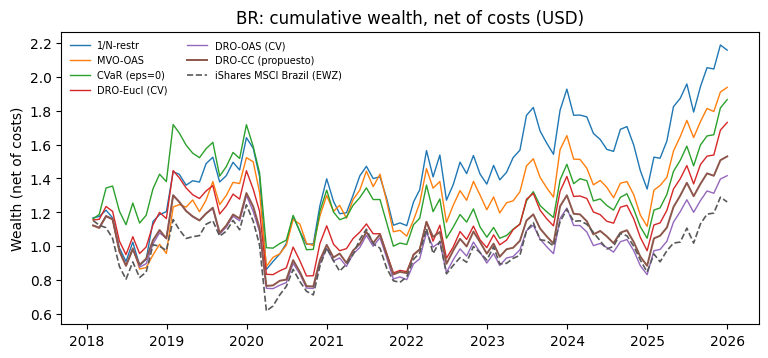

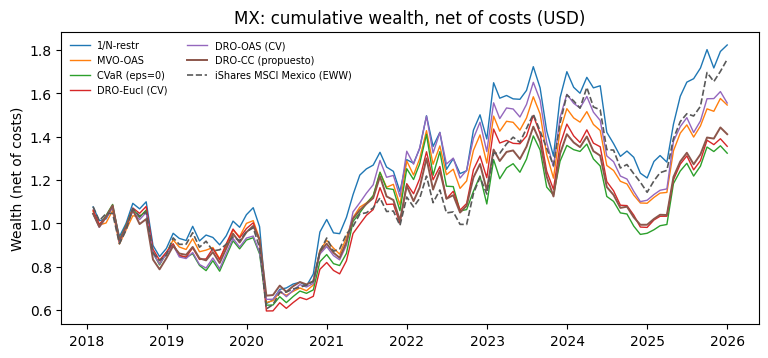

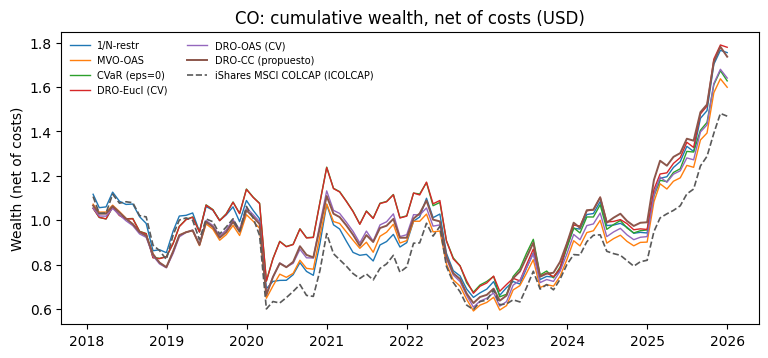

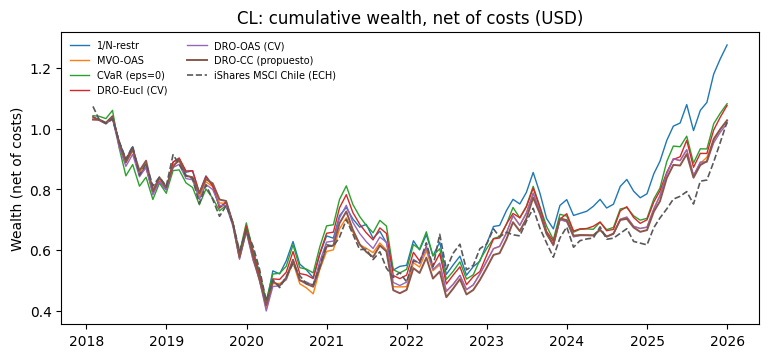

In [ ]:
def index_returns(c, start, end):
    # Retornos mensuales en USD del ETF de país (EWZ, EWW, ECH ya en USD; ICOLCAP en COP se convierte con COP=X)
    s_idx = load_reference_index(c, start, end)
    if s_idx is None: return None
    s_idx = to_month_end(s_idx)
    if MARKET_META[c].get('index_ccy', 'LOCAL') != 'USD':
        s_idx = s_idx / FX[MARKET_META[c]['fx']].reindex(s_idx.index)
    return s_idx.pct_change(fill_method=None).rename(INDEX_META[c][0])

def index_table(RES_, IDX_R_, start=None):
    rows = {}
    for c, r in RES_.items():
        ri = IDX_R_.get(c)
        if ri is None: continue
        dates = r['paths']['MVO-OAS'].loc[start:].index; ri = ri.reindex(dates)
        if ri.isna().any(): print(f'  [{c}] {INDEX_META[c][0]}: {int(ri.isna().sum())} meses sin dato en la evaluación.')
        if ri.notna().sum() < 12: continue
        m = perf_metrics(ri.dropna(), RF, PARAMS['ALPHA']); m['Tipo de retorno'] = INDEX_META[c][1]
        rows[(c, INDEX_META[c][0])] = m
    return pd.DataFrame(rows).T

IDX_R = {c: index_returns(c, START, END) for c in MARKET_META}
RES = {}
for c, md_ in MARKETS.items():
    print(f'=== {c} ==='); RES[c] = run_market(md_, PARAMS, verbose=False)
PERF = pd.concat({c: summarize(r, MARKETS[c]['rf']) for c, r in RES.items()})
display(PERF.round(3))
IDX_PERF = index_table(RES, IDX_R)
print('ETF de país en USD (referencia externa; no cumplen las restricciones climáticas):'); display(IDX_PERF)
for c in RES: fig_wealth(RES[c], f'{c}: cumulative wealth, net of costs (USD)', f'wealth_{c}.png',
                         index_r=IDX_R.get(c), index_label=INDEX_META[c][0])
print('Solver:', dict(SOLVER_STATS))

### F2. Pesos, conjunto factible, radio elegido y régimen de la penalización
Además de los pesos medios y del conjunto factible, se reportan: la distribución del radio elegido y la frecuencia en el extremo de la malla; la participación de la penalización de Wasserstein en el objetivo al radio elegido (§7); la pendiente de la curva de validación (diferencia relativa entre el mejor y el peor $\varepsilon$), que indica si la selección es informativa; la frecuencia con que cada restricción está activa; y el diagnóstico de la medida nominal (ESS, correlación de los pesos con la recencia, participación del bloque climático en la métrica).

,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (propuesto)
PETR4.SA,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000
VALE3.SA,0.0083,0.0000,0.0000,0.0001,0.0000,0.0000
ITUB4.SA,0.1219,0.1295,0.3079,0.2508,0.2255,0.1995
BBDC4.SA,0.1279,0.0130,0.0694,0.0922,0.0249,0.0296
CPFE3.SA,0.0894,0.1309,0.1543,0.1178,0.1351,0.1710
CMIG4.SA,0.1025,0.0000,0.0000,0.0231,0.0000,0.0000
CSNA3.SA,0.0010,0.0000,0.0000,0.0000,0.0000,0.0000
WEGE3.SA,0.0399,0.0007,0.0000,0.0106,0.0000,0.0000
SUZB3.SA,0.0317,0.0882,0.1336,0.1099,0.1139,0.1064
GGBR4.SA,0.0010,0.0000,0.0000,0.0000,0.0000,0.0000


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (propuesto)
FEMSAUBD.MX,0.0288,0.0027,0.0000,0.0096,0.0000,0.0000
GMEXICOB.MX,0.0000,0.0000,0.0034,0.0040,0.0050,0.0067
WALMEX.MX,0.1357,0.2880,0.3402,0.2892,0.3400,0.3331
GAPB.MX,0.1203,0.1082,0.0327,0.0591,0.0503,0.0735
AMXB.MX,0.1071,0.1961,0.2497,0.1719,0.2220,0.2382
RA.MX,0.1666,0.0801,0.0458,0.1124,0.0488,0.0467
GRUMAB.MX,0.0193,0.0228,0.0026,0.0071,0.0037,0.0140
KIMBERA.MX,0.0320,0.0020,0.0006,0.0124,0.0010,0.0019
CEMEXCPO.MX,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GFNORTEO.MX,0.1666,0.1102,0.1171,0.1068,0.1175,0.1108


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (propuesto)
ECOPETROL.CL,0.0015,0.0000,0.0000,0.0000,0.0000,0.0000
PFCIBEST.CL,0.1334,0.0022,0.0152,0.0632,0.0020,0.0012
PFGRUPOARG.CL,0.0120,0.0000,0.0000,0.0006,0.0000,0.0000
NUTRESA.CL,0.0431,0.0407,0.0250,0.0266,0.0445,0.0413
CELSIA.CL,0.1013,0.0509,0.0905,0.0932,0.0562,0.0987
GRUPOSURA.CL,0.0502,0.0312,0.0000,0.0006,0.0059,0.0077
TERPEL.CL,0.0666,0.1001,0.0673,0.0746,0.0919,0.0821
GEB.CL,0.1239,0.3116,0.3211,0.2566,0.3136,0.3064
CEMARGOS.CL,0.0039,0.0000,0.0089,0.0086,0.0004,0.0001
PFDAVVNDA.CL,0.1324,0.0160,0.0095,0.0629,0.0143,0.0136


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (propuesto)
SQM-B.SN,0.0032,0.0000,0.0159,0.0046,0.0000,0.0000
BSANTANDER.SN,0.1640,0.3082,0.3248,0.2207,0.3002,0.3212
COPEC.SN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
FALABELLA.SN,0.1476,0.0252,0.0015,0.0930,0.0239,0.0128
CENCOSUD.SN,0.1477,0.1409,0.1849,0.1697,0.1721,0.1461
CMPC.SN,0.0151,0.0215,0.0475,0.0419,0.0421,0.0505
COLBUN.SN,0.1623,0.2191,0.1806,0.1790,0.2042,0.2112
CCU.SN,0.0398,0.0800,0.0104,0.0288,0.0528,0.0454
LTM.SN,0.0000,0.0000,0.0033,0.0000,0.0000,0.0000
ENTEL.SN,0.1388,0.0239,0.0495,0.1020,0.0285,0.0402


BR | Neff máximo factible al inicio de la evaluación = 11.5
MX | Neff máximo factible al inicio de la evaluación = 10.21
CO | Neff máximo factible al inicio de la evaluación = 10.76
CL | Neff máximo factible al inicio de la evaluación = 9.07


,N_activos,n_biblioteca,lim_CI,lim_PHYS,Neff_max,n_w>=25%
BR,15.00,94.5,0.137,0.158,9.516,8.875
CL,13.00,94.5,0.111,0.289,7.458,7.156
CO,11.75,86.5,0.124,0.099,8.645,7.312
MX,14.00,94.5,0.129,0.320,7.885,8.188


... (12 outputs left out)

Rotación media por rebalanceo tras la reestimación anual de PHYS frente al resto:


tras reestimación (enero)  resto
BR DRO-CC (propuesto)                      0.520  0.326
   MVO-OAS                                 0.439  0.194
   1/N-restr                               0.235  0.168
MX DRO-CC (propuesto)                      0.441  0.351
   MVO-OAS                                 0.399  0.198
   1/N-restr                               0.199  0.156
CO DRO-CC (propuesto)                      0.460  0.246
   MVO-OAS                                 0.501  0.163
   1/N-restr                               0.250  0.113
CL DRO-CC (propuesto)                      0.342  0.275
   MVO-OAS                                 0.177  0.150
   1/N-restr                               0.101  0.084

Estado del solver por radio (todas las resoluciones, incluidas las de validación):


status,optimal
eps,
0.000,1264
0.010,1260
0.025,1260
0.050,1260
0.100,1261
0.200,1261
0.400,1260
0.800,1260
1.600,1261


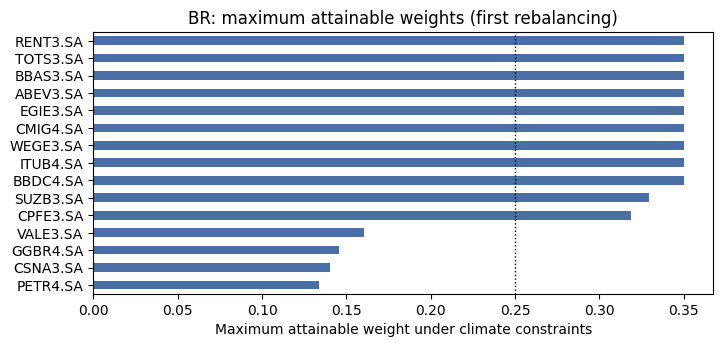

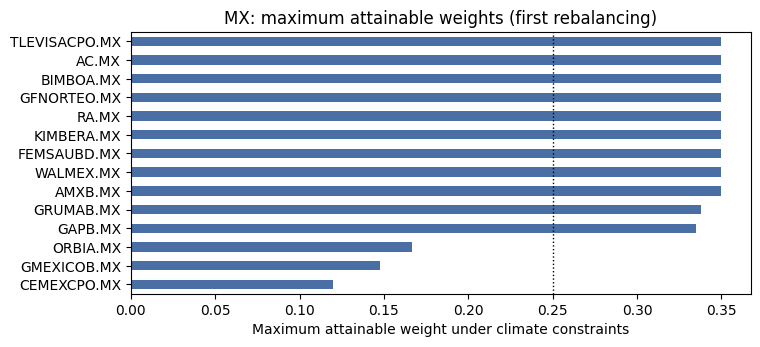

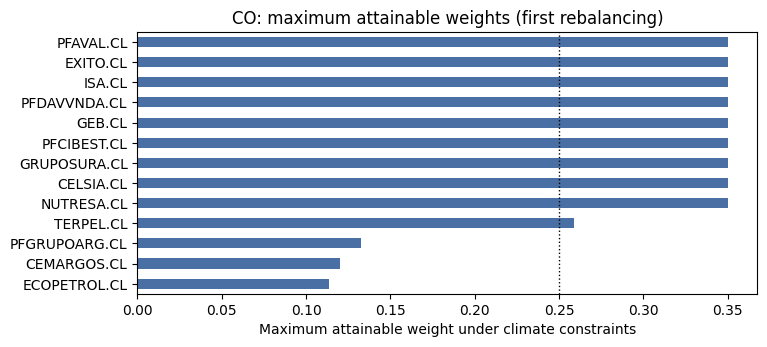

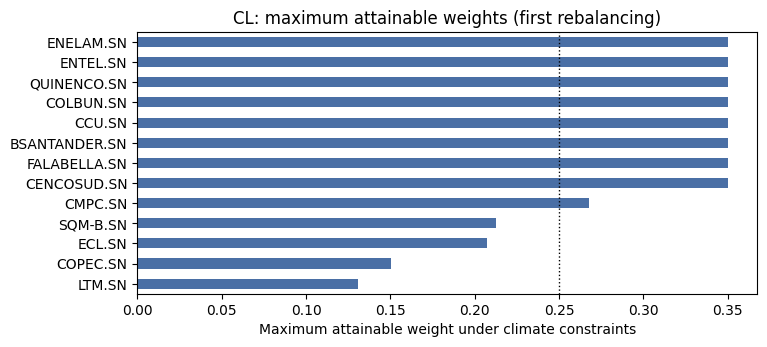

In [ ]:
AVGW = {c: average_weights(r) for c, r in RES.items()}
for c in AVGW: display(AVGW[c])
FEAS = {}
for c, md_ in MARKETS.items():
    chi = np.asarray(md_['chi']); n = chi.shape[1]
    lim = feasible_limits(chi, np.full(n, 1 / n), 0.0, PARAMS)
    FEAS[c], neff, _ = feasible_set_report(chi, lim, list(md_['R'].columns), PARAMS['W_MAX'])
    print(c, '| Neff máximo factible al inicio de la evaluación =', round(neff, 2))
    fig_feasible(FEAS[c], f'{c}: maximum attainable weights (first rebalancing)', f'feasible_{c}.png')
display(pd.concat({c: r['diag'] for c, r in RES.items()}).groupby(level=0).mean(numeric_only=True).round(3))

# Radio elegido, extremo de la malla, régimen de la penalización y pendiente de la curva de validación
EPS_SUM = {}
for c, r in RES.items():
    sl = r['solve_log']
    for s, ser in r['eps_choice'].items():
        kind = CV_KIND[s]
        pen = [sl[(sl.fecha == t) & (sl.tipo == kind) & (sl.eps == e)].eval('penalty / obj').iloc[0] for t, e in ser.items()]
        curves = [r['cv_curves'][(kind, t)] for t in ser.index if (kind, t) in r['cv_curves']]
        slope = [(cv.max() - cv.min()) / abs(cv.min()) for cv in curves]
        EPS_SUM[(c, s)] = {'eps mediano': ser.median(), 'eps medio': ser.mean(),
                           'en el extremo superior (%)': 100 * (ser >= max(PARAMS['EPS_GRID'])).mean(),
                           'en eps = 0 (%)': 100 * (ser == 0).mean(),
                           'peso de la penalización (media)': np.nanmean(pen),
                           'pendiente relativa de la curva CV (mediana)': np.median(slope) if slope else np.nan}
print('Radio elegido por validación cruzada y régimen de la penalización:'); display(pd.DataFrame(EPS_SUM).T.round(3))

# Restricciones activas
BITE = pd.concat({c: r['bite'].groupby('estrategia')[['activa_CI', 'activa_PHYS', 'activa_tope']].mean() * 100
                  for c, r in RES.items()})
print('Porcentaje de rebalanceos con cada restricción activa:'); display(BITE.round(1))
print('Relajaciones del conjunto factible:'); display(pd.concat({c: r['relaxations'] for c, r in RES.items()}))
print('Fechas con límite físico acotado a lo factible:')
display(pd.DataFrame({c: {'fechas': len(r['phys_bounded']),
                          'primera': r['phys_bounded']['fecha'].min() if len(r['phys_bounded']) else None,
                          'última': r['phys_bounded']['fecha'].max() if len(r['phys_bounded']) else None}
                      for c, r in RES.items()}).T)
print('Peso medio máximo por estrategia (<= W_MAX salvo relajaciones del tope):')
display(pd.concat({c: average_weights(r).max() for c, r in RES.items()}, axis=1).round(3))

# Medida nominal y métrica del modelo propuesto
print('Medida nominal y métrica de DRO-CC en las fechas de rebalanceo (resumen):')
display(pd.concat({c: r['kernel'].astype(float).describe().loc[['mean', 'min', '50%', 'max']] for c, r in RES.items()}).round(3))

# Rotación tras la reestimación anual de PHYS frente al resto
_rot = {}
for c, r in RES.items():
    for s_ in ['DRO-CC (propuesto)', 'MVO-OAS', '1/N-restr']:
        tv = r['paths'][s_]['turnover']; tv = tv[tv > 0].iloc[1:]
        _rot[(c, s_)] = {'tras reestimación (enero)': tv[tv.index.month == 1].mean(), 'resto': tv[tv.index.month != 1].mean()}
print('Rotación media por rebalanceo tras la reestimación anual de PHYS frente al resto:'); display(pd.DataFrame(_rot).T.round(3))
SOLVES = pd.concat({c: r['solve_log'] for c, r in RES.items()})
print('Estado del solver por radio (todas las resoluciones, incluidas las de validación):')
display(SOLVES.groupby(['eps', 'status']).size().unstack(fill_value=0))

### F3. Inferencia por mercado y de panel
Convención: $\Delta$ = DRO-CC menos el referente. El bloque del bootstrap se elige de forma automática para cada comparación (§9); la tabla de sensibilidad reporta los intervalos con bloques fijos.

In [ ]:
REFS = ['MVO-OAS', 'DRO-OAS (CV)', 'CVaR (eps=0)', '1/N-restr', 'ETF de país']

def inference_table(RES_, IDX_R_, start=None, A='DRO-CC (propuesto)', refs=REFS, P_=PARAMS):
    INF_ = {}
    for c, r in RES_.items():
        a = r['paths'][A]['net'].loc[start:]
        for b_name in refs:
            if b_name == 'ETF de país':
                if IDX_R_.get(c) is None: continue
                b = IDX_R_[c].reindex(a.index)
                if b.isna().any(): print(f'  [{c}] ETF con {int(b.isna().sum())} meses faltantes; se omite.'); continue
            else:
                b = r['paths'][b_name]['net'].reindex(a.index)
            bt = bootstrap_differences(a.values, b.values, RF.reindex(a.index).values,
                                       B=P_['BOOT_B'], block=P_['BOOT_BLOCK'], alpha=P_['ALPHA'])
            dm = dm_hln(downside_loss(a.values), downside_loss(b.values))
            row = {f'{i} | {j}': bt.loc[i, j] for i in bt.index
                   for j in ['estimación', 'IC95_inf', 'IC95_sup', 'p_A_mejor', 'p_bilateral']}
            row['bloque'] = int(bt['bloque'].iloc[0])
            row.update({f'DM | {k}': v for k, v in dm.items()})
            INF_[(c, b_name)] = row
    INF_ = pd.DataFrame.from_dict(INF_, orient='index')
    for k in ['Delta CVaR', 'Delta Sharpe', 'DM']:          # Holm por familia (mercados x referentes)
        INF_[f'{k} | p_bilateral_Holm'] = holm_adjust(INF_[f'{k} | p_bilateral'].values)
    return INF_

INF = inference_table(RES, IDX_R)
print('Convención: Delta = DRO-CC menos referente. p_A_mejor = p unilateral a favor de DRO-CC. Holm sobre', len(INF),
      'comparaciones. IC de Delta MaxDD sólo descriptivo.')
display(INF.round(4))
POOL = pd.concat([pooled_bootstrap(RES, 'DRO-CC (propuesto)', b) for b in ['MVO-OAS', 'DRO-OAS (CV)', '1/N-restr']], axis=1).T
print('Panel de los cuatro mercados:'); display(POOL.round(4))
BLOCKS = pd.concat({(c, b): block_sensitivity(r['paths']['DRO-CC (propuesto)']['net'].values,
                                              r['paths'][b]['net'].values, RF.reindex(r['paths'][b].index).values,
                                              PARAMS['BOOT_BLOCK_SENS'], PARAMS['BOOT_B'], PARAMS['ALPHA'])
                    for c, r in RES.items() for b in ['DRO-OAS (CV)', 'MVO-OAS']})
print('Sensibilidad de los intervalos al bloque del bootstrap:'); display(BLOCKS.round(4))

Convención: Delta = DRO-CC menos referente. p_A_mejor = p unilateral a favor de DRO-CC. Holm sobre 20 comparaciones. IC de Delta MaxDD sólo descriptivo.


Delta CVaR | estimación  Delta CVaR | IC95_inf  Delta CVaR | IC95_sup  Delta CVaR | p_A_mejor  Delta CVaR | p_bilateral  Delta Sharpe | estimación  Delta Sharpe | IC95_inf  \
BR MVO-OAS                       -0.0093                -0.0249                 0.0083                  0.1190                     0.238                    -0.0973                  -0.2720   
   DRO-OAS (CV)                  -0.0029                -0.0149                 0.0069                  0.1755                     0.351                     0.0310                  -0.0101   
   CVaR (eps=0)                   0.0078                -0.0157                 0.0344                  0.6395                     0.721                    -0.0810                  -0.2856   
   1/N-restr                     -0.0164                -0.0534                 0.0129                  0.2525                     0.505                    -0.1414                  -0.3288   
   ETF de país                   -0.0194                -0.0550                 0.0139                  0.1640                     0.328                     0.0652                  -0.1887   
MX MVO-OAS                       -0.0088                -0.0250                 0.0046                  0.1855                     0.371                    -0.0447                  -0.1729   
   DRO-OAS (CV)                   0.0036                -0.0048                 0.0182                  0.7000                     0.600                    -0.0436                  -0.1404   
   CVaR (eps=0)                  -0.0068                -0.0191                 0.0061                  0.1720                     0.344                     0.0276                  -0.1028   
   1/N-restr                     -0.0171                -0.0541                 0.0122                  0.2235                     0.447                    -0.1216                  -0.3337   
   ETF de país                   -0.0028                -0.0280                 0.0268                  0.5065                     0.987                    -0.1090                  -0.3389   
CO MVO-OAS                        0.0041                -0.0107                 0.0173                  0.8400                     0.320                     0.0404                  -0.0364   
   DRO-OAS (CV)                   0.0023                -0.0153                 0.0206                  0.6975                     0.605                     0.0282                  -0.0259   
   CVaR (eps=0)                  -0.0101                -0.0312                 0.0116                  0.1095                     0.219                     0.0309                  -0.0881   
   1/N-restr                     -0.0005                -0.0254                 0.0262                  0.5235                     0.953                    -0.0022                  -0.1984   
   ETF de país                   -0.0039                -0.0435                 0.0365                  0.3755                     0.751                     0.0772                  -0.2069   
CL MVO-OAS                       -0.0091                -0.0231                 0.0101                  0.2765                     0.553                    -0.0020                  -0.0560   
   DRO-OAS (CV)                  -0.0092                -0.0204                 0.0056                  0.1485                     0.297                     0.0006                  -0.0723   
   CVaR (eps=0)                   0.0017                -0.0088                 0.0111                  0.5855                     0.829                    -0.0259                  -0.1412   
   1/N-restr                      0.0101                -0.0181                 0.0416                  0.7045                     0.591                    -0.0980                  -0.2545   
   ETF de país                    0.0135                -0.0187                 0.0575                  0.7455                     0.509                     0.0065              

Panel de los cuatro mercados:


,Delta CVaR panel,IC95_inf,IC95_sup,p_A_mejor (Delta<0),p_bilateral,bloque,T meses,N obs. apiladas
DRO-CC (propuesto) vs MVO-OAS,-0.0054,-0.0186,0.0042,0.2170,0.434,3.0,96.0,384.0
DRO-CC (propuesto) vs DRO-OAS (CV),-0.0004,-0.0054,0.0043,0.3375,0.675,7.0,96.0,384.0
DRO-CC (propuesto) vs 1/N-restr,-0.0039,-0.0223,0.0076,0.2650,0.530,23.0,96.0,384.0


Sensibilidad de los intervalos al bloque del bootstrap:


Delta CVaR | IC95_inf  Delta CVaR | IC95_sup  Delta CVaR | p_bilateral  Delta Sharpe | IC95_inf  Delta Sharpe | IC95_sup  Delta Sharpe | p_bilateral
BR DRO-OAS (CV) bloque 3 (auto)                 -0.0149                 0.0069                     0.351                  -0.0101                   0.0763                       0.129
                bloque 3                        -0.0149                 0.0069                     0.351                  -0.0101                   0.0763                       0.129
                bloque 6                        -0.0135                 0.0067                     0.327                  -0.0042                   0.0672                       0.095
                bloque 12                       -0.0126                 0.0068                     0.275                   0.0027                   0.0604                       0.032
   MVO-OAS      bloque 7 (auto)                 -0.0249                 0.0083                     0.238                  -0.2720                   0.0583                       0.235
                bloque 3                        -0.0286                 0.0095                     0.231                  -0.2775                   0.0542                       0.227
                bloque 6                        -0.0261                 0.0078                     0.217                  -0.2795                   0.0495                       0.237
                bloque 12                       -0.0267                 0.0061                     0.202                  -0.2689                   0.0516                       0.279
MX DRO-OAS (CV) bloque 2 (auto)                 -0.0048                 0.0182                     0.600                  -0.1404                   0.0732                       0.449
                bloque 3                        -0.0047                 0.0182                     0.573                  -0.1471                   0.0662                       0.468
                bloque 6                        -0.0052                 0.0171                     0.579                  -0.1561                   0.0760                       0.574
                bloque 12                       -0.0048                 0.0171                     0.581                  -0.1689                   0.0740                       0.594
   MVO-OAS      bloque 2 (auto)                 -0.0250                 0.0046                     0.371                  -0.1729                   0.0640                       0.433
                bloque 3                        -0.0248                 0.0045                     0.401                  -0.1718                   0.0577                       0.428
                bloque 6                        -0.0249                 0.0041                     0.312                  -0.1555                   0.0525                       0.388
                bloque 12                       -0.0228                 0.0037                     0.307                  -0.1381                   0.0423                       0.338
CO DRO-OAS (CV) bloque 3 (auto)                 -0.0153                 0.0206                     0.605                  -0.0259                   0.0988                       0.335
                bloque 3                        -0.0153                 0.0206                     0.605                  -0.0259                   0.0988                       0.335
                bloque 6                        -0.0136                 0.0212                     0.570                  -0.0256                   0.0909                       0.306
                bloque 12                       -0.0131                 0.0169                     0.520                  -0.0215                   0.0852                       0.290
   MVO-OAS      bloque 2 (auto)                 -0.0107                 0.0173                     0.320                  -0.0364                   0.1254                       0.284
        

### F4. Ablaciones, frontera CVaR–$\varepsilon$ y especificaciones alternativas de la exposición física
Es la sección más costosa (varias horas en Colab). Con `RUN_F4 = False` puede omitirse y ejecutarse después sin repetir lo anterior. Las ablaciones y las especificaciones alternativas de PHYS usan una malla gruesa del radio, por lo que sus filas base no coinciden exactamente con F1. La fila «Sin clima ($\omega=0$, $\kappa=0$)» de DRO-CC reproduce DRO-OAS con esa malla y sirve de control del anidamiento.

  Nota: límite físico acotado a lo factible en 26 fechas (rebalanceo o validación) | primera 2020-12-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 71 fechas (rebalanceo o validación) | primera 2018-05-31, última 2025-09-30
  Nota: límite físico acotado a lo factible en 58 fechas (rebalanceo o validación) | primera 2018-05-31, última 2025-09-30
  Nota: límite físico acotado a lo factible en 106 fechas (rebalanceo o validación) | primera 2016-12-31, última 2025-09-30
  Nota: límite físico acotado a lo factible en 20 fechas (rebalanceo o validación) | primera 2020-12-31, última 2022-11-30
  Nota: límite físico acotado a lo factible en 59 fechas (rebalanceo o validación) | primera 2019-12-31, última 2025-09-30
  Nota: límite físico acotado a lo factible en 3 fechas (rebalanceo o validación) | primera 2024-01-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 3 fechas (rebalanceo o validación) | primera 2024-01-31, última 2025-08-31
  Nota: límite fí

Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  \
Especificación                                 Estrategia                                                                                                                              
Base                                           MVO-OAS                            8.621          31.507           0.343              18.738               14.596    -42.181       96   
                                               DRO-CC (propuesto)                 5.279          30.584           0.240              17.803               13.834    -42.390       96   
                                               1/N-restr                         10.089          32.826           0.387              19.446               14.629    -47.399       96   
CTB (reducción 30 %)                           MVO-OAS                            9.355          29.920           0.367              17.294               13.860    -40.192       96   
                                               DRO-CC (propuesto)                 6.912          29.502           0.289              16.949               13.521    -39.156       96   
                                               1/N-restr                         10.493          31.979           0.401              19.224               14.586    -47.496       96   
Reducción 70 %, 5 % anual, sin tope            MVO-OAS                            8.606          33.631           0.341              19.768               15.028    -42.506       96   
                                               DRO-CC (propuesto)                 4.932          33.549           0.236              19.315               15.445    -41.805       96   
                                               1/N-restr                          9.772          35.416           0.376              20.943               15.616    -49.887       96   
PHYS -15 % frente al benchmark                 MVO-OAS                            5.336          32.915           0.249              20.328               15.612    -45.986       96   
                                               DRO-CC (propuesto)                 3.724          32.436           0.199              19.445               15.224    -44.082       96   
                                               1/N-restr                          6.425          34.665           0.285              20.505               15.855    -49.501       96   
PHYS -30 % frente al benchmark                 MVO-OAS                            1.811          34.754           0.157              21.200               16.807    -53.794       96   
                                               DRO-CC (propuesto)                 1.539          34.841           0.149              21.076               16.725    -55.544       96   
                                               1/N-restr                          3.262          36.043           0.202              20.912               16.553    -52.947       96   
Sin tope por activo                            MVO-OAS                            8.559          31.672           0.340              18.545               14.677    -41.371       96   
                                               DRO-CC (propuesto)                 6.431          31.630           0.276              19.004               14.581    -41.548       96   
                                               1/N-restr                         10.089          32.826           0.387              19.446               14.629    -47.399       96   
Sin kernel climático (omega = 0)               MVO-OAS                            8.621          31.507           0.343              18.738               14.596    -42.181       96   
                                               DRO-CC (propuesto)                 5.347          30.538           0.242              17.861               13.848    -42.420       96   
                   

MX


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  \
Especificación                                 Estrategia                                                                                                                              
Base                                           MVO-OAS                            5.603          27.375           0.248              17.650               13.471    -40.043       96   
                                               DRO-CC (propuesto)                 4.227          26.681           0.197              16.871               13.149    -40.267       96   
                                               1/N-restr                          7.801          28.398           0.325              18.481               13.776    -42.702       96   
CTB (reducción 30 %)                           MVO-OAS                            4.104          24.822           0.188              16.766               12.427    -38.685       96   
                                               DRO-CC (propuesto)                 2.661          25.075           0.133              16.797               12.785    -40.748       96   
                                               1/N-restr                          7.860          26.511           0.329              17.590               12.959    -41.091       96   
Reducción 70 %, 5 % anual, sin tope            MVO-OAS                            6.836          29.688           0.294              19.058               14.069    -43.943       96   
                                               DRO-CC (propuesto)                 6.008          27.440           0.264              17.976               13.378    -44.114       96   
                                               1/N-restr                          8.244          31.437           0.339              20.300               14.893    -47.703       96   
PHYS -15 % frente al benchmark                 MVO-OAS                            4.935          27.790           0.225              18.185               13.684    -36.124       96   
                                               DRO-CC (propuesto)                 4.495          27.489           0.210              18.346               13.810    -38.609       96   
                                               1/N-restr                          6.869          28.845           0.293              18.620               13.911    -39.902       96   
PHYS -30 % frente al benchmark                 MVO-OAS                            5.186          27.690           0.233              18.016               13.599    -36.124       96   
                                               DRO-CC (propuesto)                 5.222          27.248           0.234              17.993               13.634    -36.723       96   
                                               1/N-restr                          6.801          28.886           0.291              18.717               13.959    -40.512       96   
Sin tope por activo                            MVO-OAS                            3.990          26.890           0.191              17.470               13.275    -40.043       96   
                                               DRO-CC (propuesto)                 4.794          26.272           0.216              16.614               12.946    -39.822       96   
                                               1/N-restr                          7.801          28.398           0.325              18.481               13.776    -42.702       96   
Sin kernel climático (omega = 0)               MVO-OAS                            5.603          27.375           0.248              17.650               13.471    -40.043       96   
                                               DRO-CC (propuesto)                 5.752          26.979           0.249              16.435               12.881    -39.613       96   
                   

CO


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  \
Especificación                                 Estrategia                                                                                                                              
Base                                           MVO-OAS                            6.042          26.100           0.265              16.534               12.540    -44.854       96   
                                               DRO-CC (propuesto)                 7.263          26.247           0.309              16.941               12.659    -43.477       96   
                                               1/N-restr                          7.284          26.612           0.308              16.998               12.739    -42.048       96   
CTB (reducción 30 %)                           MVO-OAS                            6.597          25.459           0.287              16.547               12.357    -46.125       96   
                                               DRO-CC (propuesto)                 6.849          25.433           0.297              16.969               12.384    -46.417       96   
                                               1/N-restr                          7.233          26.681           0.306              17.066               12.783    -44.181       96   
Reducción 70 %, 5 % anual, sin tope            MVO-OAS                            6.246          27.876           0.273              18.063               13.521    -46.473       96   
                                               DRO-CC (propuesto)                 4.359          28.296           0.209              18.530               13.845    -51.189       96   
                                               1/N-restr                          7.124          27.618           0.300              17.260               13.073    -40.983       96   
PHYS -15 % frente al benchmark                 MVO-OAS                            4.956          26.803           0.228              17.199               12.781    -45.124       96   
                                               DRO-CC (propuesto)                 5.841          27.021           0.260              17.635               12.854    -43.620       96   
                                               1/N-restr                          6.823          27.664           0.292              17.786               13.202    -43.076       96   
PHYS -30 % frente al benchmark                 MVO-OAS                            5.687          28.262           0.255              17.894               13.279    -45.026       96   
                                               DRO-CC (propuesto)                 5.349          28.097           0.244              18.147               13.298    -46.425       96   
                                               1/N-restr                          7.255          28.829           0.307              18.713               13.727    -43.816       96   
Sin tope por activo                            MVO-OAS                            4.376          26.864           0.208              18.211               13.450    -48.313       96   
                                               DRO-CC (propuesto)                 3.790          27.133           0.187              18.420               13.637    -50.332       96   
                                               1/N-restr                          7.284          26.612           0.308              16.998               12.739    -42.048       96   
Sin kernel climático (omega = 0)               MVO-OAS                            6.042          26.100           0.265              16.534               12.540    -44.854       96   
                                               DRO-CC (propuesto)                 7.098          26.142           0.304              16.885               12.647    -44.180       96   
                   

... (4 outputs left out)

,Ret. geom. anual (%),Vol. anual (%),Sharpe (anual),CVaR5% mensual (%),CVaR10% mensual (%),MaxDD (%),N meses,Neff medio,peso de la penalización
eps,,,,,,,,,
0.000,8.189,26.608,0.341,17.923,13.429,-43.937,96,3.630,0.000
0.010,8.189,26.608,0.341,17.923,13.429,-43.937,96,3.630,0.025
0.025,7.993,26.523,0.335,17.923,13.403,-43.934,96,3.662,0.061
0.050,8.042,26.525,0.337,17.923,13.391,-43.984,96,3.670,0.114
0.100,8.074,26.398,0.338,17.984,13.391,-43.181,96,3.700,0.204
0.200,7.335,26.363,0.312,17.817,13.253,-43.700,96,3.763,0.336
0.400,6.997,26.483,0.300,17.766,13.293,-44.318,96,3.830,0.499
0.800,6.749,26.575,0.291,17.732,13.202,-44.100,96,3.886,0.660
1.600,7.073,26.566,0.302,17.557,13.061,-43.202,96,3.914,0.792


,Ret. geom. anual (%),Vol. anual (%),Sharpe (anual),CVaR5% mensual (%),CVaR10% mensual (%),MaxDD (%),N meses,Neff medio,peso de la penalización
eps,,,,,,,,,
0.000,0.306,27.660,0.060,16.810,14.093,-59.976,96,3.952,0.000
0.010,0.210,27.684,0.056,16.810,14.093,-59.975,96,3.949,0.024
0.025,0.245,27.592,0.057,16.568,13.984,-59.615,96,3.960,0.059
0.050,0.296,27.554,0.058,16.448,13.920,-59.214,96,3.970,0.111
0.100,0.374,27.592,0.061,16.407,13.912,-58.439,96,3.969,0.199
0.200,0.386,27.632,0.062,16.348,13.862,-58.374,96,4.000,0.330
0.400,-0.500,28.028,0.034,17.409,14.287,-59.529,96,4.171,0.492
0.800,-0.767,28.200,0.027,17.715,14.295,-59.199,96,4.285,0.656
1.600,-0.787,28.190,0.026,17.959,14.401,-60.064,96,4.340,0.788


  Nota: límite físico acotado a lo factible en 17 fechas (rebalanceo o validación) | primera 2021-12-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 29 fechas (rebalanceo o validación) | primera 2018-05-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 29 fechas (rebalanceo o validación) | primera 2018-05-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 6 fechas (rebalanceo o validación) | primera 2022-12-31, última 2025-08-31
  Nota: límite físico acotado a lo factible en 2 fechas (rebalanceo o validación) | primera 2025-07-31, última 2025-08-31


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  \
                                      Estrategia                                                                                                                              
ENSO con 6 rezagos                 BR MVO-OAS                            9.376          31.633           0.366              18.665               14.556    -44.081       96   
                                      DRO-OAS (CV)                       6.487          30.600           0.278              18.227               13.976    -42.402       96   
                                      DRO-CC (propuesto)                 7.295          30.712           0.303              17.927               13.793    -42.398       96   
                                      1/N-restr                         10.722          32.737           0.405              19.126               14.411    -46.998       96   
                                   MX MVO-OAS                            5.370          27.247           0.240              17.686               13.645    -40.272       96   
...                                                                        ...             ...             ...                 ...                  ...        ...      ...   
Prior experto completo (CI y PHYS) CO 1/N-restr                          6.697          26.687           0.287              16.998               12.934    -44.396       96   
                                   CL MVO-OAS                            0.975          27.915           0.086              17.681               14.234    -59.723       96   
                                      DRO-OAS (CV)                       0.414          27.812           0.065              17.670               14.332    -58.594       96   
                                      DRO-CC (propuesto)                 0.274          27.702           0.059              17.423               14.269    -59.276       96   
                                      1/N-restr                          3.188          27.851           0.162              15.765               13.422    -59.257       96   

                                                          Rotación media por rebalanceo  Neff medio  
                                      Estrategia                                                     
ENSO con 6 rezagos                 BR MVO-OAS                                     0.190       4.240  
                                      DRO-OAS (CV)                                0.230       3.815  
                                      DRO-CC (propuesto)                          0.268       3.725  
                                      1/N-restr                                   0.106       9.948  
                                   MX MVO-OAS                                     0.161       4.992  
...                                                                                 ...         ...  
Prior experto completo (CI y PHYS) CO 1/N-restr                                   0.096       8.830  
                                   CL MVO-OAS                                     0.140       4.387  
                                      DRO-OAS (CV)                                0.192       4.290  
                                      DRO-CC (propuesto)                          0.231       4.114  
                                      1/N-restr                                   0.084       7.464  

[80 rows x 9 columns]

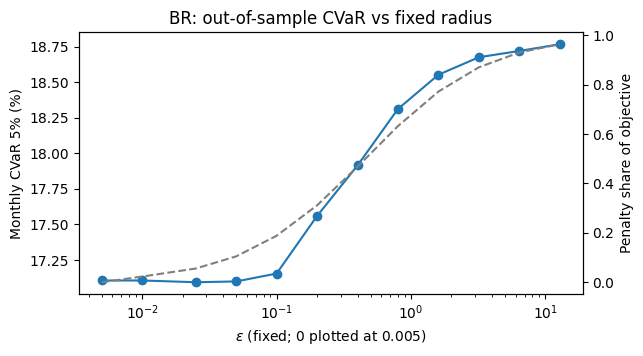

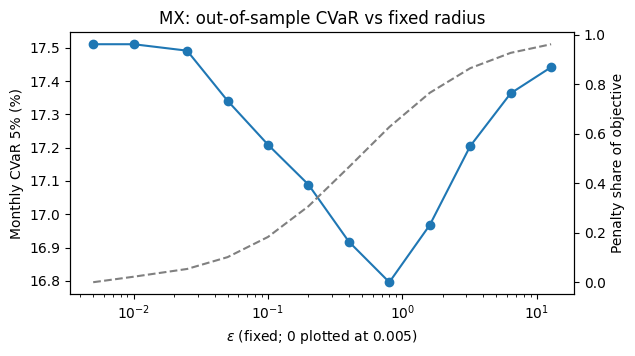

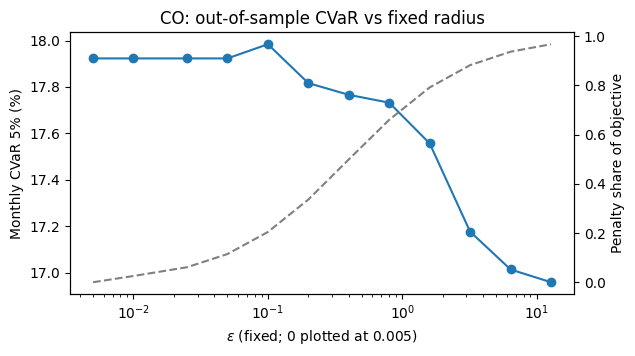

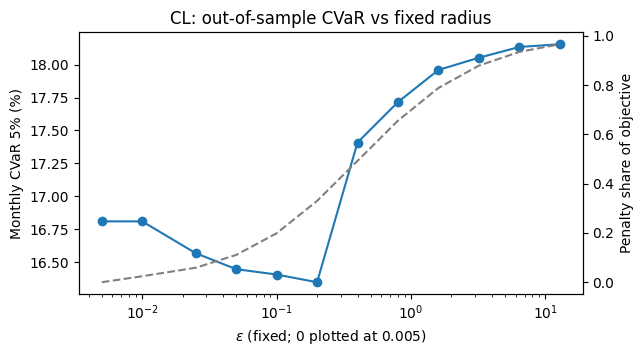

In [ ]:
RUN_F4 = True
if RUN_F4:
  ABL = {c: run_ablations(MARKETS[c]) for c in MARKETS}
  for c in ABL: print(c); display(ABL[c].round(3))
  FRONT = {c: eps_frontier(MARKETS[c]) for c in MARKETS}
  for c in FRONT:
      display(FRONT[c].round(3)); fig_eps_frontier(FRONT[c], f'{c}: out-of-sample CVaR vs fixed radius', f'eps_frontier_{c}.png')
  # Especificaciones alternativas de la exposición física (cada una con su propia trayectoria expansiva)
  ALT_SPECS = {'ENSO con 6 rezagos': {'enso_lags': 6}, 'ENSO sin control de mercado': {'market_control': False},
               'Sólo riesgo hídrico (kappa = 0)': {'kappa': 0.0}, 'Regla de sede para emisores H': {'hq_rule': 'hq'}}
  _S4 = ['MVO-OAS', 'DRO-OAS (CV)', 'DRO-CC (propuesto)', '1/N-restr']; ALT = {}
  P_ALT = dict(PARAMS, EPS_GRID=ABLATION_EPS_GRID)          # malla gruesa, como en las ablaciones
  for lab, sp in ALT_SPECS.items():
      path_, _ = build_phys_path(R_USD, MEI, AQ, EST_DATES, PARAMS['PRICE_START'], spec=dict(PHYS_SPEC_MAIN, **sp),
                                 min_obs=PARAMS['ENSO_MIN_OBS'])
      mk_ = build_markets('PHYS_data', phys_path=path_, verbose=False)
      ALT[lab] = pd.concat({c: summarize(run_market(m_, P_ALT, strategies=_S4, verbose=False), m_['rf'])
                            for c, m_ in mk_.items()})
  ALT['Prior experto completo (CI y PHYS)'] = pd.concat({c: summarize(run_market(m_, P_ALT, strategies=_S4, verbose=False),
                                                                      m_['rf']) for c, m_ in MARKETS_PRIOR.items()})
  ALT = pd.concat(ALT); display(ALT.round(3))

### F5. Modelo de estado: componentes, condicionamiento y convergencia de Riccati

Estimaciones anuales del modelo de estado en el backtest (componentes, condicionamiento y estabilidad):


componentes excluidas     cond(Q)  rho(Phi)  iteraciones EM
   estimación                                                                         
BR 2015-12-31       T_anom, ENSO, Comm       P_C       8.286     0.970             200
   2016-12-31       T_anom, ENSO, Comm       P_C      93.336     0.939             200
   2017-12-31       T_anom, ENSO, Comm       P_C      87.071     0.926             200
   2018-12-31       T_anom, ENSO, Comm       P_C      59.860     0.932             200
   2019-12-31       T_anom, ENSO, Comm       P_C      50.247     0.940             200
   2020-12-31       T_anom, ENSO, Comm       P_C      40.863     0.916             200
   2021-12-31       T_anom, ENSO, Comm       P_C      30.838     0.918             200
   2022-12-31       T_anom, ENSO, Comm       P_C       7.890     0.943             200
   2023-12-31       T_anom, ENSO, Comm       P_C       7.374     0.948             200
   2024-12-31       T_anom, ENSO, Comm       P_C       3.420     0.944             200
MX 2015-12-31       T_anom, ENSO, Comm       P_C       2.766     0.970             200
   2016-12-31  P_C, T_anom, ENSO, Comm         -  787499.999     0.970             200
   2017-12-31  P_C, T_anom, ENSO, Comm         -   38889.002     0.970             200
   2018-12-31  P_C, T_anom, ENSO, Comm         -    1237.179     0.952             200
   2019-12-31  P_C, T_anom, ENSO, Comm         -    1474.779     0.956             200
   2020-12-31  P_C, T_anom, ENSO, Comm         -     683.791     0.969             200
   2021-12-31  P_C, T_anom, ENSO, Comm         -    1053.937     0.962             200
   2022-12-31  P_C, T_anom, ENSO, Comm         -    1046.140     0.966             151
   2023-12-31  P_C, T_anom, ENSO, Comm         -    1861.016     0.970             200
   2024-12-31  P_C, T_anom, ENSO, Comm         -    1199.958     0.966             149
CO 2015-12-31       T_anom, ENSO, Comm       P_C      10.231     0.970             200
   2016-12-31       T_anom, ENSO, Comm       P_C     246.617     0.965             200
   2017-12-31  P_C, T_anom, ENSO, Comm         -      15.468     0.970             125
   2018-12-31  P_C, T_anom, ENSO, Comm         -       6.685     0.970             200
   2019-12-31  P_C, T_anom, ENSO, Comm         -       7.626     0.970             200
   2020-12-31  P_C, T_anom, ENSO, Comm         -       8.227     0.968             200
   2021-12-31  P_C, T_anom, ENSO, Comm         -       8.426     0.964             200
   2022-12-31  P_C, T_anom, ENSO, Comm         -       8.363     0.969             200
   2023-12-31  P_C, T_anom, ENSO, Comm         -       7.409     0.970             200
   2024-12-31  P_C, T_anom, ENSO, Comm         -       7.208     0.970             200
CL 2015-12-31       T_anom, ENSO, Comm       P_C       6.964     0.970             200
   2016-12-31       T_anom, ENSO, Comm       P_C       7.081     0.970             200
   2017-12-31  P_C, T_anom, ENSO, Comm         -       9.882     0.970             200
   2018-12-31  P_C, T_anom, ENSO, Comm         -      28.752     0.970             200
   2019-12-31  P_C, T_anom, ENSO, Comm         -       4.642     0.970             200
   2020-12-31  P_C, T_anom, ENSO, Comm         -       6.453     0.969             127
   2021-12-31  P_C, T_anom, ENSO, Comm         -       3.779     0.970             185
   2022-12-31  P_C, T_anom, ENSO, Comm         -       4.946     0.970             200
   2023-12-31  P_C, T_anom, ENSO, Comm         -       4.668     0.970             200
   2024-12-31  P_C, T_anom, ENSO, Comm         -       4.013     0.970             200

,rho(Phi),tr(P) inicial,tr(P) estacionaria,meses a 1%
BR,0.9276,0.0194,0.0396,6.0
MX,0.9700,0.0203,0.0202,1.0
CO,0.9700,0.0327,0.0373,6.0
CL,0.9700,0.0844,0.1244,6.0


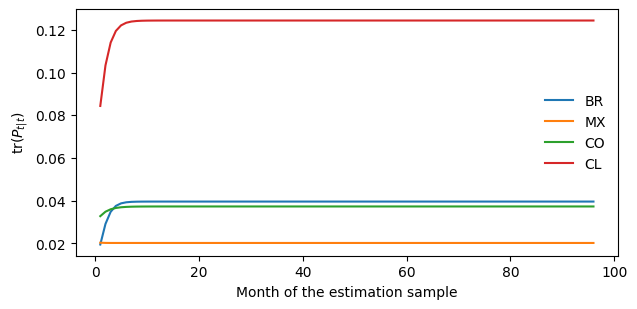

In [ ]:
print('Estimaciones anuales del modelo de estado en el backtest (componentes, condicionamiento y estabilidad):')
display(pd.concat({c: r['state_log'].set_index('estimación') for c, r in RES.items()}).round(3))
fig, ax = plt.subplots(figsize=(7, 3.2)); RICCATI = {}
for c, md_ in MARKETS.items():
    Zt_ = transform_state(md_['Z_raw'].loc[PARAMS['CLIMATE_START']:]); Zt_ = Zt_.loc[Zt_.dropna(how='all').index]
    m_ = fit_climate_state(Zt_, month_shift(PARAMS['IS_END'], PARAMS['PUB_LAG']), PARAMS['STATE_TOL'])
    tr = riccati_report(m_, len(Zt_.loc[:PARAMS['IS_END']]))
    conv = int(np.argmax(np.abs(tr - tr[-1]) / tr[-1] < 0.01)) + 1
    RICCATI[c] = {'rho(Phi)': m_['rho'], 'tr(P) inicial': tr[0], 'tr(P) estacionaria': tr[-1], 'meses a 1%': conv}
    ax.plot(np.arange(1, len(tr) + 1), tr, label=c)
ax.set_xlabel('Month of the estimation sample'); ax.set_ylabel(r'tr$(P_{t|t})$'); ax.legend(frameon=False)
fig.savefig('riccati_trace.png', dpi=200, bbox_inches='tight')
display(pd.DataFrame(RICCATI).T.round(4))

### F6. Robustez: estimación 2014–2021, evaluación 2022–2025, PHYS fijo
Diseño alternativo: PHYS se estima una sola vez con los retornos de 2014–2021 y se evalúa en 2022–2025 (48 meses). Se reporta junto con el diseño principal restringido a los mismos 48 meses, lo que separa el efecto de la ventana de evaluación del efecto de la forma de estimar PHYS. Con la mitad de meses, los intervalos son del orden de $\sqrt2\approx1{,}41$ veces más anchos.

  PHYS: regla H = country; índice hídrico = ['wsi', 'iav', 'drr']; ENSO = noticia con 3 rezagos y control de mercado; kappa = 0.5 (1 de 55 emisores con respuesta ENSO significativa al 5 %; ventana 2014-01-01 a 2021-12-31).
Spearman PHYS (2014-2021) vs PHYS (2014-2017): 0.825
=== BR (robustez) ===
=== MX (robustez) ===
=== CO (robustez) ===
=== CL (robustez) ===
Diseño de robustez (estimación 2014-2021, evaluación 2022-2025):


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  Rotación media por rebalanceo  Neff medio
   Estrategia                                                                                                                                                                      
BR 1/N-restr                         16.867          25.872           0.578              11.971               10.542    -28.101       48                          0.169      10.150
   MVO-OAS                           14.022          25.654           0.483              11.465               10.082    -32.595       48                          0.173       4.143
   CVaR (eps=0)                      10.589          26.261           0.362              12.810               11.287    -32.670       48                          0.280       3.958
   DRO-Eucl (CV)                     16.261          25.156           0.568              11.996               10.436    -27.566       48                          0.249       9.404
   DRO-OAS (CV)                      13.396          25.589           0.462              11.516               10.063    -32.405       48                          0.181       4.126
   DRO-CC (propuesto)                11.281          25.470           0.389              11.553               10.203    -34.116       48                          0.389       4.049
MX 1/N-restr                          9.507          23.919           0.330              11.715               10.197    -29.545       48                          0.133       8.893
   MVO-OAS                            3.422          23.069           0.085              10.564                9.615    -34.689       48                          0.155       4.475
   CVaR (eps=0)                      -1.716          24.631          -0.111              12.154               10.936    -43.268       48                          0.129       3.941
   DRO-Eucl (CV)                      5.117          24.045           0.159              11.621               10.557    -30.246       48                          0.328       7.762
   DRO-OAS (CV)                       2.843          23.100           0.061              10.550                9.623    -35.027       48                          0.160       4.408
   DRO-CC (propuesto)                 2.870          23.106           0.063              10.417                9.565    -36.172       48                          0.212       4.337
CO 1/N-restr                         17.437          24.797           0.617              13.740               12.020    -42.363       48                          0.143       7.769
   MVO-OAS                           17.693          24.692           0.628              12.975               11.588    -45.323       48                          0.147       4.355
   CVaR (eps=0)                      19.268          26.248           0.657              13.776               12.397    -46.300       48                          0.170       3.668
   DRO-Eucl (CV)                     13.985          24.952           0.494              14.088               12.220    -46.538       48                          0.182       6.712
   DRO-OAS (CV)                      17.275          24.797           0.611              13.100               11.645    -45.554       48                          0.147       4.306
   DRO-CC (propuesto)                18.530          24.870           0.654              13.331               11.824    -45.236       48                          0.141       4.346
CL 1/N-restr                         21.534          23.027           0.797              12.912               11.463    -22.123       48                          0.077       8.255
   MVO-OAS                           17.971          23.209           0.661              11.920               10.775    -22.642       48                          0.103       4.624
   CVaR (eps=0)                      16.198          22.897    

,,Ret. geom. anual (%),Vol. anual (%),Sharpe (anual),CVaR5% mensual (%),CVaR10% mensual (%),MaxDD (%),N meses,Tipo de retorno
BR,iShares MSCI Brazil (EWZ),11.387631,26.810777,0.387794,14.03629,11.832136,-30.410667,48,"ETF, ajustado por dividendos, USD"
MX,iShares MSCI Mexico (EWW),11.879706,22.46017,0.434261,10.432438,8.766157,-29.728626,48,"ETF, ajustado por dividendos, USD"
CO,iShares MSCI COLCAP (ICOLCAP),16.759278,23.444403,0.613775,12.882553,11.313928,-39.402514,48,"ETF, ajustado por dividendos, COP convertido a..."
CL,iShares MSCI Chile (ECH),19.81157,25.931642,0.676534,14.631711,12.539363,-21.770029,48,"ETF, ajustado por dividendos, USD"


Diseño principal evaluado en 2022-2025:


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses
BR 1/N-restr                         17.771          27.262           0.590              12.232               10.634    -30.605     48.0
   MVO-OAS                           16.283          27.191           0.542              11.659               10.043    -32.397     48.0
   CVaR (eps=0)                      16.574          26.788           0.558              12.790               11.101    -29.408     48.0
   DRO-Eucl (CV)                     19.445          27.158           0.644              12.298               10.567    -31.053     48.0
   DRO-OAS (CV)                      15.260          26.963           0.512              11.635               10.074    -32.070     48.0
   DRO-CC (propuesto)                16.128          27.101           0.538              11.386                9.895    -31.977     48.0
MX 1/N-restr                          8.949          25.651           0.304              12.444               10.995    -29.799     48.0
   MVO-OAS                            4.674          24.532           0.143              11.530               10.728    -31.008     48.0
   CVaR (eps=0)                       1.401          25.428           0.022              12.705               11.967    -32.700     48.0
   DRO-Eucl (CV)                      3.459          25.241           0.099              11.949               10.647    -34.490     48.0
   DRO-OAS (CV)                       3.935          25.293           0.118              11.651               10.888    -33.341     48.0
   DRO-CC (propuesto)                 4.719          24.698           0.146              11.248               10.726    -31.299     48.0
CO 1/N-restr                         18.187          24.800           0.642              13.751               11.795    -40.595     48.0
   MVO-OAS                           15.173          24.827           0.537              13.697               11.760    -42.430     48.0
   CVaR (eps=0)                      12.388          25.220           0.436              15.271               13.161    -43.952     48.0
   DRO-Eucl (CV)                     14.950          25.026           0.526              13.627               11.778    -42.713     48.0
   DRO-OAS (CV)                      15.083          24.859           0.533              13.711               11.757    -42.315     48.0
   DRO-CC (propuesto)                17.163          24.994           0.605              14.385               12.210    -42.366     48.0
CL 1/N-restr                         23.343          23.182           0.858              12.785               11.371    -21.675     48.0
   MVO-OAS                           20.887          23.422           0.763              12.273               11.005    -22.429     48.0
   CVaR (eps=0)                      19.099          23.679           0.694              12.868               11.233    -23.617     48.0
   DRO-Eucl (CV)                     20.027          23.501           0.732              12.785               11.614    -21.676     48.0
   DRO-OAS (CV)                      19.683          23.533           0.718              12.743               11.282    -23.498     48.0
   DRO-CC (propuesto)                21.588          23.502           0.786              12.601               11.087    -22.579     48.0

Inferencia del diseño de robustez (Holm sobre 20 comparaciones):


Delta CVaR | estimación  Delta CVaR | IC95_inf  Delta CVaR | IC95_sup  Delta CVaR | p_A_mejor  Delta CVaR | p_bilateral  Delta Sharpe | estimación  Delta Sharpe | IC95_inf  \
BR MVO-OAS                        0.0009                -0.0067                 0.0082                  0.7495                     0.501                    -0.0942                  -0.2468   
   DRO-OAS (CV)                   0.0004                -0.0074                 0.0080                  0.6300                     0.740                    -0.0730                  -0.2380   
   CVaR (eps=0)                  -0.0126                -0.0178                -0.0015                  0.0225                     0.045                     0.0276                  -0.2539   
   1/N-restr                     -0.0042                -0.0192                 0.0109                  0.3065                     0.613                    -0.1891                  -0.4320   
   ETF de país                   -0.0248                -0.0425                 0.0056                  0.0725                     0.145                     0.0014                  -0.3303   
MX MVO-OAS                       -0.0015                -0.0039                 0.0030                  0.5190                     0.962                    -0.0228                  -0.0871   
   DRO-OAS (CV)                  -0.0013                -0.0024                 0.0021                  0.4400                     0.880                     0.0013                  -0.0565   
   CVaR (eps=0)                  -0.0174                -0.0378                -0.0054                  0.0000                     0.000                     0.1737                   0.0583   
   1/N-restr                     -0.0130                -0.0281                 0.0144                  0.2545                     0.509                    -0.2678                  -0.6487   
   ETF de país                   -0.0002                -0.0225                 0.0474                  0.5150                     0.970                    -0.3717                  -0.6841   
CO MVO-OAS                        0.0036                -0.0064                 0.0115                  0.7640                     0.472                     0.0268                  -0.0582   
   DRO-OAS (CV)                   0.0023                -0.0085                 0.0110                  0.6925                     0.615                     0.0429                  -0.0407   
   CVaR (eps=0)                  -0.0044                -0.0166                 0.0046                  0.3615                     0.723                    -0.0024                  -0.1409   
   1/N-restr                     -0.0041                -0.0136                 0.0068                  0.2970                     0.594                     0.0376                  -0.2343   
   ETF de país                    0.0045                -0.0246                 0.0309                  0.6505                     0.699                     0.0406                  -0.4400   
CL MVO-OAS                        0.0007                -0.0077                 0.0048                  0.6245                     0.751                    -0.0177                  -0.1138   
   DRO-OAS (CV)                   0.0002                -0.0029                 0.0035                  0.5515                     0.897                     0.0153                  -0.0501   
   CVaR (eps=0)                  -0.0120                -0.0194                 0.0074                  0.1500                     0.300                     0.0421                  -0.0596   
   1/N-restr                     -0.0093                -0.0159                 0.0029                  0.0780                     0.156                    -0.1539                  -0.3417   
   ETF de país                   -0.0265                -0.0375                 0.0062                  0.0625                     0.125                    -0.0333              

,Delta CVaR panel,IC95_inf,IC95_sup,p_A_mejor (Delta<0),p_bilateral,bloque,T meses,N obs. apiladas
DRO-CC (propuesto) vs MVO-OAS,0.0016,-0.0037,0.0056,0.7675,0.465,2.0,48.0,192.0
DRO-CC (propuesto) vs DRO-OAS (CV),0.0009,-0.0035,0.0049,0.6990,0.602,2.0,48.0,192.0


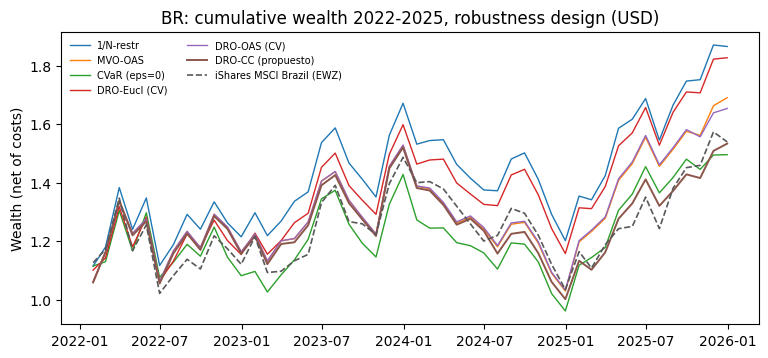

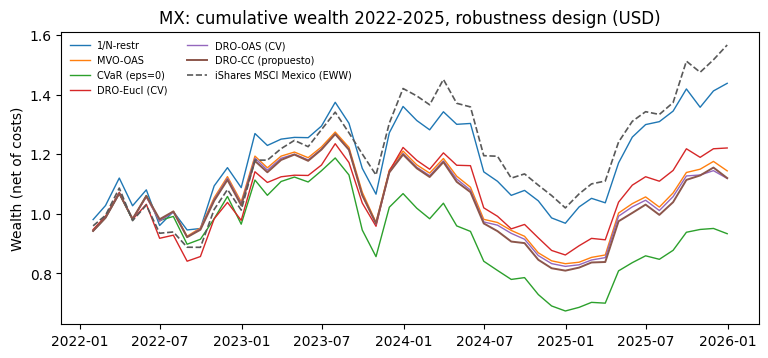

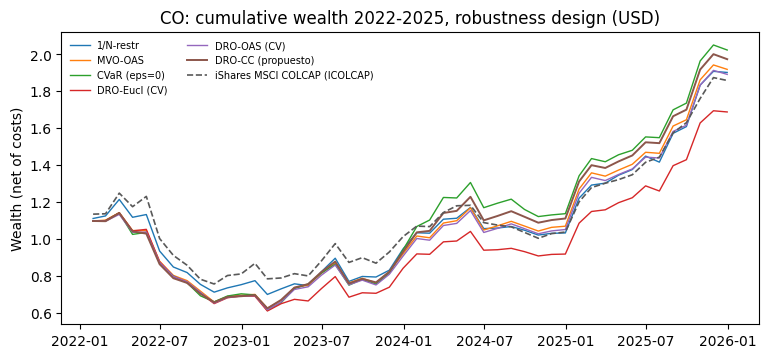

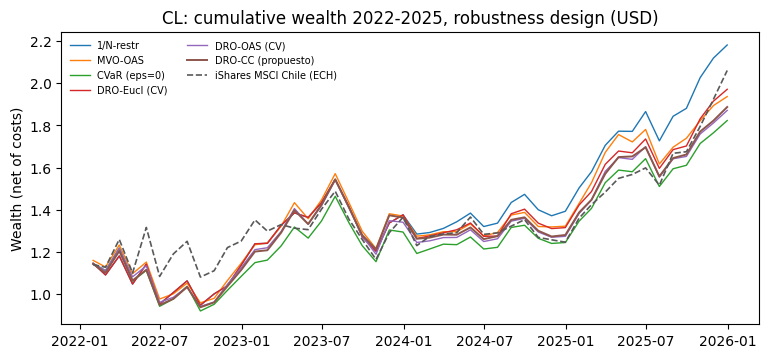

In [ ]:
RUN_F6 = True
if RUN_F6:
  P_ROB = dict(PARAMS, IS_END='2021-12-31', OOS_START='2022-01-01', PHYS_UPDATE='fixed')
  EXPO_ROB, _, _ = build_exposures(R_USD, MEI, AQ, is_start=PARAMS['PRICE_START'], is_end=P_ROB['IS_END'],
                                   spec=PHYS_SPEC_MAIN, min_obs=PARAMS['ENSO_MIN_OBS'])
  print('Spearman PHYS (2014-2021) vs PHYS (2014-2017):', round(EXPO_ROB['PHYS_data'].corr(EXPO['PHYS_data'], method='spearman'), 3))
  MARKETS_ROB = build_markets('PHYS_data', expo=EXPO_ROB, verbose=False)
  RES_ROB = {}
  for c, md_ in MARKETS_ROB.items():
      print(f'=== {c} (robustez) ==='); RES_ROB[c] = run_market(md_, P_ROB, verbose=False)
  PERF_ROB = pd.concat({c: summarize(r, MARKETS_ROB[c]['rf'], P_ROB) for c, r in RES_ROB.items()})
  print('Diseño de robustez (estimación 2014-2021, evaluación 2022-2025):'); display(PERF_ROB.round(3))
  IDX_PERF_ROB = index_table(RES_ROB, IDX_R); display(IDX_PERF_ROB)
  PERF_MAIN_2225 = pd.concat({c: pd.DataFrame({s: perf_metrics(p['net'].loc['2022-01-01':], RF, PARAMS['ALPHA'])
                                               for s, p in r['paths'].items()}).T for c, r in RES.items()})
  print('Diseño principal evaluado en 2022-2025:'); display(PERF_MAIN_2225.round(3))
  INF_ROB = inference_table(RES_ROB, IDX_R, P_=P_ROB)
  print('Inferencia del diseño de robustez (Holm sobre', len(INF_ROB), 'comparaciones):'); display(INF_ROB.round(4))
  POOL_ROB = pd.concat([pooled_bootstrap(RES_ROB, 'DRO-CC (propuesto)', b) for b in ['MVO-OAS', 'DRO-OAS (CV)']], axis=1).T
  display(POOL_ROB.round(4))
  for c in RES_ROB: fig_wealth(RES_ROB[c], f'{c}: cumulative wealth 2022-2025, robustness design (USD)', f'wealth_rob_{c}.png',
                               index_r=IDX_R.get(c), index_label=INDEX_META[c][0])

### F7. Exportación de tablas (LaTeX) y procedencia de datos

In [ ]:
os.makedirs('tables', exist_ok=True)
params_table().to_latex('tables/params.tex', index=False)
PERF.round(3).to_latex('tables/performance.tex'); INF.round(4).to_latex('tables/inference.tex')
POOL.round(4).to_latex('tables/pooled.tex'); BLOCKS.round(4).to_latex('tables/block_sensitivity.tex')
EXPO.round(3).to_latex('tables/exposures.tex'); WSI_REGIONS.round(3).to_latex('tables/aqueduct_regions.tex', index=False)
CARBON_PROV.to_latex('tables/carbon_sources.tex', index=False); PRICE_REPORT.to_latex('tables/price_series.tex')
CARBON_AUDIT.round(3).to_latex('tables/carbon_audit.tex', index=False)
ENSO_DIAG.round(3).to_latex('tables/enso_diagnostics.tex'); DISP.round(3).to_latex('tables/phys_dispersion.tex')
pd.DataFrame(EPS_SUM).T.round(3).to_latex('tables/eps_choice.tex'); BITE.round(1).to_latex('tables/constraint_bite.tex')
pd.DataFrame(CHK).T.to_latex('tables/closed_form_check.tex')
for c in AVGW: AVGW[c].to_latex(f'tables/avg_weights_{c}.tex')
for c in FEAS: FEAS[c].round(3).to_latex(f'tables/feasible_{c}.tex')
IDX_PERF.to_latex('tables/index_performance.tex'); PHYS_PATH.round(3).to_latex('tables/phys_path.tex')
if 'PERF_ROB' in globals():
    PERF_ROB.round(3).to_latex('tables/performance_robustness.tex'); INF_ROB.round(4).to_latex('tables/inference_robustness.tex')
    PERF_MAIN_2225.round(3).to_latex('tables/performance_main_2022_2025.tex'); IDX_PERF_ROB.to_latex('tables/index_performance_robustness.tex')
if 'ABL' in globals():
    for c in ABL: ABL[c].round(3).to_latex(f'tables/ablations_{c}.tex')
    for c in FRONT: FRONT[c].round(3).to_latex(f'tables/eps_frontier_{c}.tex')
    ALT.round(3).to_latex('tables/phys_alternatives.tex')
print('Tablas exportadas en ./tables')

Tablas exportadas en ./tables


## §G. Anexo para la respuesta a los árbitros: especificación original del manuscrito
Este anexo reproduce, con los mismos datos, restricciones y costes, la especificación original del manuscrito, para documentar en la carta de respuesta las diferencias con el modelo propuesto. No interviene en §F.

Estrategia DRO-KF del manuscrito (Ec. 17). Con ventana móvil de `WINDOW` = 36 meses, medida uniforme y radio fijo $\varepsilon_m$ de la Tabla 5 del manuscrito, resuelve
$$\min_{w\in\mathcal W_t}\ \operatorname{CVaR}^{\hat P}_\alpha(\ell_w)+\varepsilon_m\,\|w\|_2 .$$
Por la proposición de §7 con $G=I$, el peor caso exacto de Wasserstein-2 con coste euclidiano es $\operatorname{CVaR}+(\varepsilon/\sqrt\alpha)\|w\|_2$: la Ec. (17) omite el factor $\alpha^{-1/2}$ ($\approx4{,}47$ con $\alpha=0{,}05$), de modo que su radio efectivo es $\sqrt\alpha\,\varepsilon_m$. Interpretación económica: con métrica euclidiana, $\|w\|_2$ es una penalización de concentración, minimizada por los pesos iguales en el símplex ($\|w\|_2^2\ge1/N$), por lo que la estrategia tiende hacia la cartera 1/N restringida a medida que crece $\varepsilon_m$.

Radio del manuscrito (Ec. 12). $\varepsilon_t=\varepsilon_{\min}+\kappa_1\operatorname{tr}(P_{t\mid t})+\kappa_2\sqrt{(\hat x_{t\mid t}-\bar x)^\top Q^{+}(\hat x_{t\mid t}-\bar x)}$, con el estado normalizado por min–max sobre la muestra de estimación del manuscrito (2014–2022; evaluación 2023–2025) y transformado por un logit acotado. Se reportan: (i) la participación de cada término en $\varepsilon_t$; como $\operatorname{tr}(P_{t\mid t})$ converge a su valor de Riccati con independencia de los datos (§3), la variación del radio proviene del término de Mahalanobis; (ii) los valores fuera del dominio del logit, separando los ceros estructurales del precio del carbono (meses sin precio explícito, en los que $\operatorname{logit}(0)$ no está definido) de las excursiones fuera de $[0,1]$ fuera de muestra, que son las que el soporte acotado no anticipa; (iii) el número de condición de $Q$, que justifica la pseudoinversa $Q^{+}$ cuando una componente es constante; y (iv) el número de meses en que $|\text{MEI}|/3>0{,}8$, el umbral de activación ENSO del manuscrito, que exige $|\text{MEI}|>2{,}4$.

### G1. Estrategia DRO-KF del manuscrito frente al modelo propuesto

In [ ]:
EPS_PAPER = {'BR': 1.529, 'MX': 1.037, 'CO': 1.345, 'CL': 1.338}   # Tabla 5 del manuscrito
RES_KF = {}
for c, md_ in MARKETS.items():
    print(f'=== {c} (DRO-KF manuscrito) ==='); RES_KF[c] = run_market(md_, PARAMS, strategies=['DRO-KF manuscrito'],
                                                                  verbose=False, paper_eps=EPS_PAPER[c])
_cmp = {}
for c in RES:
    paths = {**{s: RES[c]['paths'][s] for s in ['DRO-CC (propuesto)', 'MVO-OAS', '1/N-restr']},
             'DRO-KF manuscrito': RES_KF[c]['paths']['DRO-KF manuscrito']}
    wts = {**{s: RES[c]['weights'][s] for s in ['DRO-CC (propuesto)', 'MVO-OAS', '1/N-restr']},
           'DRO-KF manuscrito': RES_KF[c]['weights']['DRO-KF manuscrito']}
    for s, p_ in paths.items():
        m = perf_metrics(p_['net'], RF, PARAMS['ALPHA']); m['Neff medio'] = (1 / (wts[s] ** 2).sum(axis=1)).mean()
        m['radio efectivo sqrt(alpha) eps'] = np.sqrt(PARAMS['ALPHA']) * EPS_PAPER[c] if s == 'DRO-KF manuscrito' else np.nan
        _cmp[(c, s)] = m
KF_PERF = pd.DataFrame(_cmp).T; display(KF_PERF.round(3))
INF_KF = {}
for c in RES:
    a = RES[c]['paths']['DRO-CC (propuesto)']['net']; b = RES_KF[c]['paths']['DRO-KF manuscrito']['net'].reindex(a.index)
    bt = bootstrap_differences(a.values, b.values, RF.reindex(a.index).values, B=PARAMS['BOOT_B'],
                               block=PARAMS['BOOT_BLOCK'], alpha=PARAMS['ALPHA'])
    dm = dm_hln(downside_loss(a.values), downside_loss(b.values))
    INF_KF[c] = {**{f'{i} | {j}': bt.loc[i, j] for i in ['Delta CVaR', 'Delta Sharpe']
                    for j in ['estimación', 'IC95_inf', 'IC95_sup', 'p_bilateral']},
                 'bloque': int(bt['bloque'].iloc[0]), 'DM_HLN': dm['DM_HLN'], 'DM p_bilateral': dm['p_bilateral']}
INF_KF = pd.DataFrame(INF_KF).T
for k in ['Delta CVaR | p_bilateral', 'Delta Sharpe | p_bilateral', 'DM p_bilateral']:
    INF_KF[k + ' (Holm)'] = holm_adjust(INF_KF[k].values)
print('Delta = DRO-CC menos DRO-KF manuscrito:'); display(INF_KF.round(4))

=== BR (DRO-KF manuscrito) ===
=== MX (DRO-KF manuscrito) ===
=== CO (DRO-KF manuscrito) ===
=== CL (DRO-KF manuscrito) ===


Ret. geom. anual (%)  Vol. anual (%)  Sharpe (anual)  CVaR5% mensual (%)  CVaR10% mensual (%)  MaxDD (%)  N meses  Neff medio  radio efectivo sqrt(alpha) eps
BR DRO-CC (propuesto)                 5.463          30.658           0.246              17.803               13.836    -41.956     96.0       3.948                             NaN
   MVO-OAS                            8.621          31.507           0.343              18.738               14.596    -42.181     96.0       4.174                             NaN
   1/N-restr                         10.089          32.826           0.387              19.446               14.629    -47.399     96.0       9.516                             NaN
   DRO-KF manuscrito                  9.714          32.540           0.377              19.223               14.484    -46.878     96.0       9.430                           0.342
MX DRO-CC (propuesto)                 4.408          26.607           0.203              16.774               13.096    -38.449     96.0       4.108                             NaN
   MVO-OAS                            5.603          27.375           0.248              17.650               13.471    -40.043     96.0       4.950                             NaN
   1/N-restr                          7.801          28.398           0.325              18.481               13.776    -42.702     96.0       7.885                             NaN
   DRO-KF manuscrito                  7.414          27.947           0.312              18.272               13.617    -42.490     96.0       7.688                           0.232
CO DRO-CC (propuesto)                 7.143          26.105           0.305              16.943               12.671    -43.429     96.0       3.931                             NaN
   MVO-OAS                            6.042          26.100           0.265              16.534               12.540    -44.854     96.0       4.103                             NaN
   1/N-restr                          7.284          26.612           0.308              16.998               12.739    -42.048     96.0       8.645                             NaN
   DRO-KF manuscrito                  7.295          26.429           0.308              16.952               12.655    -41.615     96.0       8.548                           0.301
CL DRO-CC (propuesto)                 0.336          27.515           0.060              16.671               14.094    -59.712     96.0       4.218                             NaN
   MVO-OAS                            0.320          27.866           0.062              17.583               14.106    -60.776     96.0       4.575                             NaN
   1/N-restr                          3.081          27.829           0.158              15.658               13.369    -59.257     96.0       7.458                             NaN
   DRO-KF manuscrito                  2.516          27.649           0.137              15.790               13.453    -59.303     96.0       7.366                           0.299

Delta = DRO-CC menos DRO-KF manuscrito:


,Delta CVaR | estimación,Delta CVaR | IC95_inf,Delta CVaR | IC95_sup,Delta CVaR | p_bilateral,Delta Sharpe | estimación,Delta Sharpe | IC95_inf,Delta Sharpe | IC95_sup,Delta Sharpe | p_bilateral,bloque,DM_HLN,DM p_bilateral,Delta CVaR | p_bilateral (Holm),Delta Sharpe | p_bilateral (Holm),DM p_bilateral (Holm)
BR,-0.0142,-0.0498,0.0140,0.575,-0.1309,-0.3112,0.0152,0.077,4.0,-0.8276,0.4100,1.0,0.308,1.0
MX,-0.0150,-0.0498,0.0115,0.477,-0.1092,-0.3086,0.0587,0.189,2.0,-0.5839,0.5607,1.0,0.567,1.0
CO,-0.0001,-0.0244,0.0268,0.922,-0.0029,-0.1946,0.1982,0.985,3.0,0.4328,0.6661,1.0,0.985,1.0
CL,0.0088,-0.0154,0.0362,0.556,-0.0776,-0.2267,0.0634,0.308,3.0,0.5246,0.6011,1.0,0.616,1.0


### G2. Radio del manuscrito: descomposición, dominio del logit y umbral ENSO

BR | valores fuera del dominio del logit:


,fuera del dominio (total),fuera del dominio (OOS),ceros estructurales (total),ceros estructurales (OOS),excursiones (total),excursiones (OOS)
P_C,144,36,144,36,0,0
T_anom,5,3,0,0,5,3
ENSO,0,0,0,0,0,0
Comm,2,0,0,0,2,0


MX | valores fuera del dominio del logit:


,fuera del dominio (total),fuera del dominio (OOS),ceros estructurales (total),ceros estructurales (OOS),excursiones (total),excursiones (OOS)
P_C,0,0,0,0,0,0
T_anom,2,0,0,0,2,0
ENSO,0,0,0,0,0,0
Comm,2,0,0,0,2,0


CO | valores fuera del dominio del logit:


,fuera del dominio (total),fuera del dominio (OOS),ceros estructurales (total),ceros estructurales (OOS),excursiones (total),excursiones (OOS)
P_C,36,0,36,0,0,0
T_anom,7,5,0,0,7,5
ENSO,0,0,0,0,0,0
Comm,2,0,0,0,2,0


CL | valores fuera del dominio del logit:


,fuera del dominio (total),fuera del dominio (OOS),ceros estructurales (total),ceros estructurales (OOS),excursiones (total),excursiones (OOS)
P_C,36,0,36,0,0,0
T_anom,5,3,0,0,5,3
ENSO,0,0,0,0,0,0
Comm,8,6,0,0,8,6


,rho(Phi) VAR(1),cond(Q),pares excluidos por faltantes,participación traza,participación Mahalanobis,eps_t medio OOS,eps_t mín OOS,eps_t máx OOS,"meses |MEI|/3 > 0,8 (total)","meses |MEI|/3 > 0,8 (OOS)"
BR,0.9795,inf,0.0,0.0056,0.9640,0.4090,0.0904,0.9718,0.0,0.0
MX,0.9106,342.7028,24.0,0.0049,0.9781,1.4635,1.2637,1.5956,0.0,0.0
CO,0.9804,24.6636,0.0,0.0041,0.9835,0.8249,0.5554,1.2596,0.0,0.0
CL,0.9816,41.5953,0.0,0.0040,0.9837,0.8791,0.5785,1.4049,0.0,0.0


|MEI| máximo en 2023-2025 = 1.22


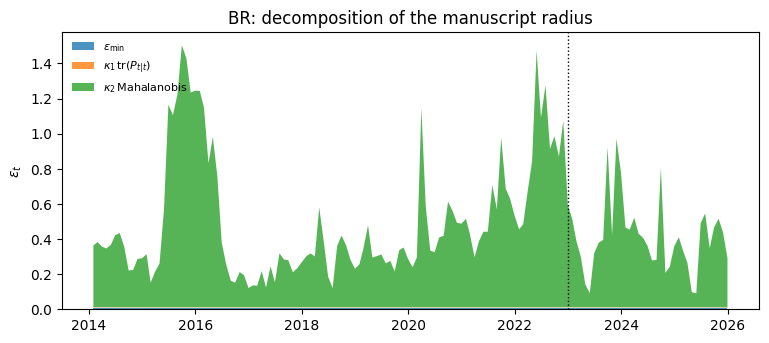

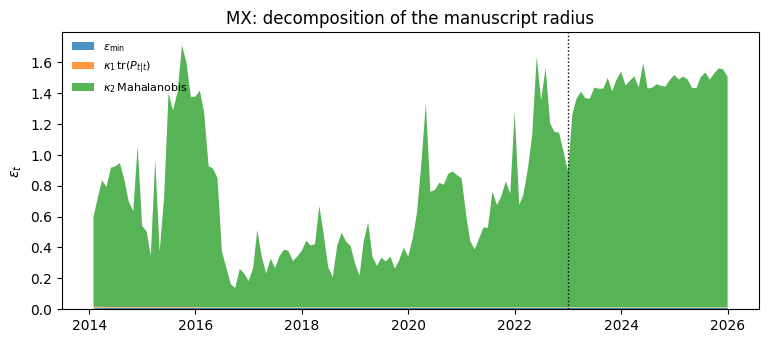

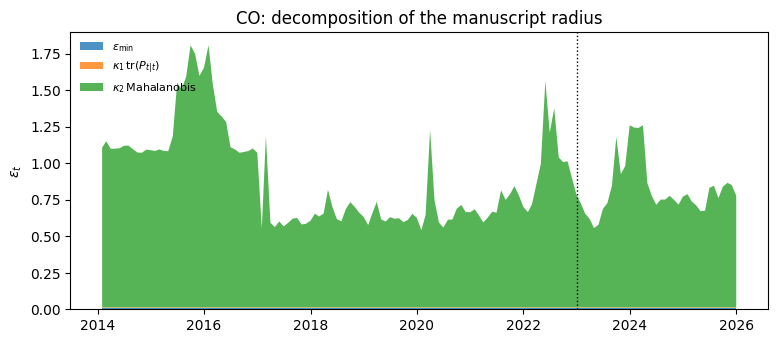

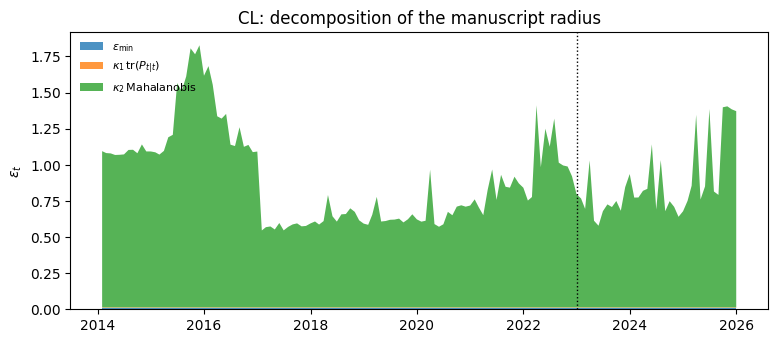

In [ ]:
PAPER_IS_END = '2022-12-31'      # muestra de estimación del manuscrito (evaluación 2023-2025)
REP = {}; REP_SUM = {}
for c, md_ in MARKETS.items():
    REP[c] = replicate_paper_radius(md_['Z_raw'].loc[PARAMS['PRICE_START']:PARAMS['OOS_END']], PAPER_IS_END)
    d = REP[c]['decomposition']; oos = d.index > pd.Timestamp(PAPER_IS_END)
    REP_SUM[c] = {'rho(Phi) VAR(1)': REP[c]['rho'], 'cond(Q)': REP[c]['cond_Q'],
                  'pares excluidos por faltantes': REP[c]['pares_excluidos'],
                  'participación traza': (d.trace_term / d.eps_t).mean(), 'participación Mahalanobis': (d.mahal_term / d.eps_t).mean(),
                  'eps_t medio OOS': d.loc[oos, 'eps_t'].mean(), 'eps_t mín OOS': d.loc[oos, 'eps_t'].min(),
                  'eps_t máx OOS': d.loc[oos, 'eps_t'].max(),
                  'meses |MEI|/3 > 0,8 (total)': REP[c]['enso_threshold_months'][0],
                  'meses |MEI|/3 > 0,8 (OOS)': REP[c]['enso_threshold_months'][1]}
    print(c, '| valores fuera del dominio del logit:'); display(REP[c]['viol'])
    fig_radius_decomposition(d, PAPER_IS_END, f'{c}: decomposition of the manuscript radius', f'eps_decomp_{c}.png')
REP_SUM = pd.DataFrame(REP_SUM).T; display(REP_SUM.round(4))
print('|MEI| máximo en 2023-2025 =', round(MEI.loc['2023-01-31':PARAMS['OOS_END']].abs().max(), 2))
os.makedirs('tables', exist_ok=True)
KF_PERF.round(3).to_latex('tables/annex_manuscript_strategy.tex'); INF_KF.round(4).to_latex('tables/annex_manuscript_inference.tex')
REP_SUM.round(4).to_latex('tables/annex_manuscript_radius.tex')
pd.concat({c: REP[c]['viol'] for c in REP}).to_latex('tables/annex_logit_domain.tex')

### G3. Lectura para la carta de respuesta
Las cifras de esta sección deben citarse tal como resultan de la ejecución. Los puntos que el anexo permite documentar son: el factor $\alpha^{-1/2}$ ausente en la Ec. (17) y su consecuencia (radio efectivo menor y cercanía estructural a 1/N); la dependencia del radio de la Ec. (12) del término de Mahalanobis; los valores fuera del dominio del logit, distinguiendo los ceros estructurales de las excursiones; y la frecuencia, posiblemente nula, de activación del umbral ENSO del manuscrito en la muestra.

## Referencias
Blanchet, J., y Murthy, K. (2019). Quantifying distributional model risk via optimal transport. *Mathematics of Operations Research, 44*(2), 565–600.

Cashin, P., Mohaddes, K., y Raissi, M. (2017). Fair weather or foul? The macroeconomic effects of El Niño. *Journal of International Economics, 106*, 37–54.

Chen, Y., Wiesel, A., Eldar, Y. C., y Hero, A. O. (2010). Shrinkage algorithms for MMSE covariance estimation. *IEEE Transactions on Signal Processing, 58*(10), 5016–5029.

Diebold, F. X., y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.

Durbin, J., y Koopman, S. J. (2012). *Time series analysis by state space methods* (2.ª ed.). Oxford University Press.

Gao, R., y Kleywegt, A. (2023). Distributionally robust stochastic optimization with Wasserstein distance. *Mathematics of Operations Research, 48*(2), 603–655.

Harvey, D., Leybourne, S., y Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting, 13*(2), 281–291.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.

Hong, H., Li, F. W., y Xu, J. (2019). Climate risks and market efficiency. *Journal of Econometrics, 208*(1), 265–281. https://doi.org/10.1016/j.jeconom.2018.09.015

Kuhn, D., Mohajerin Esfahani, P., Nguyen, V. A., y Shafieezadeh-Abadeh, S. (2019). Wasserstein distributionally robust optimization: Theory and applications in machine learning. En *Operations Research & Management Science in the Age of Analytics* (INFORMS TutORials in Operations Research, pp. 130–166). https://doi.org/10.1287/educ.2019.0198

Kuzma, S., Bierkens, M. F. P., Lakshman, S., Luo, T., Saccoccia, L., Sutanudjaja, E. H., y Van Beek, R. (2023). *Aqueduct 4.0: Updated decision-relevant global water risk indicators* (Technical note). World Resources Institute. https://doi.org/10.46830/writn.23.00061

Nadaraya, E. A. (1964). On estimating regression. *Theory of Probability & Its Applications, 9*(1), 141–142.

Newey, W. K., y West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica, 55*(3), 703–708.

Patton, A., Politis, D. N., y White, H. (2009). Correction to "Automatic block-length selection for the dependent bootstrap" by D. Politis and H. White. *Econometric Reviews, 28*(4), 372–375.

Politis, D. N., y Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association, 89*(428), 1303–1313.

Politis, D. N., y White, H. (2004). Automatic block-length selection for the dependent bootstrap. *Econometric Reviews, 23*(1), 53–70.

Reglamento Delegado (UE) 2020/1818 de la Comisión, de 17 de julio de 2020, por el que se completa el Reglamento (UE) 2016/1011 en lo relativo a las normas mínimas aplicables a los índices de referencia de transición climática de la UE y a los índices de referencia de la UE armonizados con el Acuerdo de París.

Rockafellar, R. T., y Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk, 2*(3), 21–41.

Shumway, R. H., y Stoffer, D. S. (1982). An approach to time series smoothing and forecasting using the EM algorithm. *Journal of Time Series Analysis, 3*(4), 253–264.

Watson, G. S. (1964). Smooth regression analysis. *Sankhyā: The Indian Journal of Statistics, Series A, 26*(4), 359–372.

Fuentes de datos: NOAA Physical Sciences Laboratory (MEI v2; GISTEMP v4); Banco Mundial, Carbon Pricing Dashboard; WRI Aqueduct 4.0; Yahoo Finance; Resoluciones DIAN 000007 de 2021 y 000008 de 2025; Ley 20.780 de Chile; Ley 15.042 de 2024 de Brasil.